## Analisi Esplorativa (EDA)

### Import

In [20]:
library(dplyr)
library(readr)
library(ggplot2)
library(tidyr)
library(psych)


# Impostazioni grafiche globali (equivalente a sns.set_style e plt.rcParams)
theme_set(theme_bw() + 
          theme(plot.title = element_text(face = "bold", size = 18),
                plot.subtitle = element_text(size = 17)))
options(repr.plot.width = 18, repr.plot.height = 10)

## Caricamento dataset
_NB_. `max_glu_serum` e `A1Cresult` usano la stringa `None` non come valore nullo ma come espressione di non misurazione

In [21]:
df <- read_csv('diabetic_data.csv', na = c("?"), show_col_types = FALSE)

cat(sprintf("Dimensioni del dataset: %s righe x %s colonne\n", 
            format(nrow(df), big.mark=","), ncol(df)))

Dimensioni del dataset: 101,766 righe x 50 colonne


### Info e sample

In [22]:
glimpse(df)

Rows: 101,766
Columns: 50
$ encounter_id               <dbl> 2278392, 149190, 64410, 500364, 16680, 3575…
$ patient_nbr                <dbl> 8222157, 55629189, 86047875, 82442376, 4251…
$ race                       <chr> "Caucasian", "Caucasian", "AfricanAmerican"…
$ gender                     <chr> "Female", "Female", "Female", "Male", "Male…
$ age                        <chr> "[0-10)", "[10-20)", "[20-30)", "[30-40)", …
$ weight                     <chr> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA,…
$ admission_type_id          <dbl> 6, 1, 1, 1, 1, 2, 3, 1, 2, 3, 1, 2, 1, 1, 3…
$ discharge_disposition_id   <dbl> 25, 1, 1, 1, 1, 1, 1, 1, 1, 3, 1, 1, 3, 6, …
$ admission_source_id        <dbl> 1, 7, 7, 7, 7, 2, 2, 7, 4, 4, 7, 4, 7, 7, 2…
$ time_in_hospital           <dbl> 1, 3, 2, 2, 1, 3, 4, 5, 13, 12, 9, 7, 7, 10…
$ payer_code                 <chr> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA,…
$ medical_specialty          <chr> "Pediatrics-Endocrinology", NA, NA, NA, NA,…
$ num_lab_proc

In [23]:
head(df)

encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,⋯,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
2278392,8222157,Caucasian,Female,[0-10),NA,6,25,1,1,⋯,No,No,No,No,No,No,No,No,No,NO
149190,55629189,Caucasian,Female,[10-20),NA,1,1,7,3,⋯,No,Up,No,No,No,No,No,Ch,Yes,>30
64410,86047875,AfricanAmerican,Female,[20-30),NA,1,1,7,2,⋯,No,No,No,No,No,No,No,No,Yes,NO
500364,82442376,Caucasian,Male,[30-40),NA,1,1,7,2,⋯,No,Up,No,No,No,No,No,Ch,Yes,NO
16680,42519267,Caucasian,Male,[40-50),NA,1,1,7,1,⋯,No,Steady,No,No,No,No,No,Ch,Yes,NO
35754,82637451,Caucasian,Male,[50-60),NA,2,1,2,3,⋯,No,Steady,No,No,No,No,No,No,Yes,>30


Il dataset contiene **50 colonne**: 13 numeriche e 37 di tipo testuale/categoriale. Tra queste, `encounter_id` e `patient_nbr` sono identificativi (rispettivamente del ricovero e del paziente) e non vere variabili predittive. 

Quanti encounter distinti e quanti pazienti distinti sono presenti?

In [24]:
cat("Ricoveri (encounter_id) unici: ", length(unique(df$encounter_id)), "\n")
cat("Pazienti unici (patient_nbr): ", length(unique(df$patient_nbr)), "\n")
cat("Righe duplicate (intere): ", sum(duplicated(df)), "\n")

Ricoveri (encounter_id) unici:  101766 
Pazienti unici (patient_nbr):  71518 


Righe duplicate (intere):  0 


Il numero di pazienti unici (**71.518**) è inferiore al numero di encounter (**101.766**): significa che **molti pazienti compaiono più volte** nel dataset, con ricoveri ripetuti nel periodo 1999-2008

## Struttura Dataset

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  1.000   1.000   1.000   1.423   1.000  40.000 
Percentuale di pazienti con piu' di un encounter: 23.5%


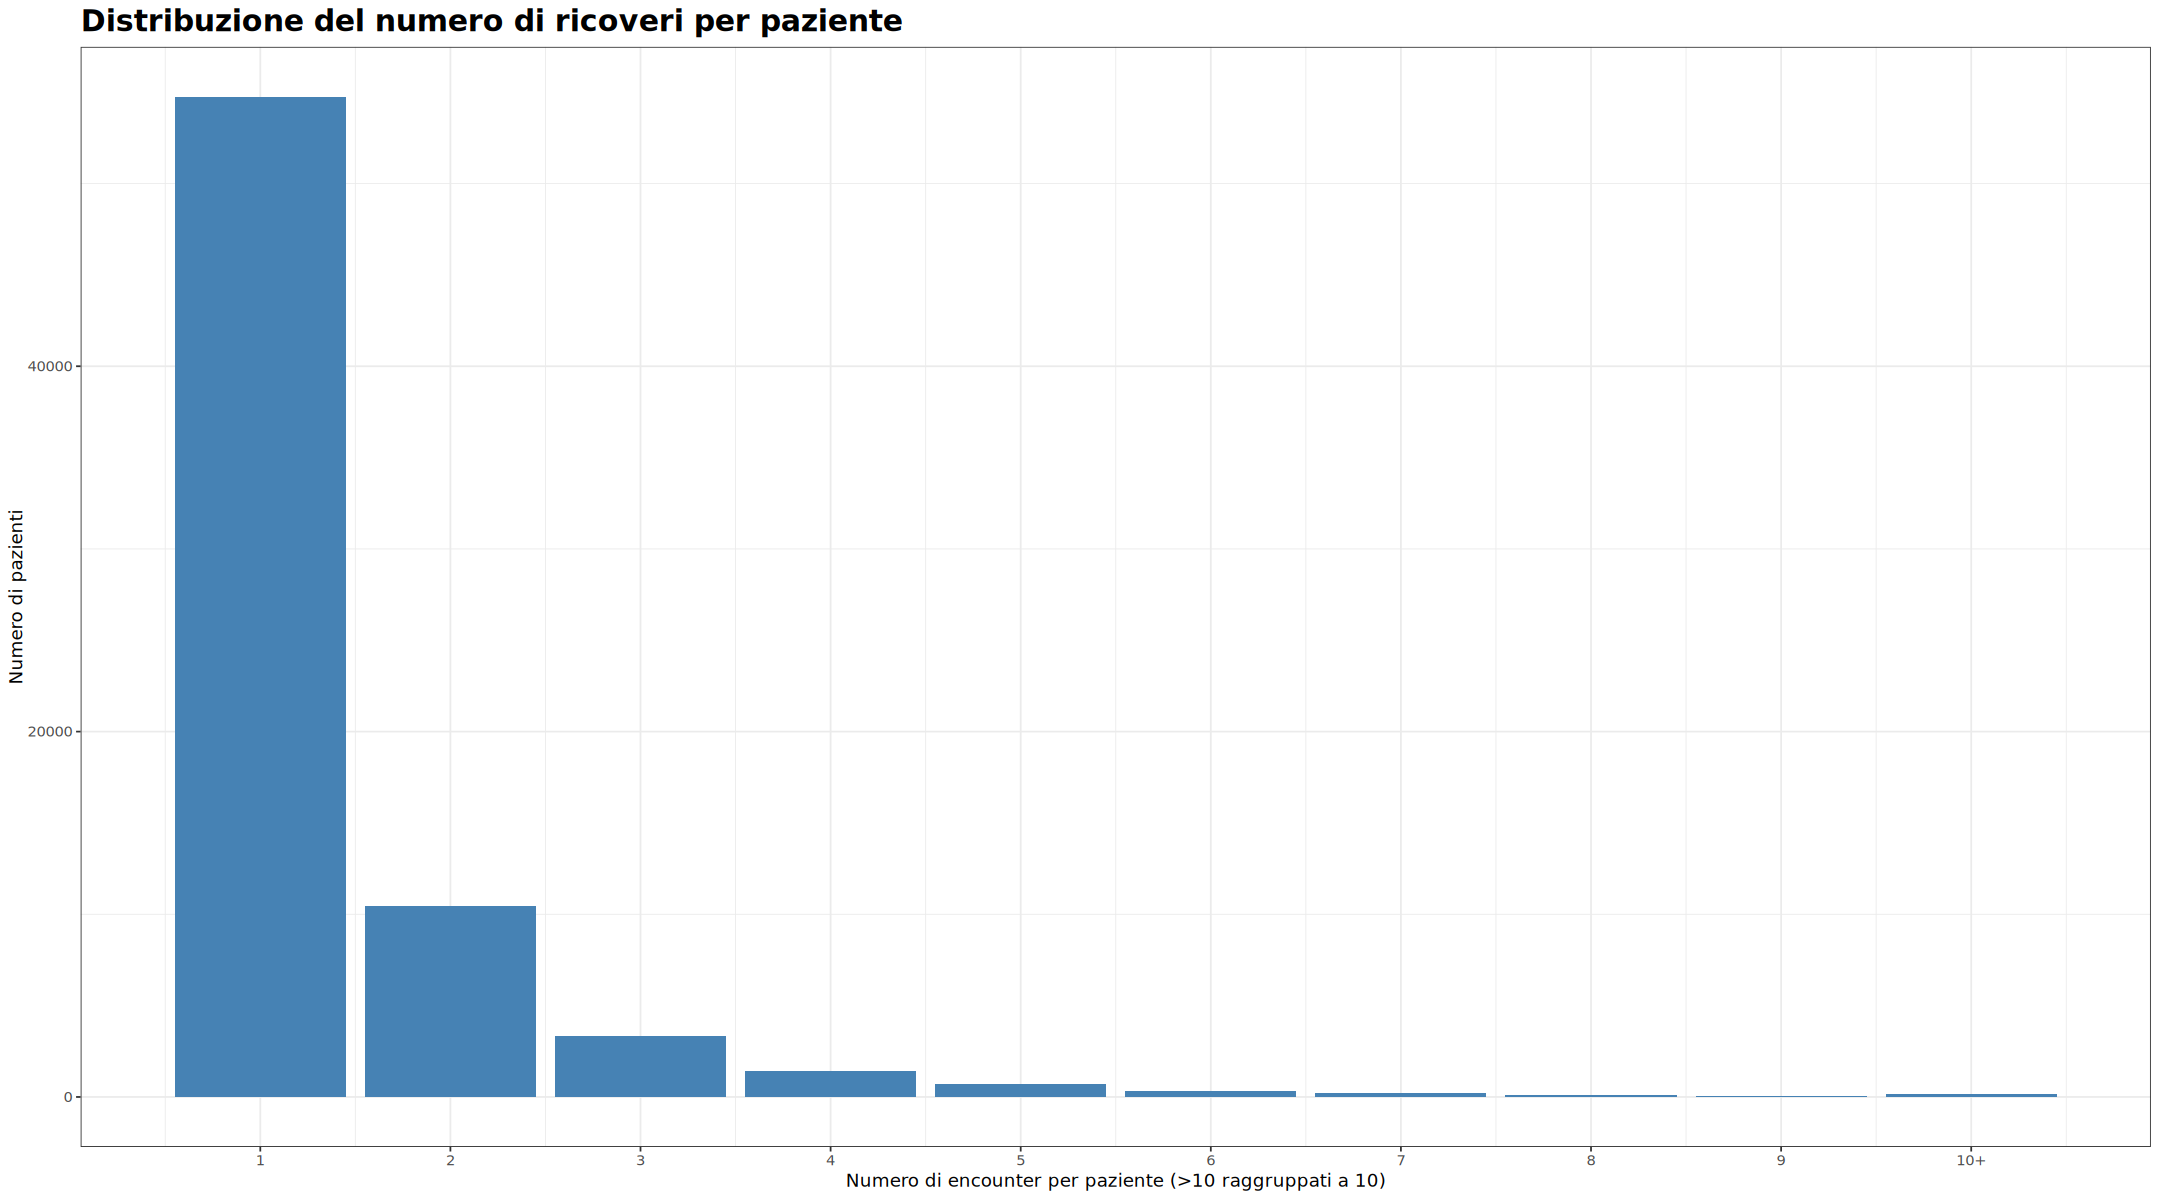

In [25]:
encounters_per_patient <- df %>% 
  group_by(patient_nbr) %>% 
  summarise(count = n()) %>% 
  pull(count)

print(summary(encounters_per_patient))

df_plot <- data.frame(encounters = pmin(encounters_per_patient, 10))

ggplot(df_plot, aes(x = encounters)) +
  geom_bar(fill = "steelblue") +
  scale_x_continuous(breaks = 1:10, labels = c(1:9, "10+")) +
  labs(x = 'Numero di encounter per paziente (>10 raggruppati a 10)',
       y = 'Numero di pazienti',
       title = 'Distribuzione del numero di ricoveri per paziente')

pct_multi <- mean(encounters_per_patient > 1) * 100
cat(sprintf("Percentuale di pazienti con piu' di un encounter: %.1f%%\n", pct_multi))

## Valori mancanti
I valori mancanti risultano codificati esclusivamente con il simbolo `?`. Calcoliamo numero e percentuale di valori mancanti per ciascuna colonna

In [26]:
missing <- colSums(is.na(df))
missing_pct <- round((missing / nrow(df)) * 100, 2)

missing_table <- data.frame(
  colonna = names(missing), 
  n_missing = missing, 
  pct_missing = missing_pct,
  row.names = NULL
) %>% 
  filter(n_missing > 0) %>% 
  arrange(desc(pct_missing))


missing_table

colonna,n_missing,pct_missing
<chr>,<dbl>,<dbl>
weight,98569,96.86
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


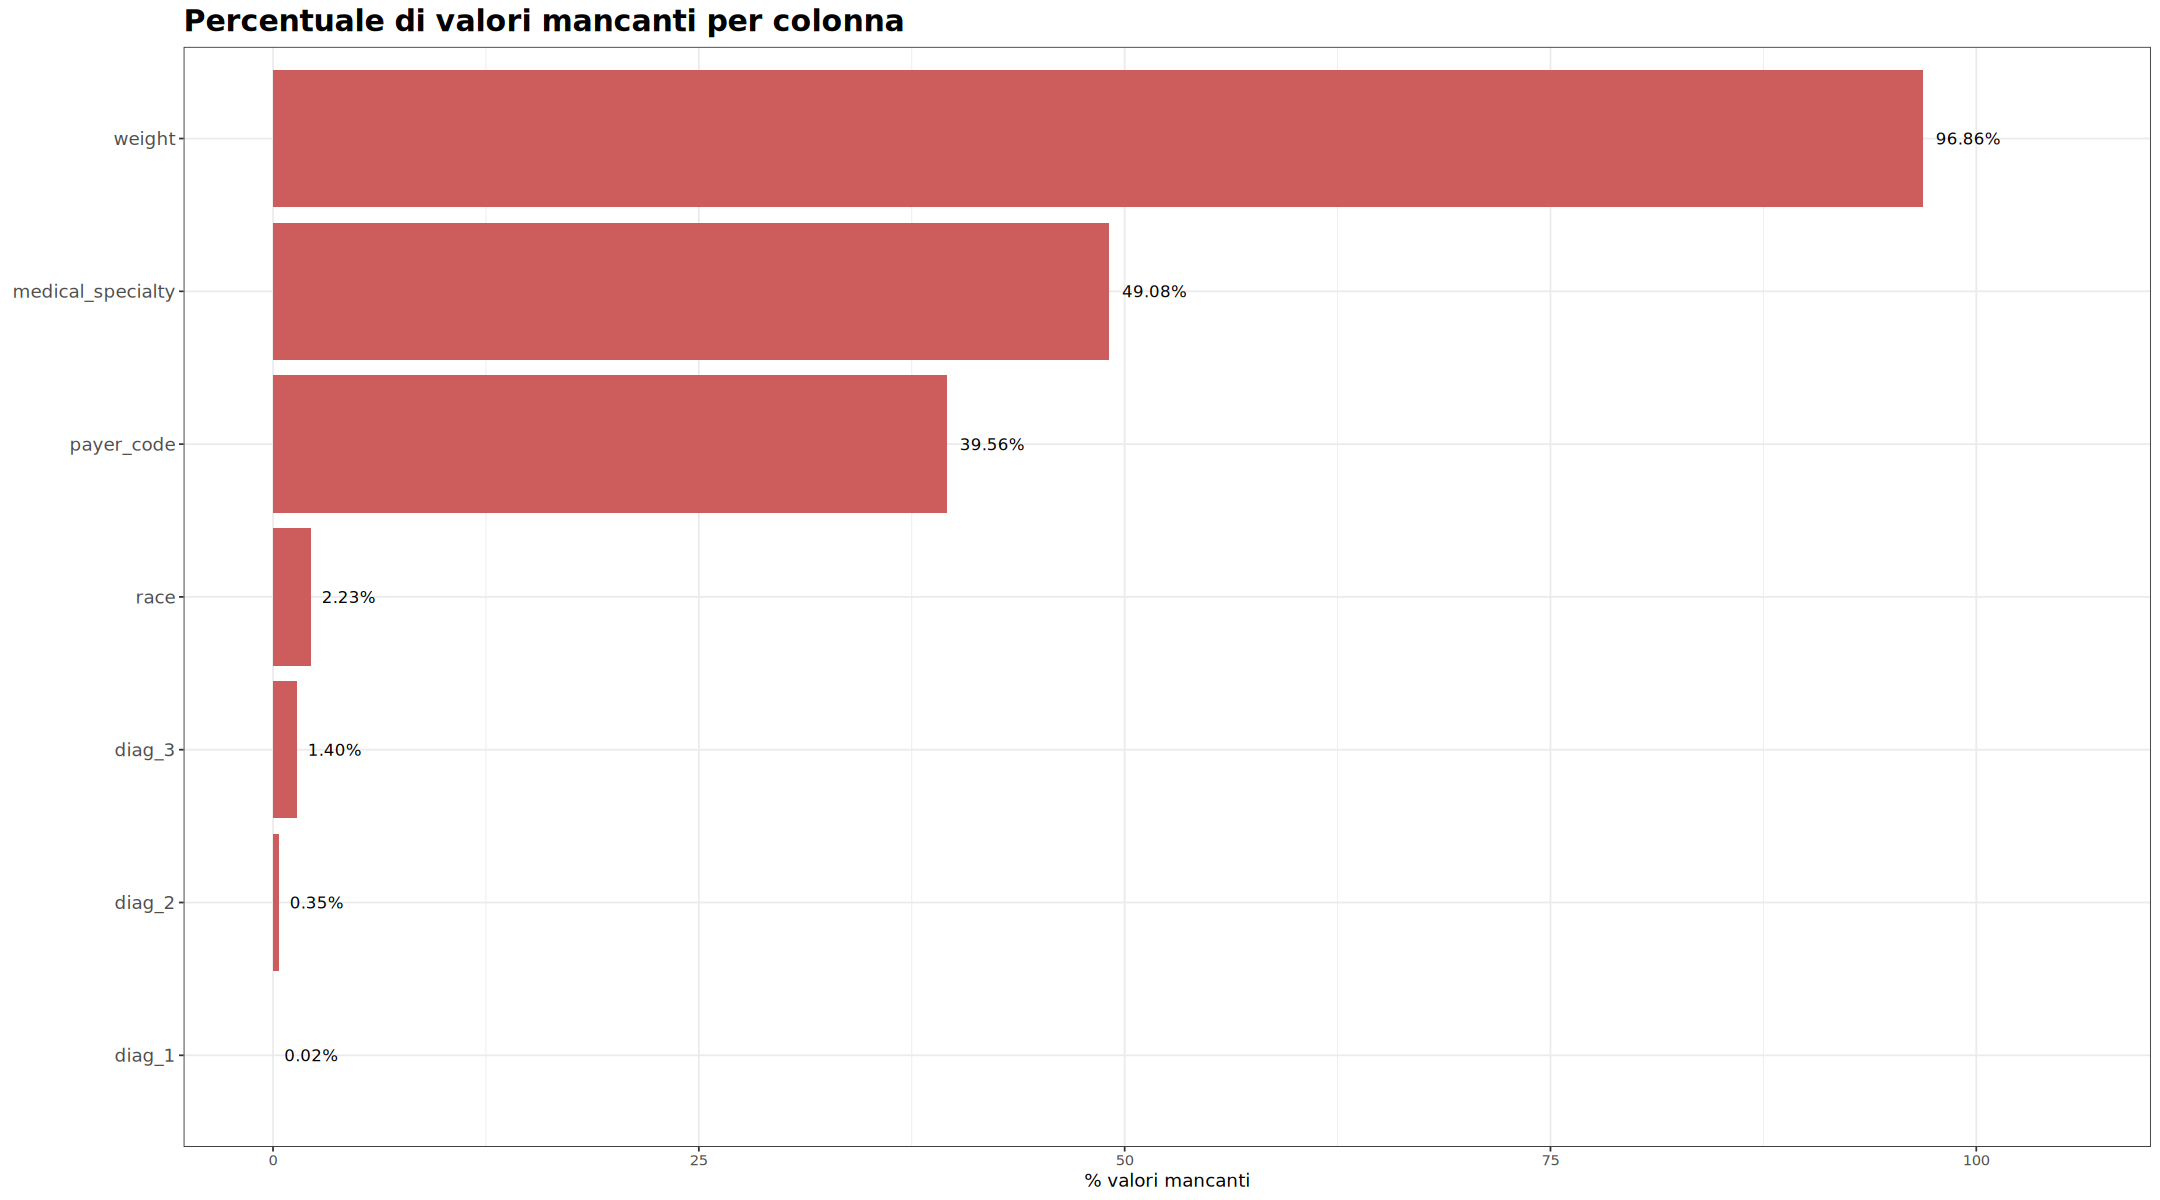

In [27]:
ggplot(missing_table, aes(x = pct_missing, y = reorder(colonna, pct_missing))) +
  geom_col(fill = "indianred") +
  geom_text(aes(label = sprintf("%.2f%%", pct_missing)), hjust = -0.2, size = 3.5) +
  labs(x = '% valori mancanti',
       y = '',
       title = 'Percentuale di valori mancanti per colonna') +
  theme(axis.text.y = element_text(size = 11)) +
  xlim(0, 105) # Estende l'asse x per far spazio alle etichette

**Considerazioni sui valori mancanti:**

- `weight` (96,9% mancante): praticamente inutilizzabile come variabile continua; nella maggior parte degli studi su questo dataset viene eliminata.
- `payer_code` (39,6%) e `medical_specialty` (49,1%): missingness molto elevata; possono essere eliminate oppure trattate come variabili categoriali con una categoria esplicita "Mancante", che a volte è essa stessa informativa (es. specialità non registrata).
- `race` (2,2%): missingness contenuta; può essere imputata con la moda (`Caucasian`) o con una categoria "Unknown".
- `diag_1`, `diag_2`, `diag_3` (0,02%–1,4%): missingness trascurabile.

Nessuna colonna numerica presenta valori mancanti: i missing riguardano esclusivamente variabili categoriali.

## Valori costanti

In [28]:
near_constant <- data.frame(
  colonna = character(), 
  valore_dominante = character(), 
  pct_valore_dominante = numeric(), 
  stringsAsFactors = FALSE
)

for (c in names(df)) {
  freq_table <- sort(table(df[[c]], useNA = "ifany"), decreasing = TRUE)
  top_freq <- as.numeric(freq_table[1] / nrow(df))
  top_val <- names(freq_table)[1]
  
  if (top_freq > 0.99) {
    near_constant <- rbind(near_constant, data.frame(
      colonna = c, 
      valore_dominante = top_val, 
      pct_valore_dominante = round(top_freq * 100, 2)
    ))
  }
}

near_const_df <- near_constant %>% arrange(desc(pct_valore_dominante))
near_const_df

colonna,valore_dominante,pct_valore_dominante
<chr>,<chr>,<dbl>
acetohexamide,No,100.00
troglitazone,No,100.00
examide,No,100.00
citoglipton,No,100.00
glimepiride-pioglitazone,No,100.00
metformin-rosiglitazone,No,100.00
metformin-pioglitazone,No,100.00
glipizide-metformin,No,99.99
tolbutamide,No,99.98


## Variabile target ("readmitted")

La variabile target del dataset è `readmitted`, che indica se un paziente è stato riammesso in ospedale. Assume tre valori:
- `NO`: nessuna riammissione registrata.
- `>30`: riammesso dopo più di 30 giorni.
- `<30`: riammesso entro 30 giorni (solitamente il target critico per le metriche ospedaliere).

Vediamo come si distribuiscono le classi per capire se è un problema sbilanciato.

In [29]:
target_summary <- df %>%
  count(readmitted) %>%
  mutate(percentuale = round(n / sum(n) * 100, 2)) %>%
  arrange(desc(n))

target_summary

readmitted,n,percentuale
<chr>,<int>,<dbl>
NO,54864,53.91
>30,35545,34.93
<30,11357,11.16



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




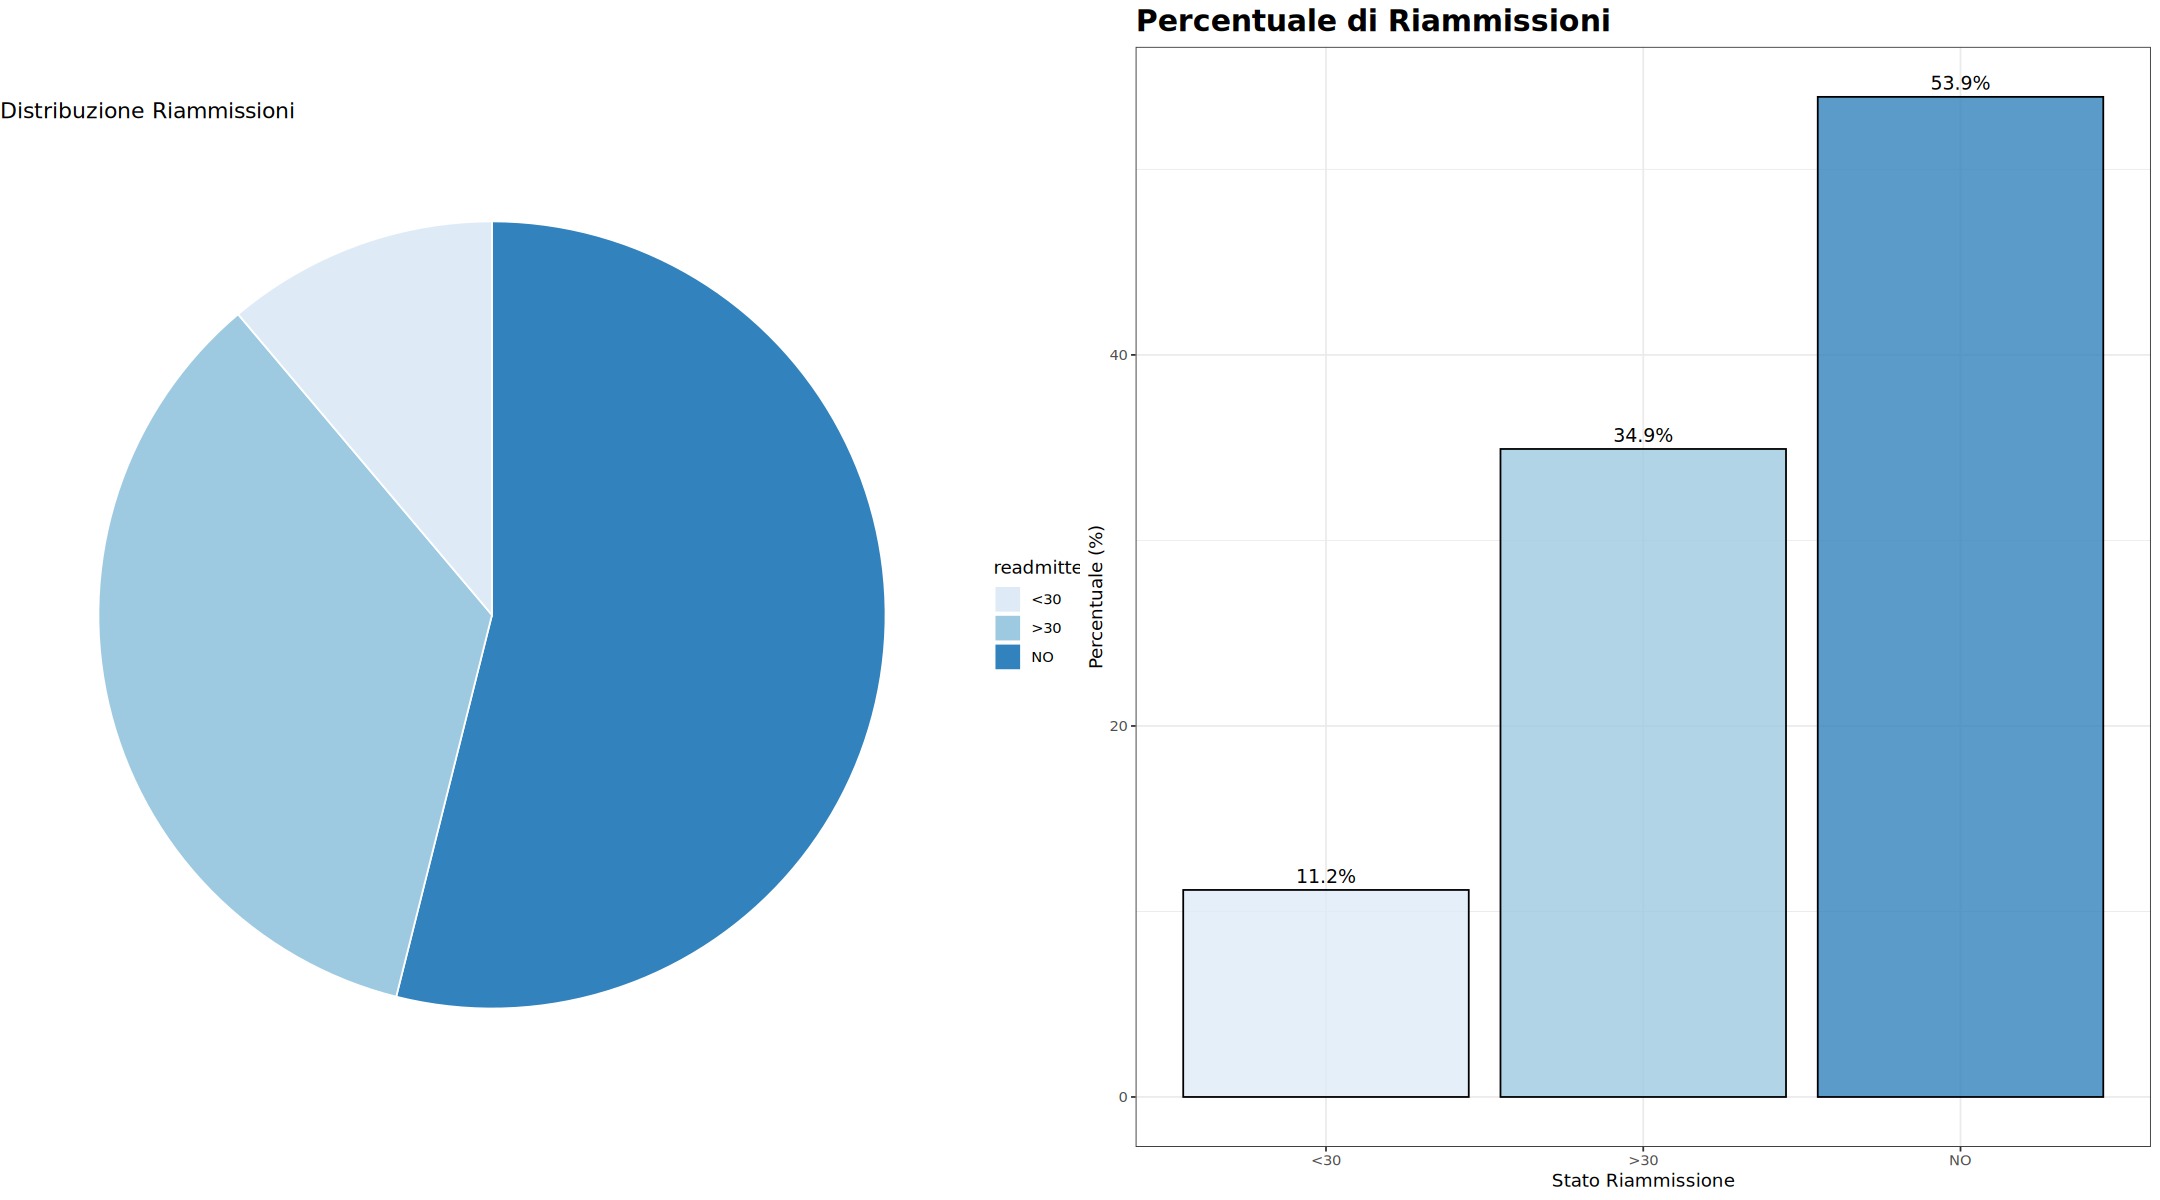

In [30]:
library(gridExtra)

# Creazione del pie chart
p1 <- ggplot(target_summary, aes(x = "", y = n, fill = readmitted)) +
  geom_bar(stat = "identity", width = 1, color = "white") +
  coord_polar("y", start = 0) +
  theme_void() +
  scale_fill_brewer(palette = "Blues") +
  labs(title = "Distribuzione Riammissioni")

# Creazione del bar chart
p2 <- ggplot(target_summary, aes(x = readmitted, y = percentuale, fill = readmitted)) +
  geom_col(color = "black", alpha = 0.8) +
  geom_text(aes(label = sprintf("%.1f%%", percentuale)), vjust = -0.5, size = 4) +
  scale_fill_brewer(palette = "Blues") +
  labs(title = "Percentuale di Riammissioni",
       x = "Stato Riammissione",
       y = "Percentuale (%)") +
  theme(legend.position = "none")

# Affiancare i grafici
grid.arrange(p1, p2, ncol = 2)

La classe di maggiore interesse clinico — la riammissione **entro 30 giorni** (`<30`) — è anche la **meno frequente** (11,2% dei casi): siamo in presenza di uno **sbilanciamento delle classi** che, in un'eventuale fase di modellazione, andrebbe gestito

## Analisi Demografica (`race`, `gender`, `age`)

Esplorazione demografica dei pazienti, partendo da genere ed età, due delle poche variabili anagrafiche complete.

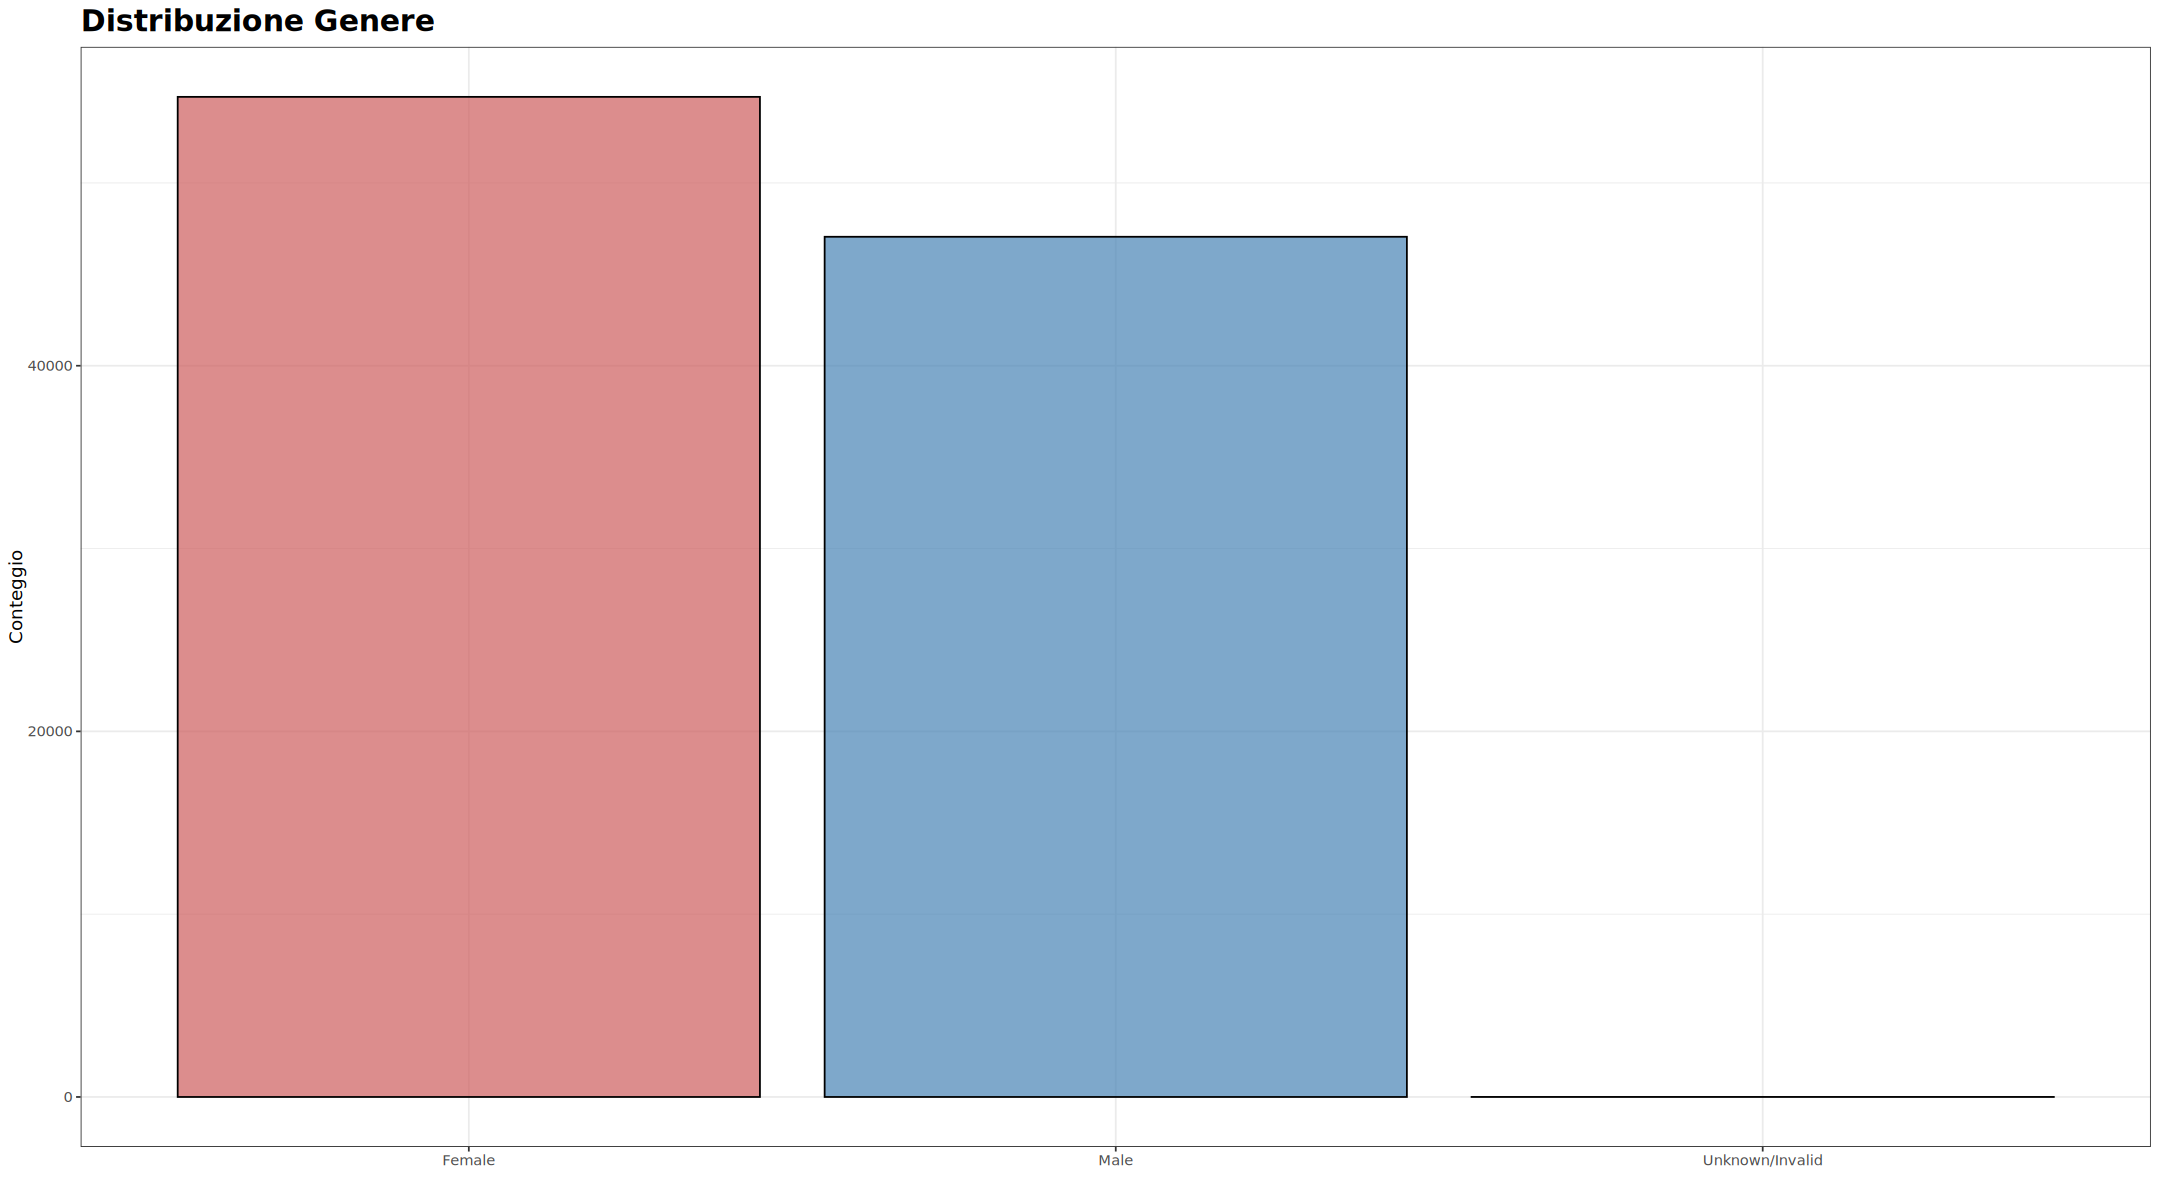

In [31]:
p_gender <- ggplot(df, aes(x = gender, fill = gender)) +
  geom_bar(color = "black", alpha = 0.7) +
  scale_fill_manual(values = c("indianred", "steelblue", "gray")) + 
  labs(title = "Distribuzione Genere", x = "", y = "Conteggio") +
  theme(legend.position = "none")

p_gender

Ci sono solo 3 istanze di pazienti dove il genere non viene specificato

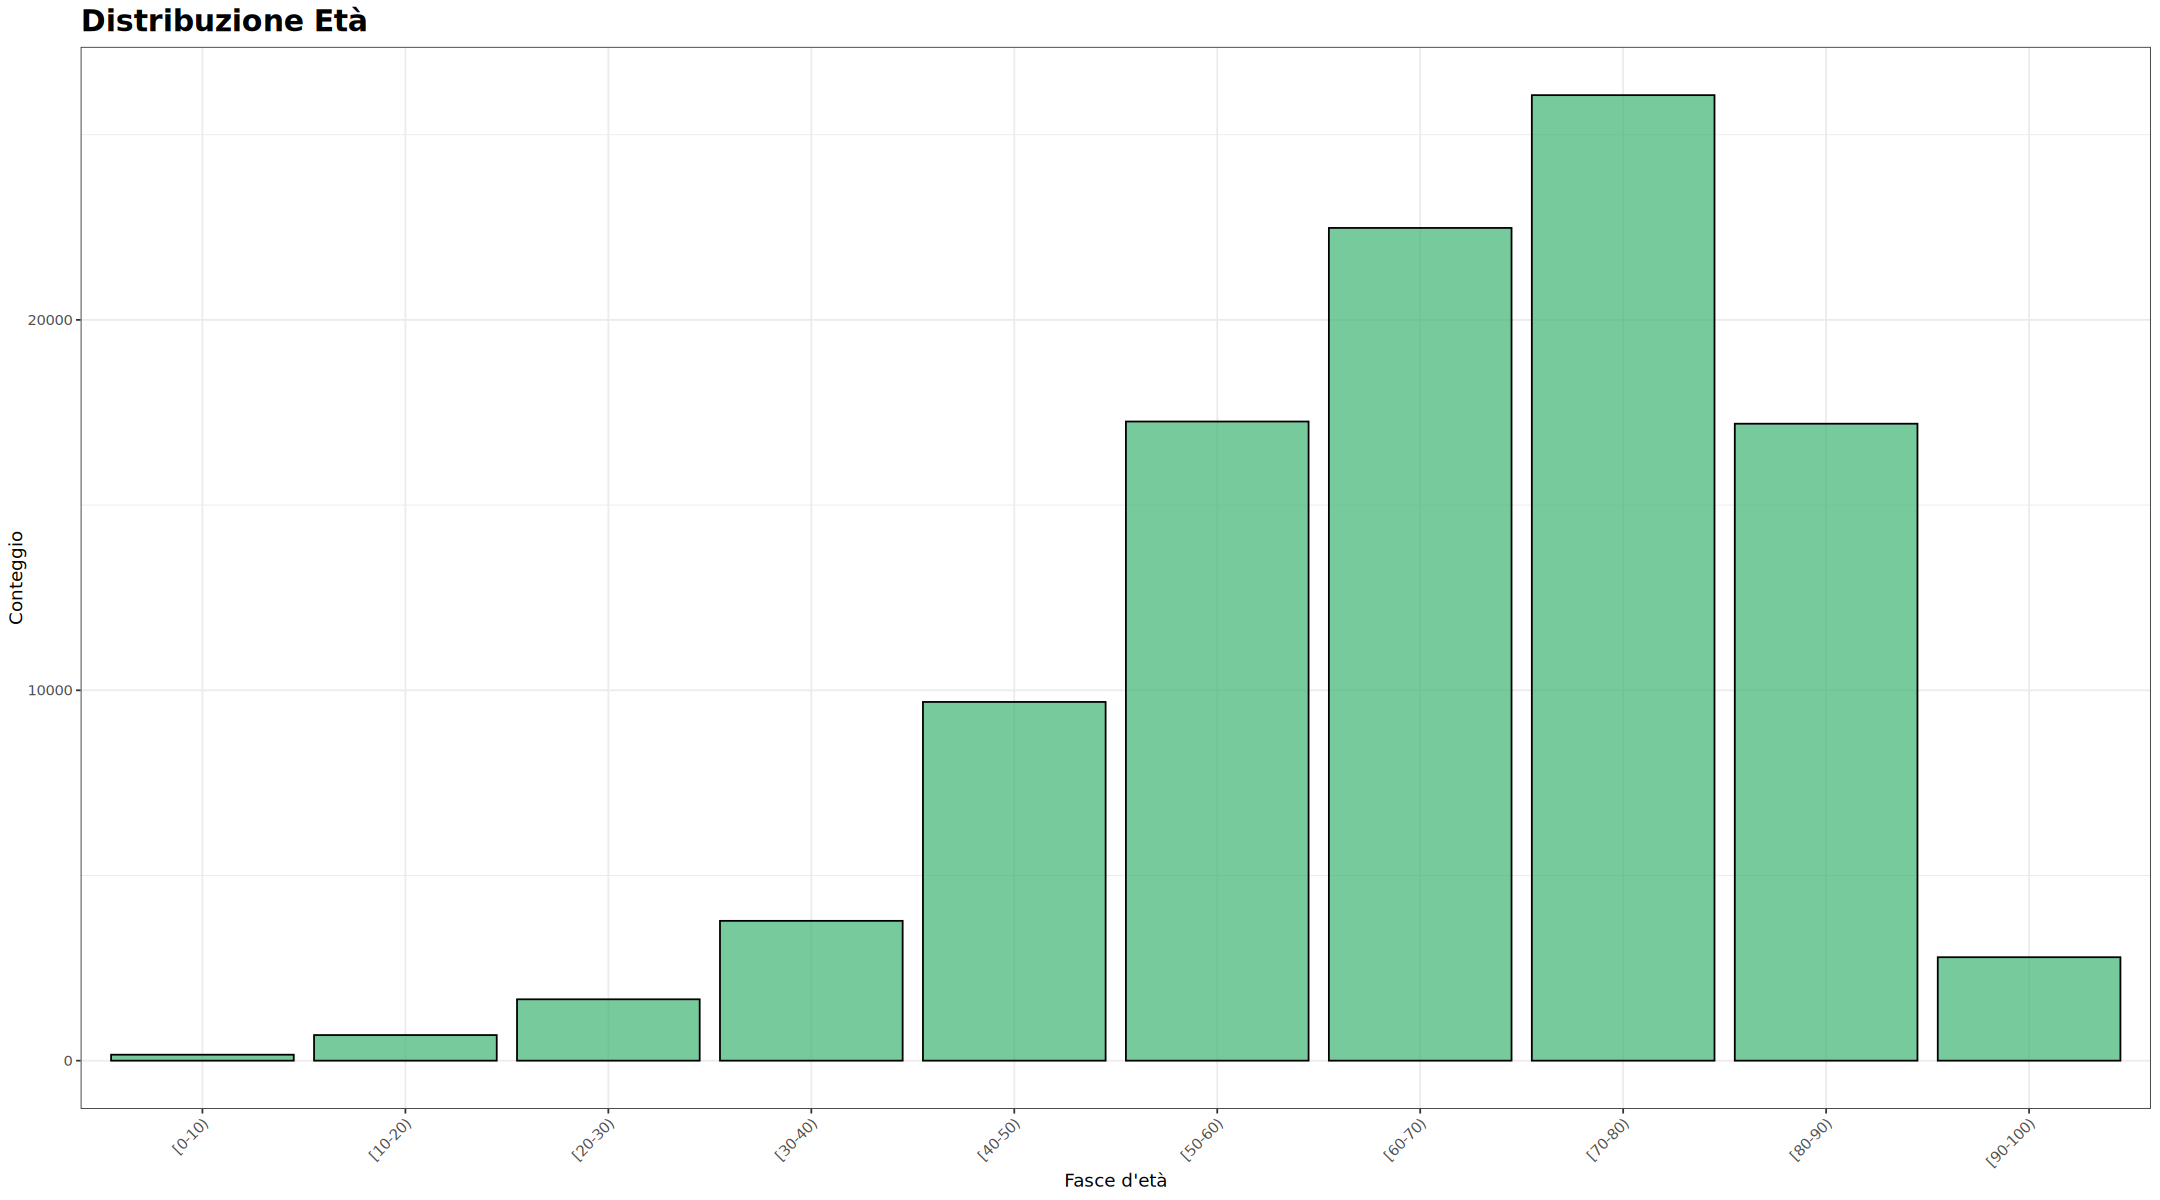

In [32]:
p_age <- ggplot(df, aes(x = age)) +
  geom_bar(fill = "mediumseagreen", color = "black", alpha = 0.7) +
  labs(title = "Distribuzione Età", x = "Fasce d'età", y = "Conteggio") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

p_age

race,n,percentuale
<chr>,<int>,<dbl>
Caucasian,76099,74.78
AfricanAmerican,19210,18.88
NA,2273,2.23
Hispanic,2037,2.00
Other,1506,1.48
Asian,641,0.63


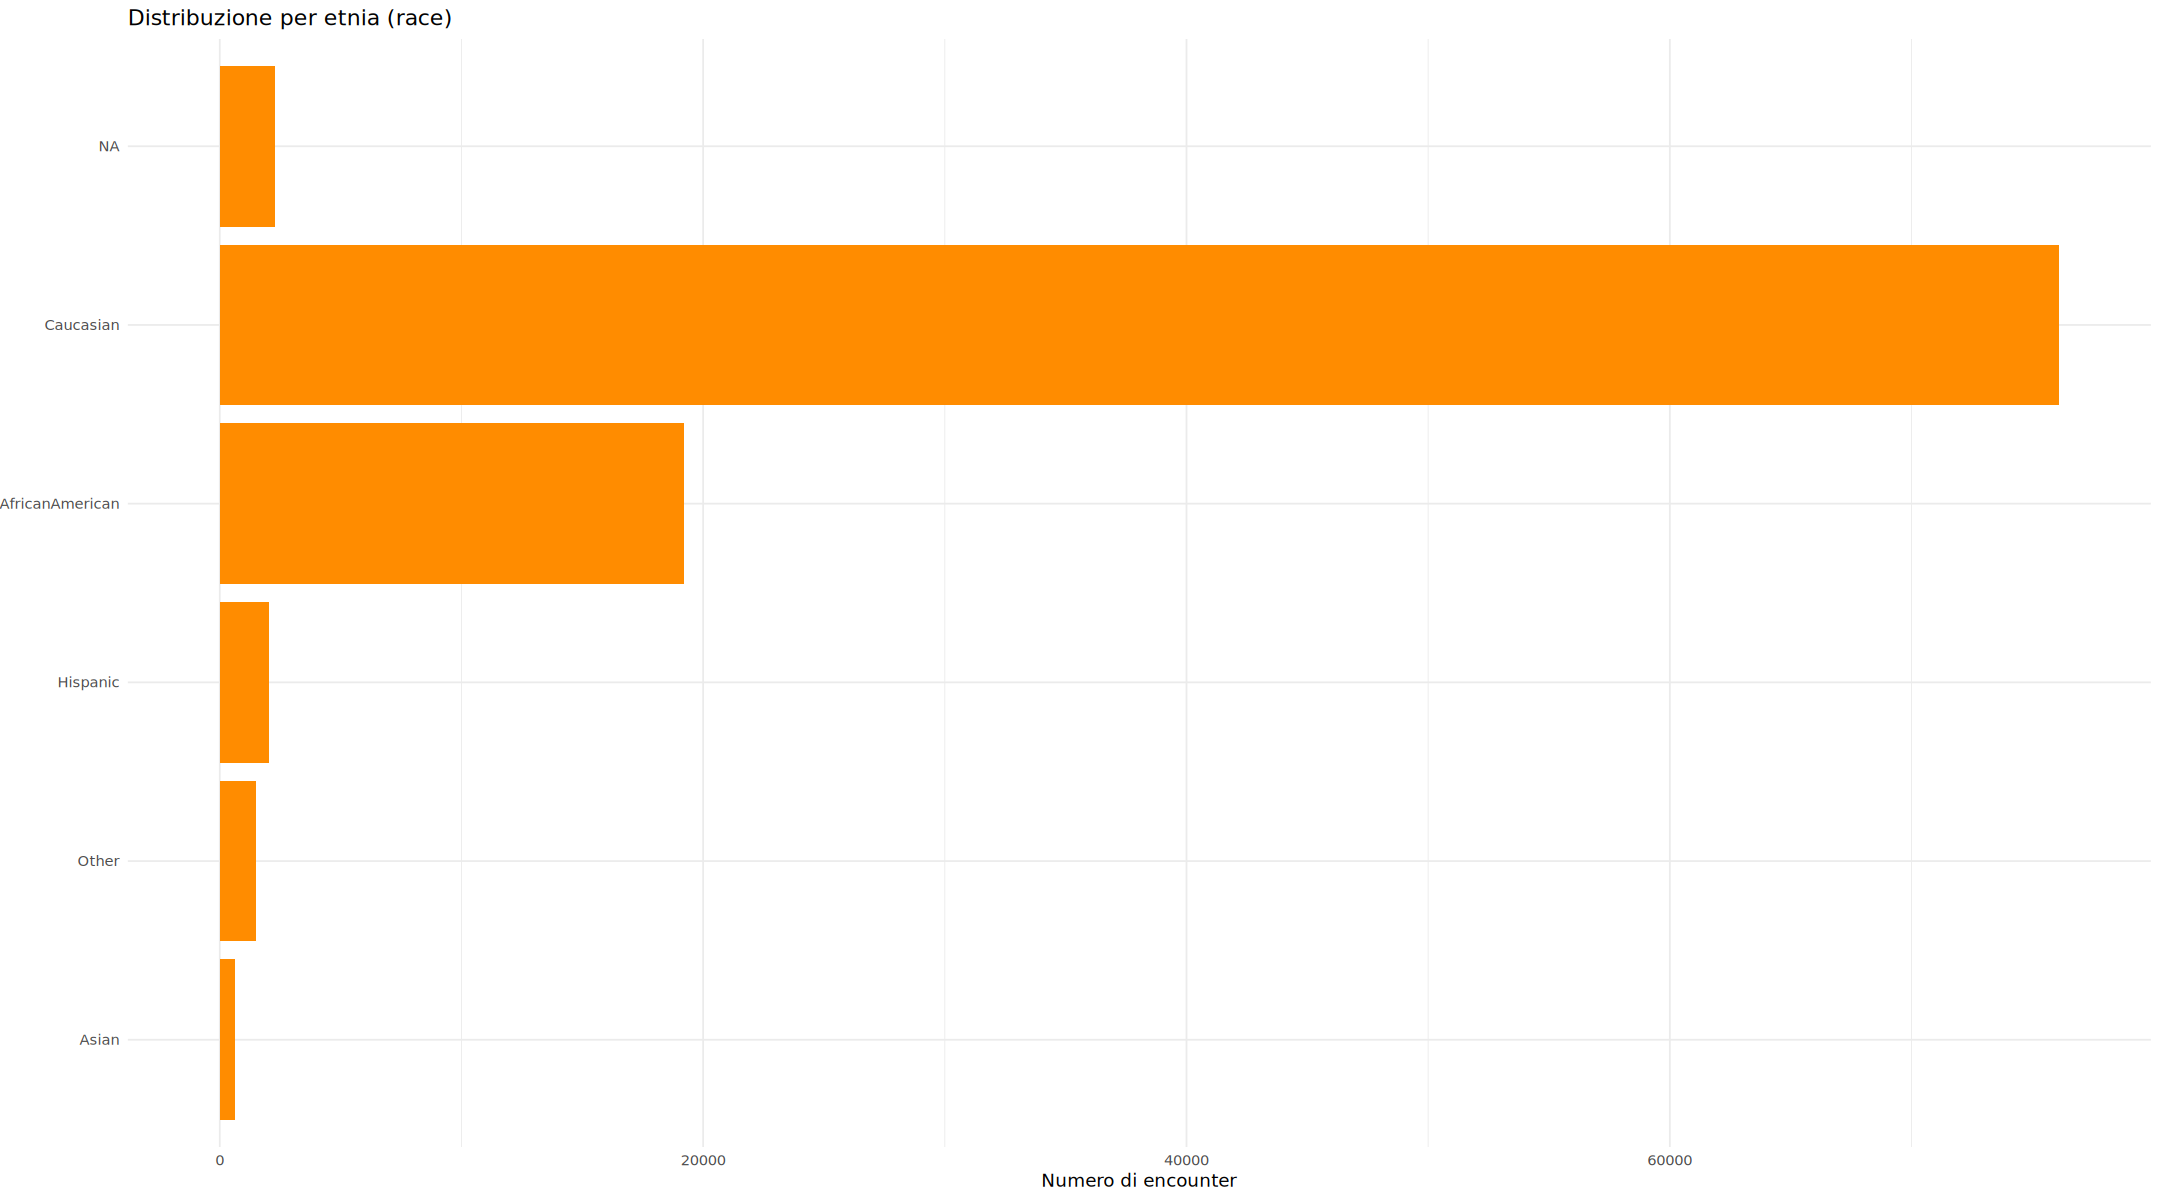

In [33]:
df %>%
  count(race, name = "count") %>%
  ggplot(aes(x = count, y = reorder(race, count))) + 
  geom_col(fill = "darkorange") +
  labs(title = "Distribuzione per etnia (race)",
       x = "Numero di encounter",
       y = NULL) + 
  theme_minimal() 


percentuali <- df %>%
  count(race) %>%
  mutate(percentuale = round((n / sum(n)) * 100, 2)) %>%
  arrange(desc(percentuale))

percentuali

Osservazioni con peso disponibile: 3197 (3.14%)


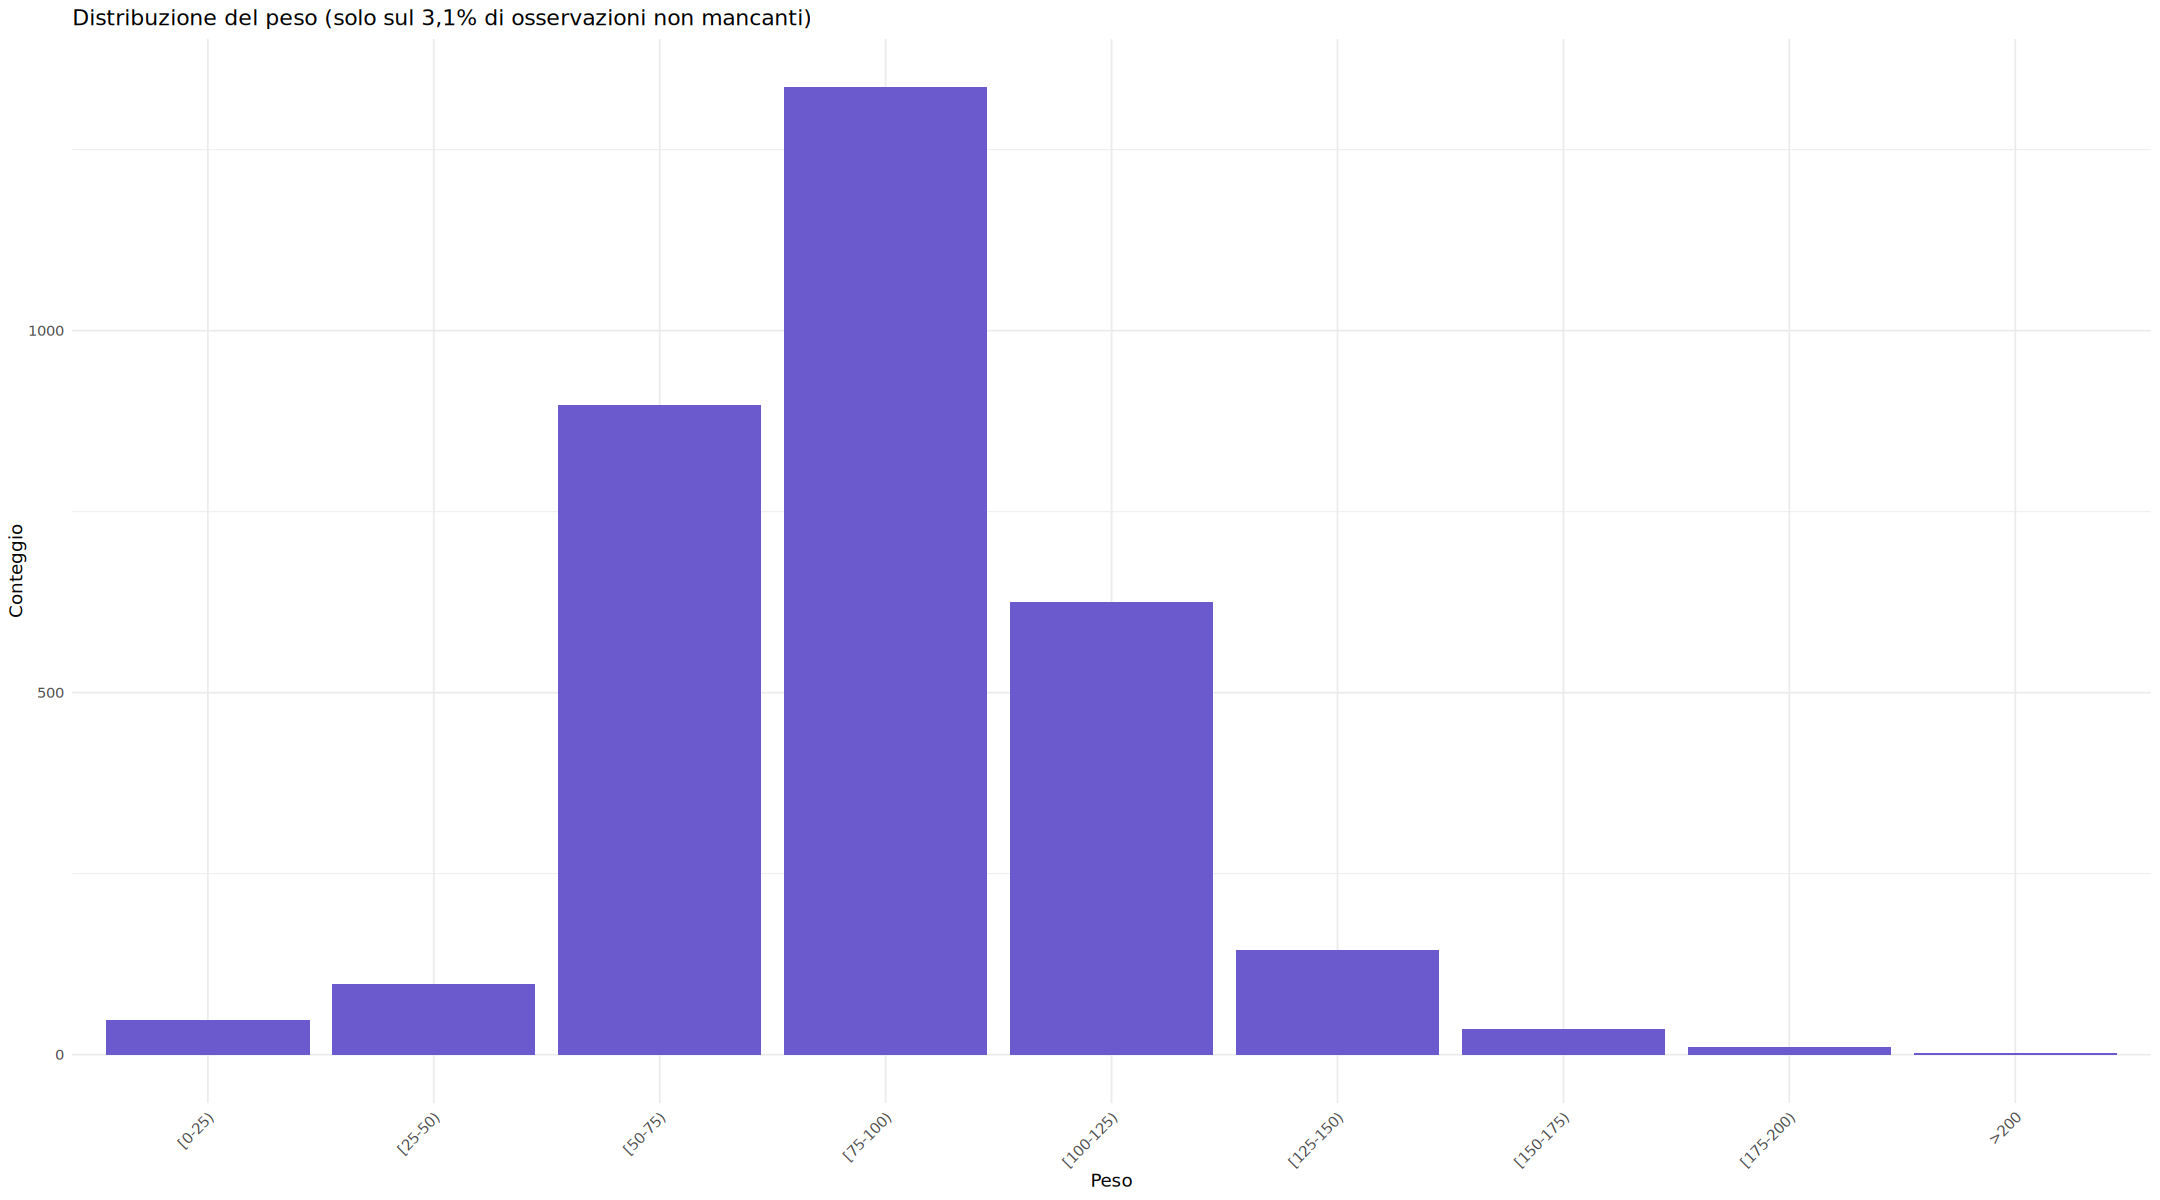

In [34]:
df_weight <- df %>% filter(!is.na(weight))

n_avail <- nrow(df_weight)
n_total <- nrow(df)
perc_avail <- (n_avail / n_total) * 100

cat(sprintf("Osservazioni con peso disponibile: %d (%.2f%%)\n", n_avail, perc_avail))

df_weight %>%
  
  mutate(weight = reorder(weight, parse_number(weight))) %>% 
  ggplot(aes(x = weight)) +
  geom_bar(fill = "slateblue") + # sns.countplot
  labs(title = "Distribuzione del peso (solo sul 3,1% di osservazioni non mancanti)",
       x = "Peso", 
       y = "Conteggio") +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

- **Genere**: Lieve prevalenza femminile (53.8% contro 46.2% maschile).
- **Età**: L'età è raggruppata in intervalli di 10 anni (da `[0-10)` a `[90-100)`). La distribuzione è fortemente asimmetrica: la maggior parte dei pazienti ospedalizzati con diabete rientra nelle fasce `[50-60)`, `[60-70)`, `[70-80)` e `[80-90)`. Il picco assoluto è nella decade 70-80.
- **Etnie**: fortemente sbilanciato verso il gruppo `Caucasian` (~75%), seguito da `AfricanAmerican` (~19%); le altre etnie sono rappresentate marginalmente. E' un punto da considerare nel valutare la generalizzabilita' di eventuali modelli predittivi.
- **Peso**: come visto, è mancante nel 96,9% dei casi, quindi il suo contenuto informativo è molto limitato; comunque è stata inserita la distribuzione sul ridotto sottoinsieme di osservazioni disponibili, solo a titolo descrittivo.

## Analisi delle variabili numeriche

In [35]:
numeric_cols <- c("time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
                  "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses")

statistiche <- df %>% 
  select(all_of(numeric_cols)) %>% 
  describe()

statistiche

,vars,n,mean,sd,median,trimmed,mad,min,max,range,skew,kurtosis,se
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
time_in_hospital,1,101766,4.3959869,2.9851078,4,3.99385855,2.9652,1,14,13,1.1339653,0.8500744,0.009357475
num_lab_procedures,2,101766,43.0956410,19.6743622,44,43.78520893,19.2738,1,132,131,-0.2365369,-0.2451746,0.061673602
num_procedures,3,101766,1.3397304,1.7058070,1,1.01516938,1.4826,0,6,6,1.3163760,0.8569334,0.005347226
num_medications,4,101766,16.0218442,8.1275662,15,15.23347336,7.4130,1,81,80,1.3266330,3.4677984,0.025477638
number_outpatient,5,101766,0.3693572,1.2672651,0,0.08061267,0.0000,0,42,42,8.8326985,147.8974448,0.003972520
number_emergency,6,101766,0.1978362,0.9304723,0,0.01482546,0.0000,0,76,76,22.8549084,1191.6046396,0.002916769
number_inpatient,7,101766,0.6355659,1.2628633,0,0.34882207,0.0000,0,21,21,3.6140325,20.7178539,0.003958722
number_diagnoses,8,101766,7.4226068,1.9336001,8,7.70772840,1.4826,1,16,15,-0.8767204,-0.0791685,0.006061294


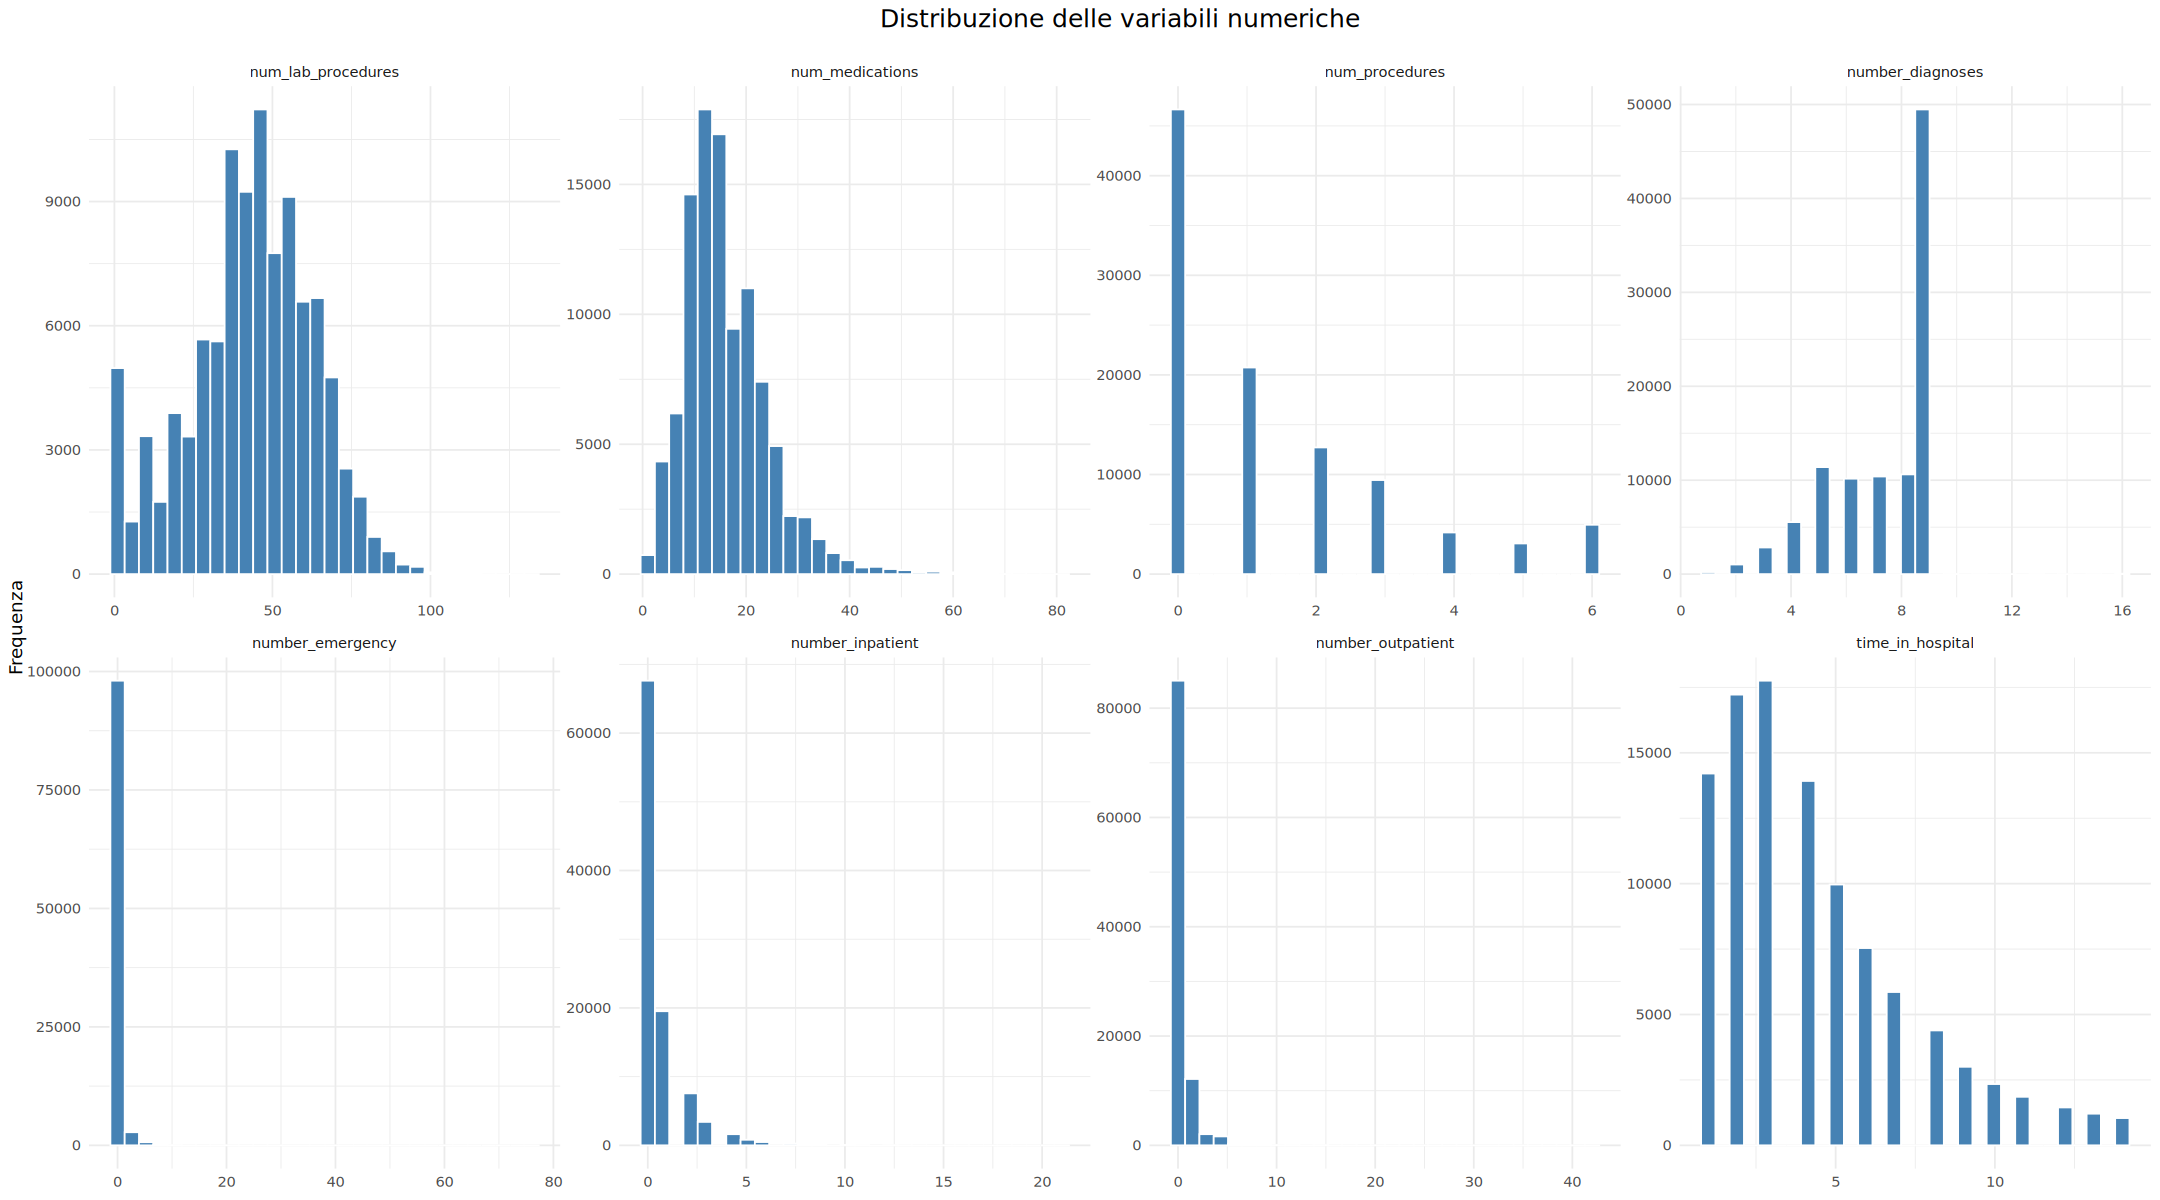

In [36]:
p_histograms <- df %>%
  select(all_of(numeric_cols)) %>%
  pivot_longer(cols = everything(), names_to = "variabile", values_to = "valore") %>%
  ggplot(aes(x = valore)) +
  geom_histogram(bins = 30, fill = "steelblue", color = "white") +
  facet_wrap(~ variabile, scales = "free", ncol = 4) +
  labs(title = "Distribuzione delle variabili numeriche",
       x = NULL,
       y = "Frequenza") +
  theme_minimal() +
  theme(plot.title = element_text(size = 15, hjust = 0.5, margin = margin(b = 15)))

p_histograms

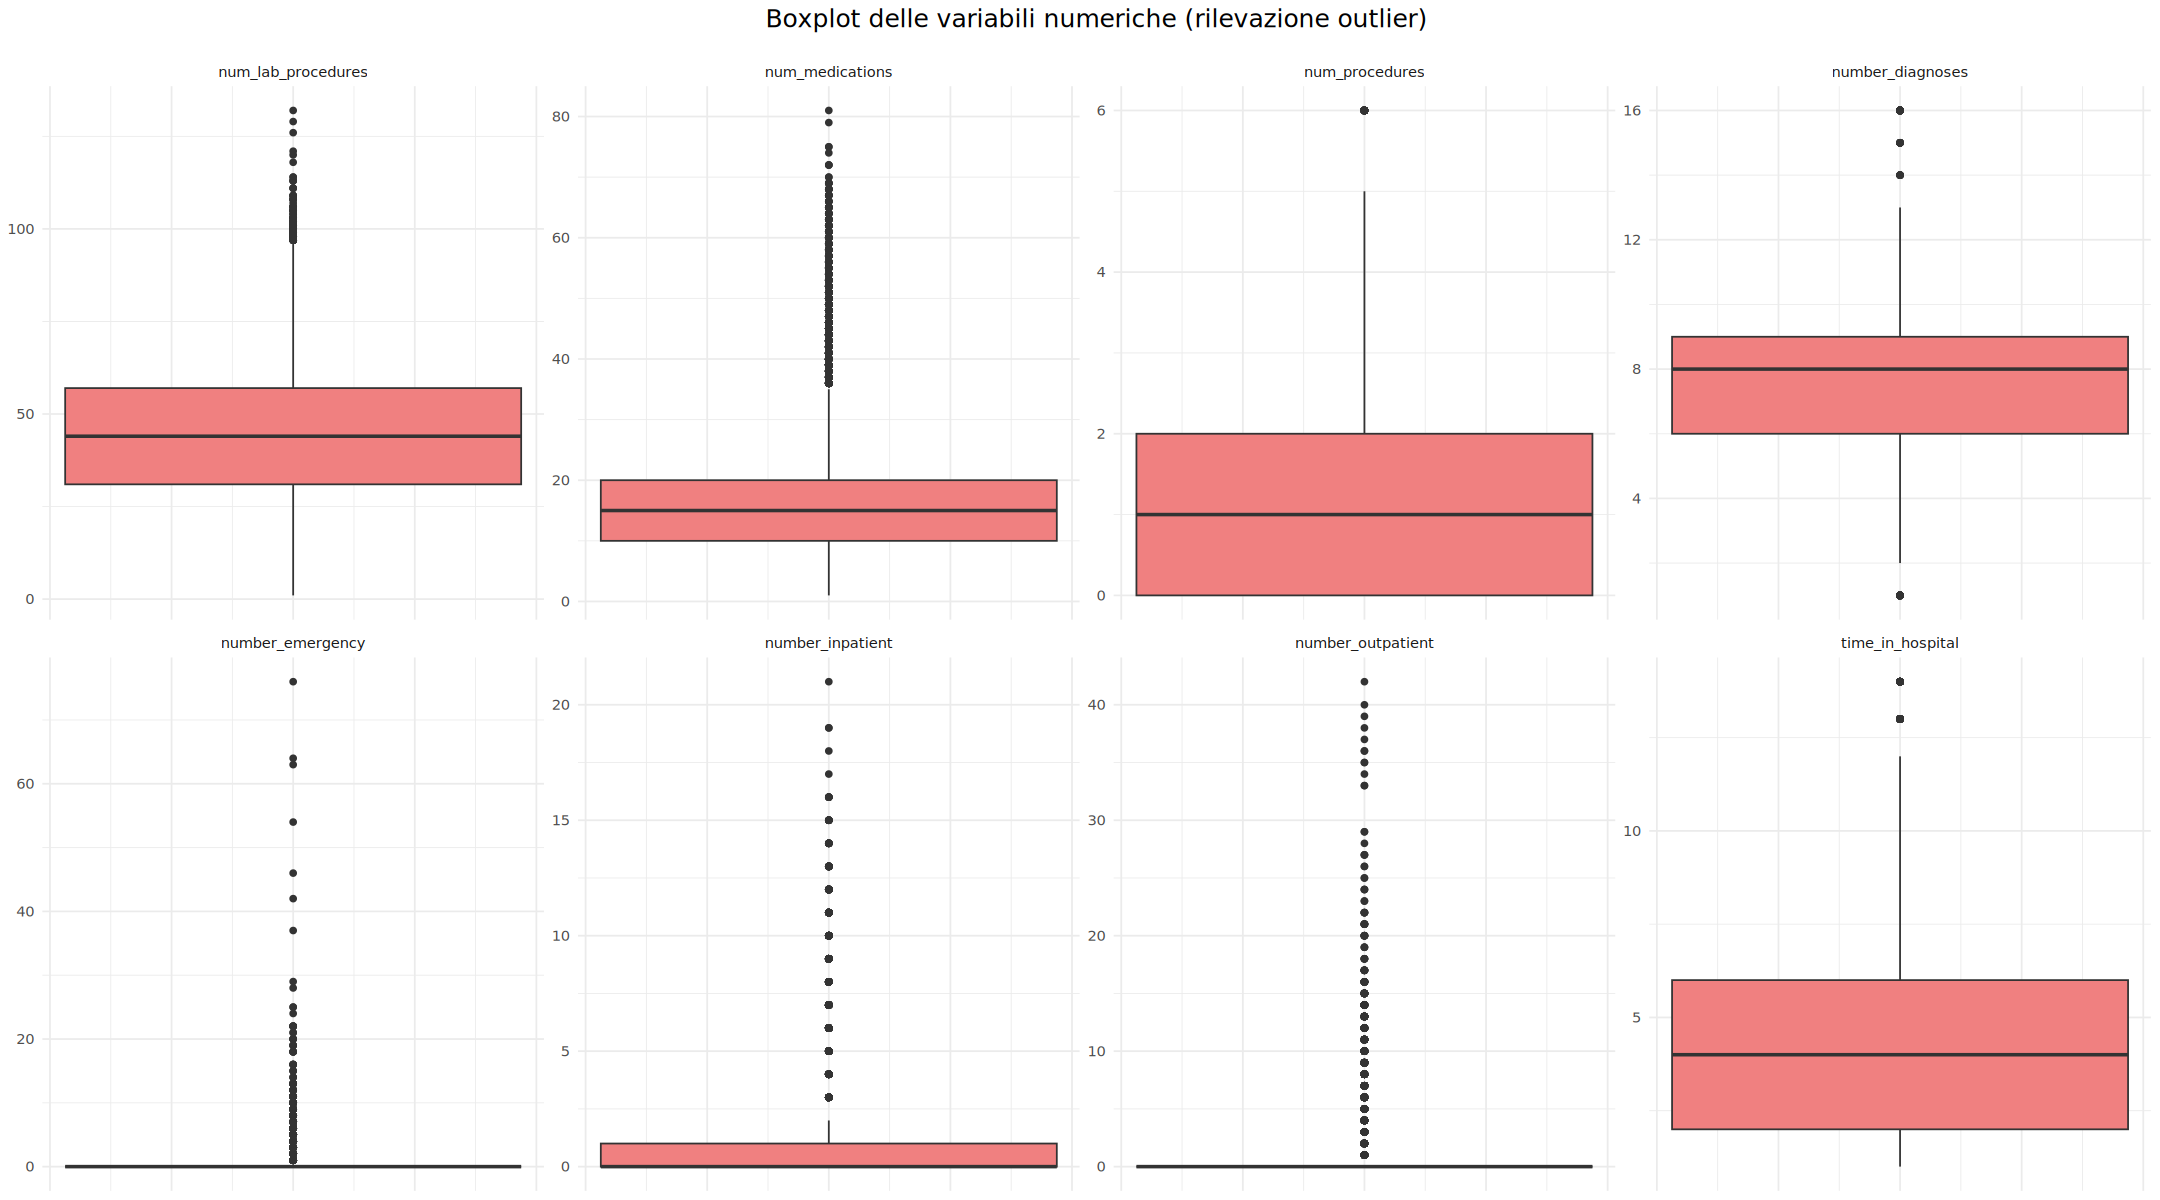

In [37]:
p_boxplots <- df %>%
  select(all_of(numeric_cols)) %>%
  pivot_longer(cols = everything(), names_to = "variabile", values_to = "valore") %>%
  ggplot(aes(y = valore)) +
  geom_boxplot(fill = "lightcoral") +
  facet_wrap(~ variabile, scales = "free", ncol = 4) +
  labs(title = "Boxplot delle variabili numeriche (rilevazione outlier)",
       x = NULL,
       y = NULL) +
  theme_minimal() +
  theme(plot.title = element_text(size = 15, hjust = 0.5, margin = margin(b = 15)),
        axis.text.x = element_blank(),
        axis.ticks.x = element_blank())

p_boxplots

In [38]:
library(e1071)

df_stats <- df %>%
  select(all_of(numeric_cols)) %>%
  pivot_longer(cols = everything(), names_to = "variabile", values_to = "valore", values_drop_na = TRUE) %>%
  group_by(variabile) %>%
  summarise(
    skewness = round(skewness(valore), 2),
    kurtosis = round(kurtosis(valore), 2), 
    q1 = quantile(valore, 0.25),
    q3 = quantile(valore, 0.75),
    iqr = q3 - q1,
    lower = q1 - 1.5 * iqr,
    upper = q3 + 1.5 * iqr,
    n_outlier_IQR = sum(valore < lower | valore > upper),
    pct_outlier = round((n_outlier_IQR / n()) * 100, 2),
    .groups = "drop"
  ) %>%
  select(variabile, skewness, kurtosis, n_outlier_IQR, pct_outlier)

df_stats


Attaching package: ‘e1071’


The following object is masked from ‘package:ggplot2’:

    element




variabile,skewness,kurtosis,n_outlier_IQR,pct_outlier
<chr>,<dbl>,<dbl>,<int>,<dbl>
num_lab_procedures,-0.24,-0.25,143,0.14
num_medications,1.33,3.47,2557,2.51
num_procedures,1.32,0.86,4954,4.87
number_diagnoses,-0.88,-0.08,281,0.28
number_emergency,22.85,1191.60,11383,11.19
number_inpatient,3.61,20.72,7049,6.93
number_outpatient,8.83,147.90,16739,16.45
time_in_hospital,1.13,0.85,2252,2.21


Quasi tutte le variabili sono asimmetriche verso destra, come tipico per dati di utilizzo sanitario (la maggior parte dei pazienti ha pochi eventi, pochi pazienti ne hanno molti). `number_outpatient`, `number_emergency` e `number_inpatient` sono fortemente asimmetriche e con molti "outlier" secondo il criterio IQR: in questo contesto, però, non si tratta di errori di misurazione, ma di pazienti con un utilizzo del sistema sanitario realmente molto più intenso della media (es. pazienti cronici con frequenti ricoveri)

## Variabili Amministrative
`admission_type_id`, `discharge_disposition_id` e `admission_source_id` sono codici numerici che fanno riferimento a una tabella di mappatura (`IDs_mapping.csv`, fornita separatamente nel dataset originale UCI). Per rendere l'analisi interpretabile, ricostruiamo qui le mappature ufficiali.

In [39]:

admission_type_map <- c(
  "1" = "Emergency", "2" = "Urgent", "3" = "Elective", "4" = "Newborn",
  "5" = "Not Available", "6" = "NULL", "7" = "Trauma Center", "8" = "Not Mapped"
)

discharge_disposition_map <- c(
  "1" = "Discharged to home", "2" = "Transferred - short term hospital", "3" = "Transferred - SNF",
  "4" = "Transferred - ICF", "5" = "Transferred - other inpatient care institution",
  "6" = "Home health service", "7" = "Left AMA", "8" = "Home under care of Home IV provider",
  "9" = "Admitted as inpatient to this hospital", "10" = "Neonate to another hospital",
  "11" = "Expired", "12" = "Still patient / expected to return", "13" = "Hospice / home",
  "14" = "Hospice / medical facility", "15" = "Transferred - within institution to swing bed",
  "16" = "Transferred/referred to outpatient services (other inst.)",
  "17" = "Transferred/referred to outpatient services (this inst.)", "18" = "NULL",
  "19" = "Expired at home (Medicaid hospice)", "20" = "Expired in medical facility (Medicaid hospice)",
  "21" = "Expired, place unknown (Medicaid hospice)", "22" = "Transferred - rehab facility",
  "23" = "Transferred - long term care hospital", "24" = "Transferred - nursing facility (Medicaid only)",
  "25" = "Not Mapped", "26" = "Unknown/Invalid", "27" = "Transferred - federal health care facility",
  "28" = "Transferred - psychiatric hospital", "29" = "Transferred - Critical Access Hospital",
  "30" = "Transferred - other type of health care institution"
)

admission_source_map <- c(
  "1" = "Physician Referral", "2" = "Clinic Referral", "3" = "HMO Referral", "4" = "Transfer from a hospital",
  "5" = "Transfer from SNF", "6" = "Transfer from another health care facility", "7" = "Emergency Room",
  "8" = "Court/Law Enforcement", "9" = "Not Available", "10" = "Transfer from critical access hospital",
  "11" = "Normal Delivery", "12" = "Premature Delivery", "13" = "Sick Baby", "14" = "Extramural Birth",
  "15" = "Not Available", "17" = "NULL", "18" = "Transfer from another Home Health Agency",
  "19" = "Readmission to Same Home Health Agency", "20" = "Not Mapped", "21" = "Unknown/Invalid",
  "22" = "Transfer from hospital inpt (separate claim)", "23" = "Born inside this hospital",
  "24" = "Born outside this hospital", "25" = "Transfer from Ambulatory Surgery Center",
  "26" = "Transfer from Hospice"
)

df <- df %>%
  mutate(
    admission_type_desc = unname(admission_type_map[as.character(admission_type_id)]),
    discharge_disposition_desc = unname(discharge_disposition_map[as.character(discharge_disposition_id)]),
    admission_source_desc = unname(admission_source_map[as.character(admission_source_id)])
  )

df %>%
  select(admission_type_id, admission_type_desc, discharge_disposition_id, 
         discharge_disposition_desc, admission_source_id, admission_source_desc) %>%
  head()

admission_type_id,admission_type_desc,discharge_disposition_id,discharge_disposition_desc,admission_source_id,admission_source_desc
<dbl>,<chr>,<dbl>,<chr>,<dbl>,<chr>
6,NULL,25,Not Mapped,1,Physician Referral
1,Emergency,1,Discharged to home,7,Emergency Room
1,Emergency,1,Discharged to home,7,Emergency Room
1,Emergency,1,Discharged to home,7,Emergency Room
1,Emergency,1,Discharged to home,7,Emergency Room
2,Urgent,1,Discharged to home,2,Clinic Referral


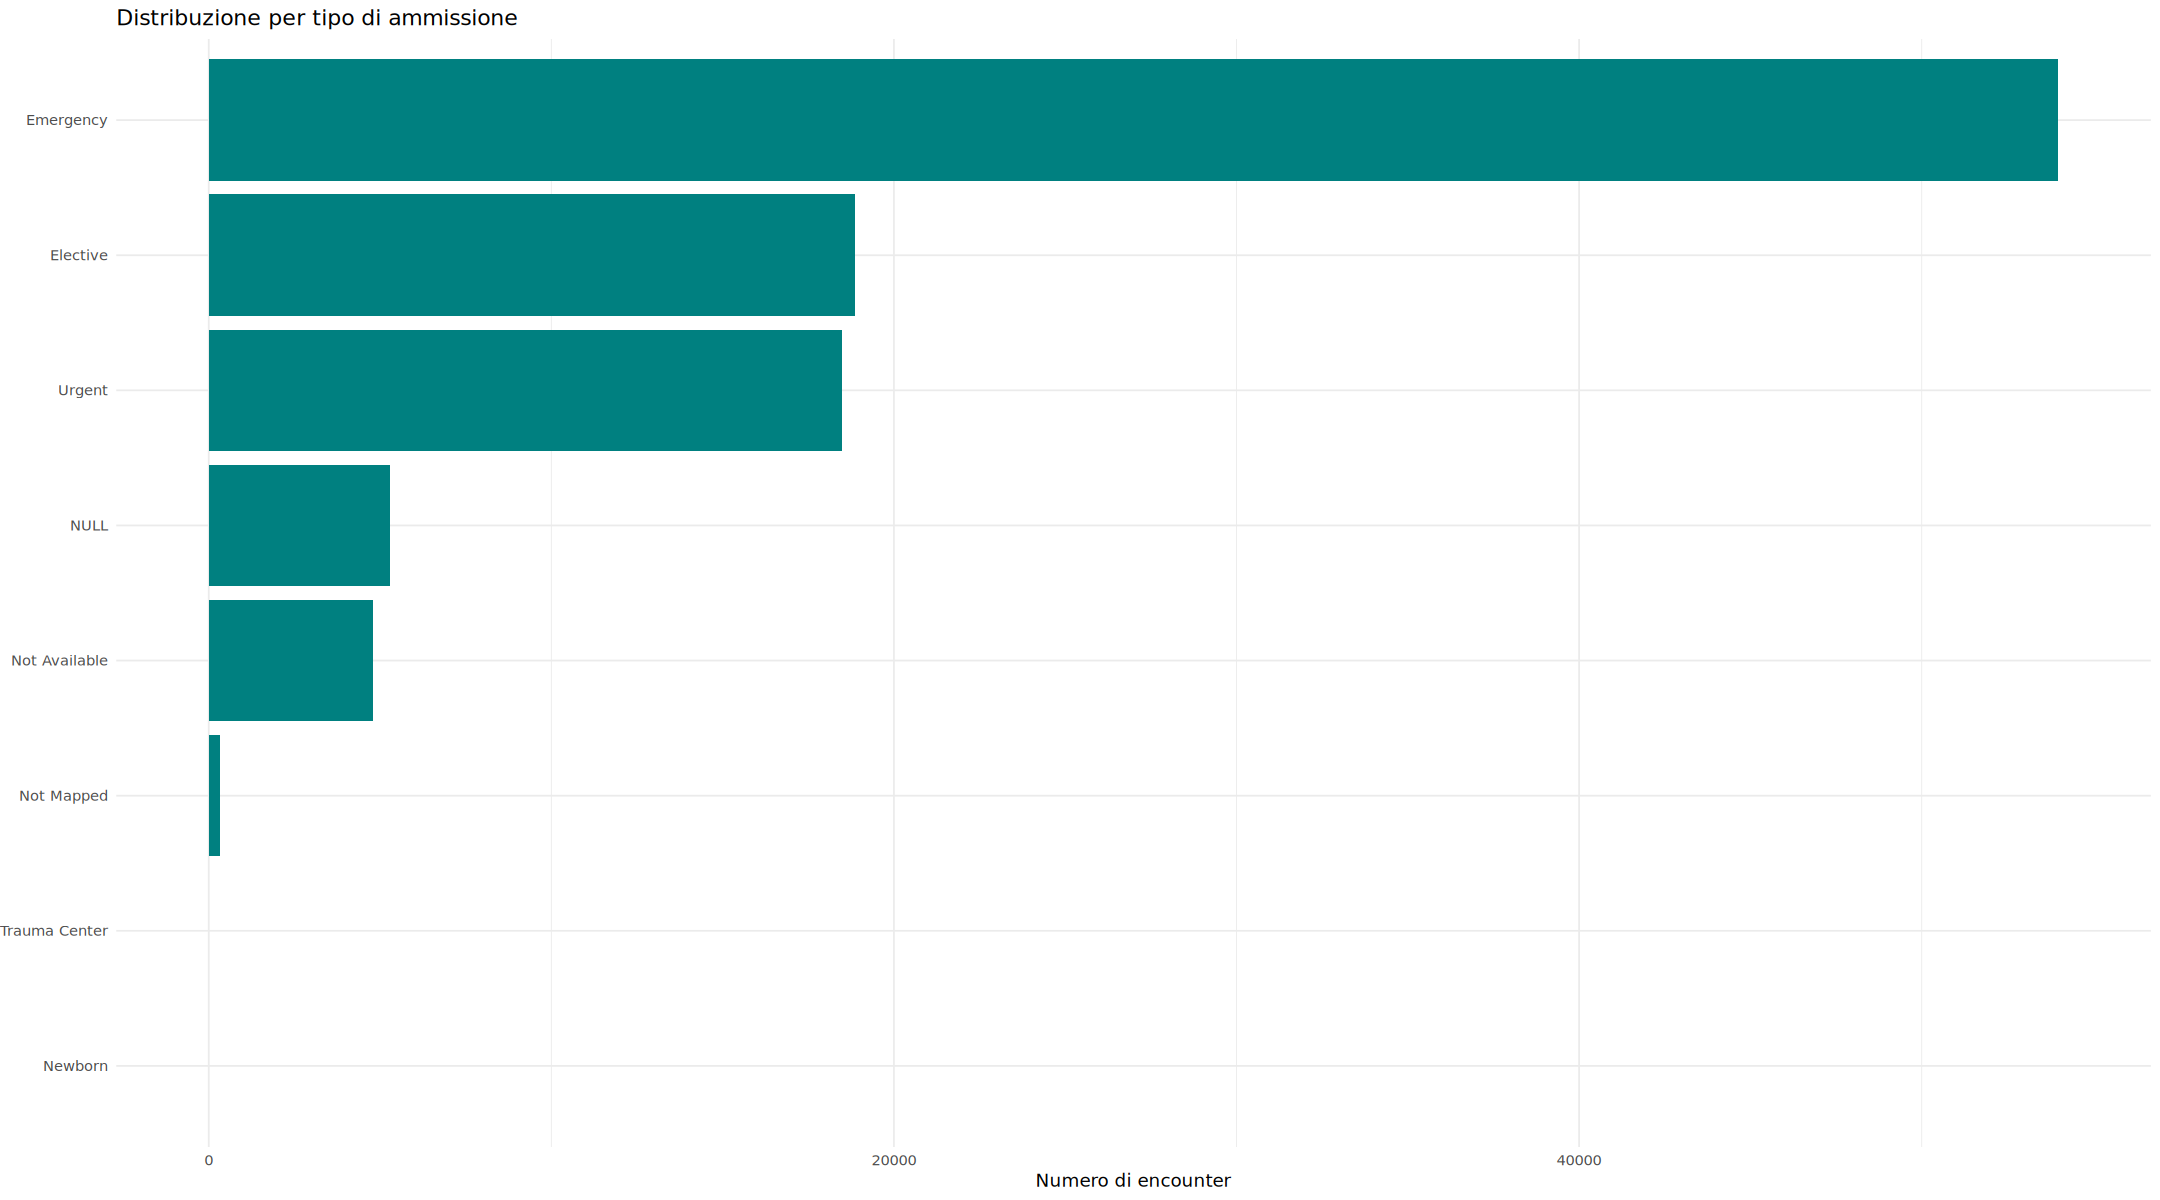

In [40]:
p_adm_type <- df %>%
  count(admission_type_desc) %>%
  ggplot(aes(x = n, y = reorder(admission_type_desc, n))) +
  geom_col(fill = "#008080") + 
  labs(title = "Distribuzione per tipo di ammissione",
       x = "Numero di encounter",
       y = NULL) +
  theme_minimal()

p_adm_type

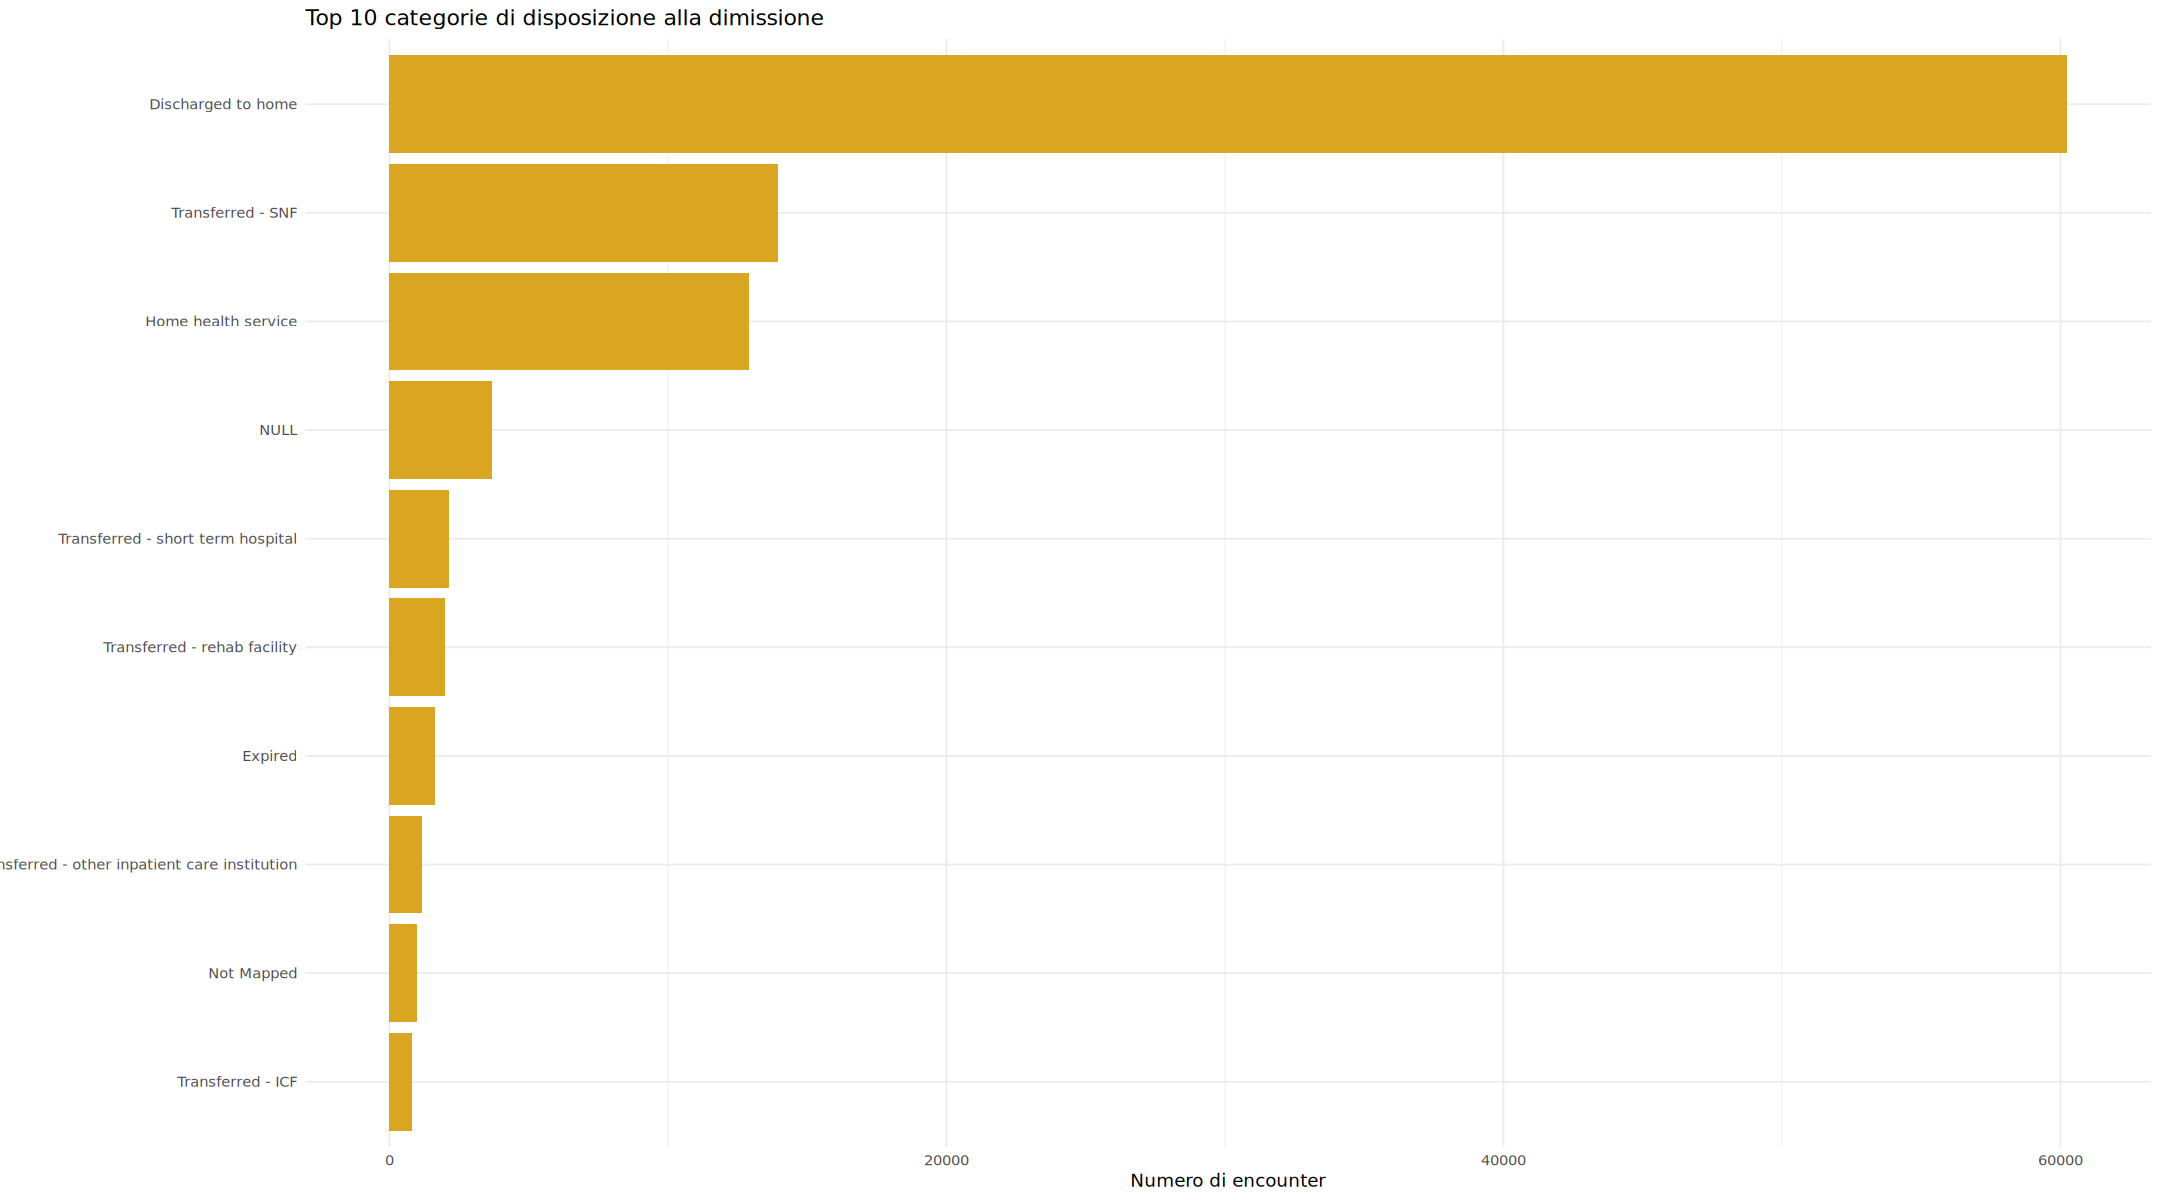

In [41]:
p_disch <- df %>%
  count(discharge_disposition_desc, sort = TRUE) %>%
  slice_head(n = 10) %>%
  ggplot(aes(x = n, y = reorder(discharge_disposition_desc, n))) +
  geom_col(fill = "goldenrod") +
  labs(title = "Top 10 categorie di disposizione alla dimissione",
       x = "Numero di encounter",
       y = NULL) +
  theme_minimal()

p_disch

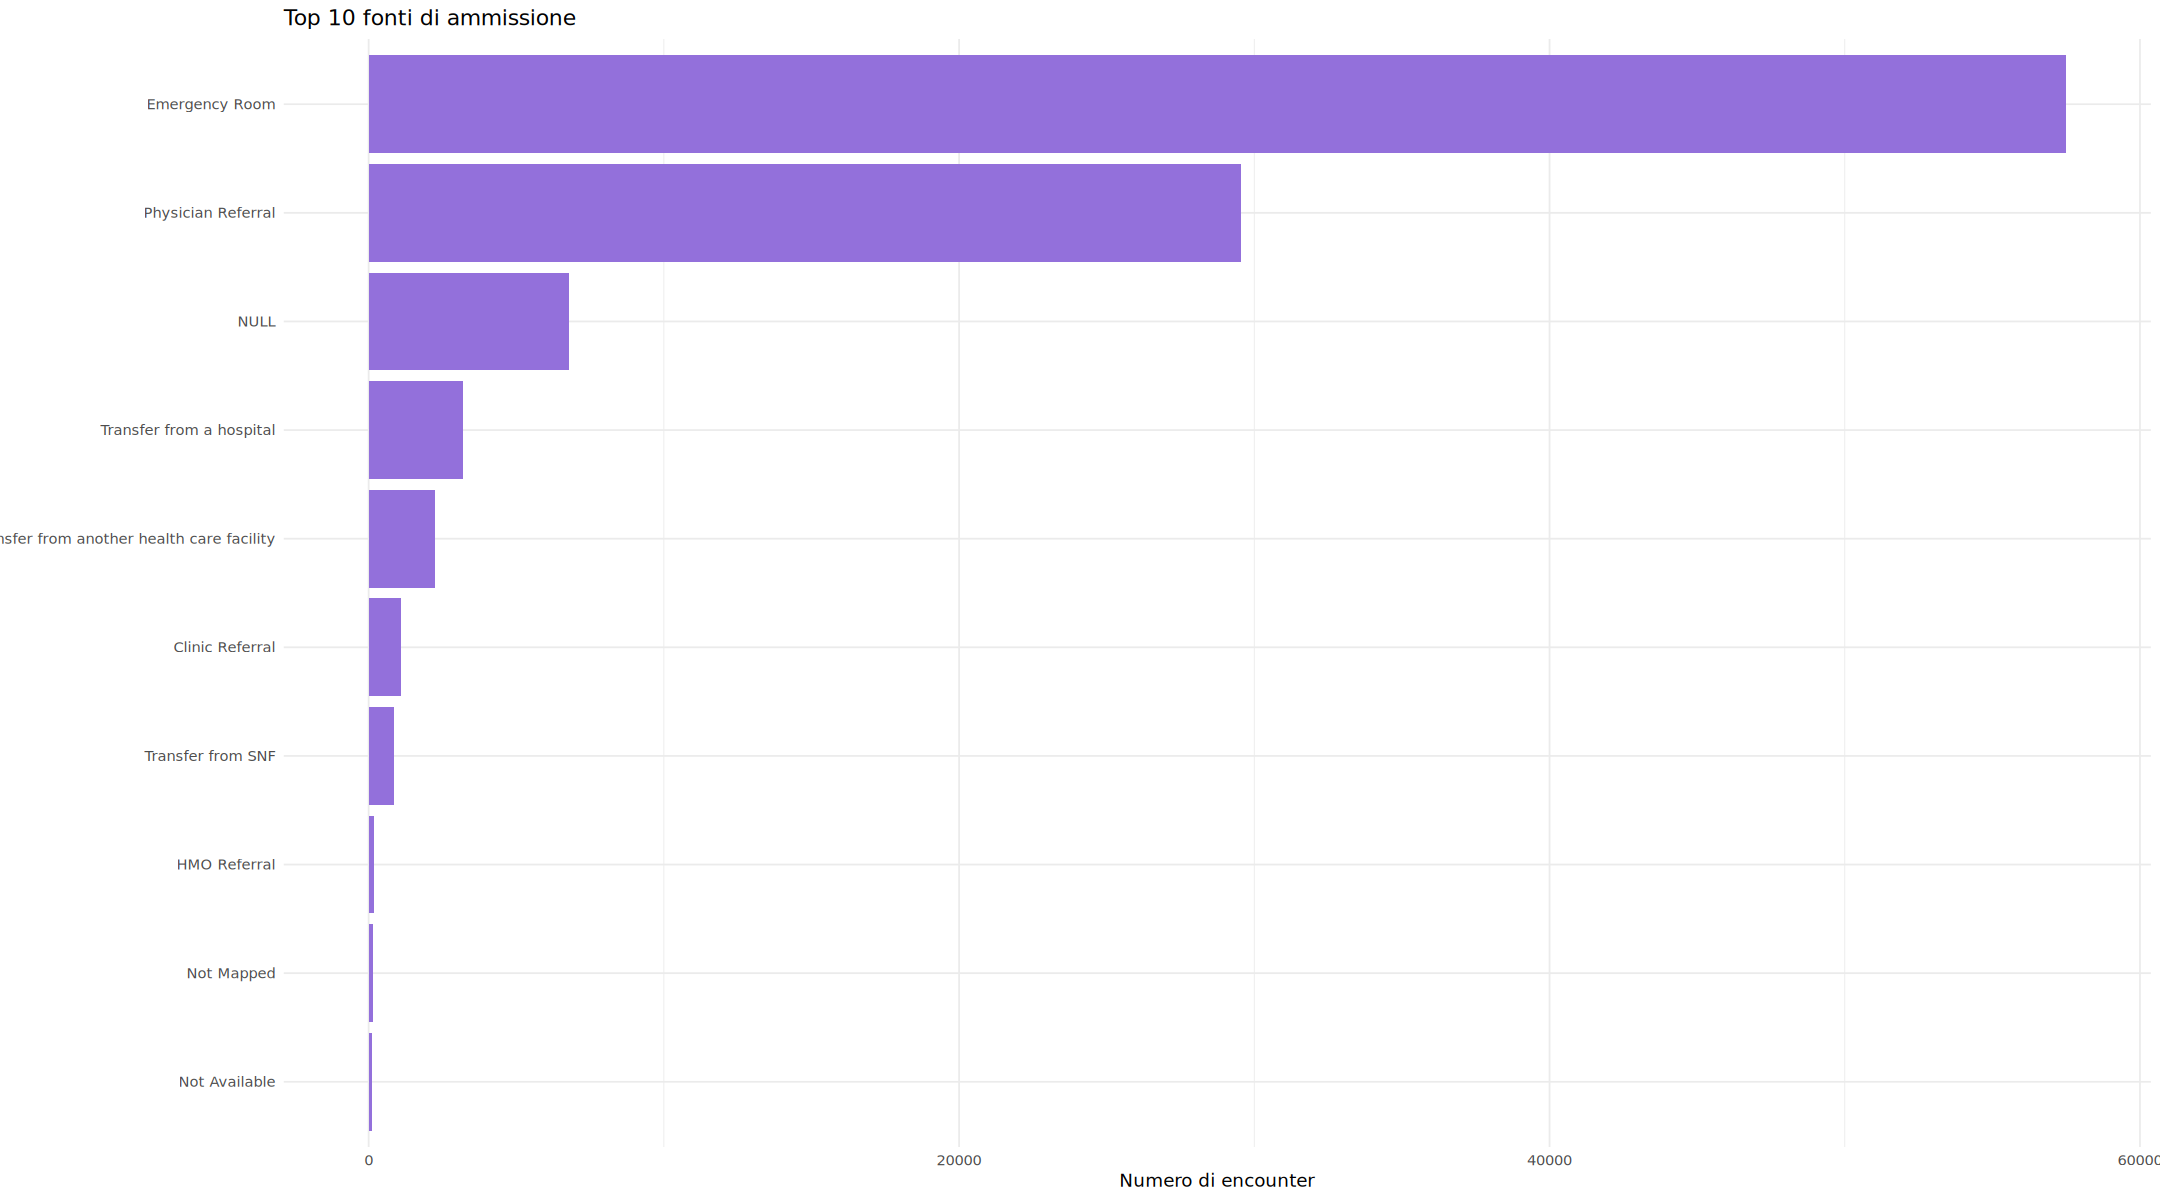

In [42]:
p_src <- df %>%
  count(admission_source_desc, sort = TRUE) %>%
  slice_head(n = 10) %>%
  ggplot(aes(x = n, y = reorder(admission_source_desc, n))) +
  geom_col(fill = "mediumpurple") +
  labs(title = "Top 10 fonti di ammissione",
       x = "Numero di encounter",
       y = NULL) +
  theme_minimal()

p_src

**Un punto di qualità dei dati molto rilevante.** Alcuni codici di `discharge_disposition_id` (11, 13, 14, 19, 20, 21) indicano che il paziente è **deceduto** o è stato trasferito in **hospice**. Per questi encounter, il concetto stesso di "riammissione" perde di significato clinico,. Verifichiamo empiricamente quanto siano frequenti questi casi e come si comporta la variabile target in questo sottogruppo.

Encounter con esito decesso/hospice: 2423 (2.38%)
# A tibble: 2 × 4
  expired_or_hospice    NO `>30` `<30`
  <lgl>              <dbl> <dbl> <dbl>
1 FALSE              0.529 0.357 0.114
2 TRUE               0.965 0.018 0.018


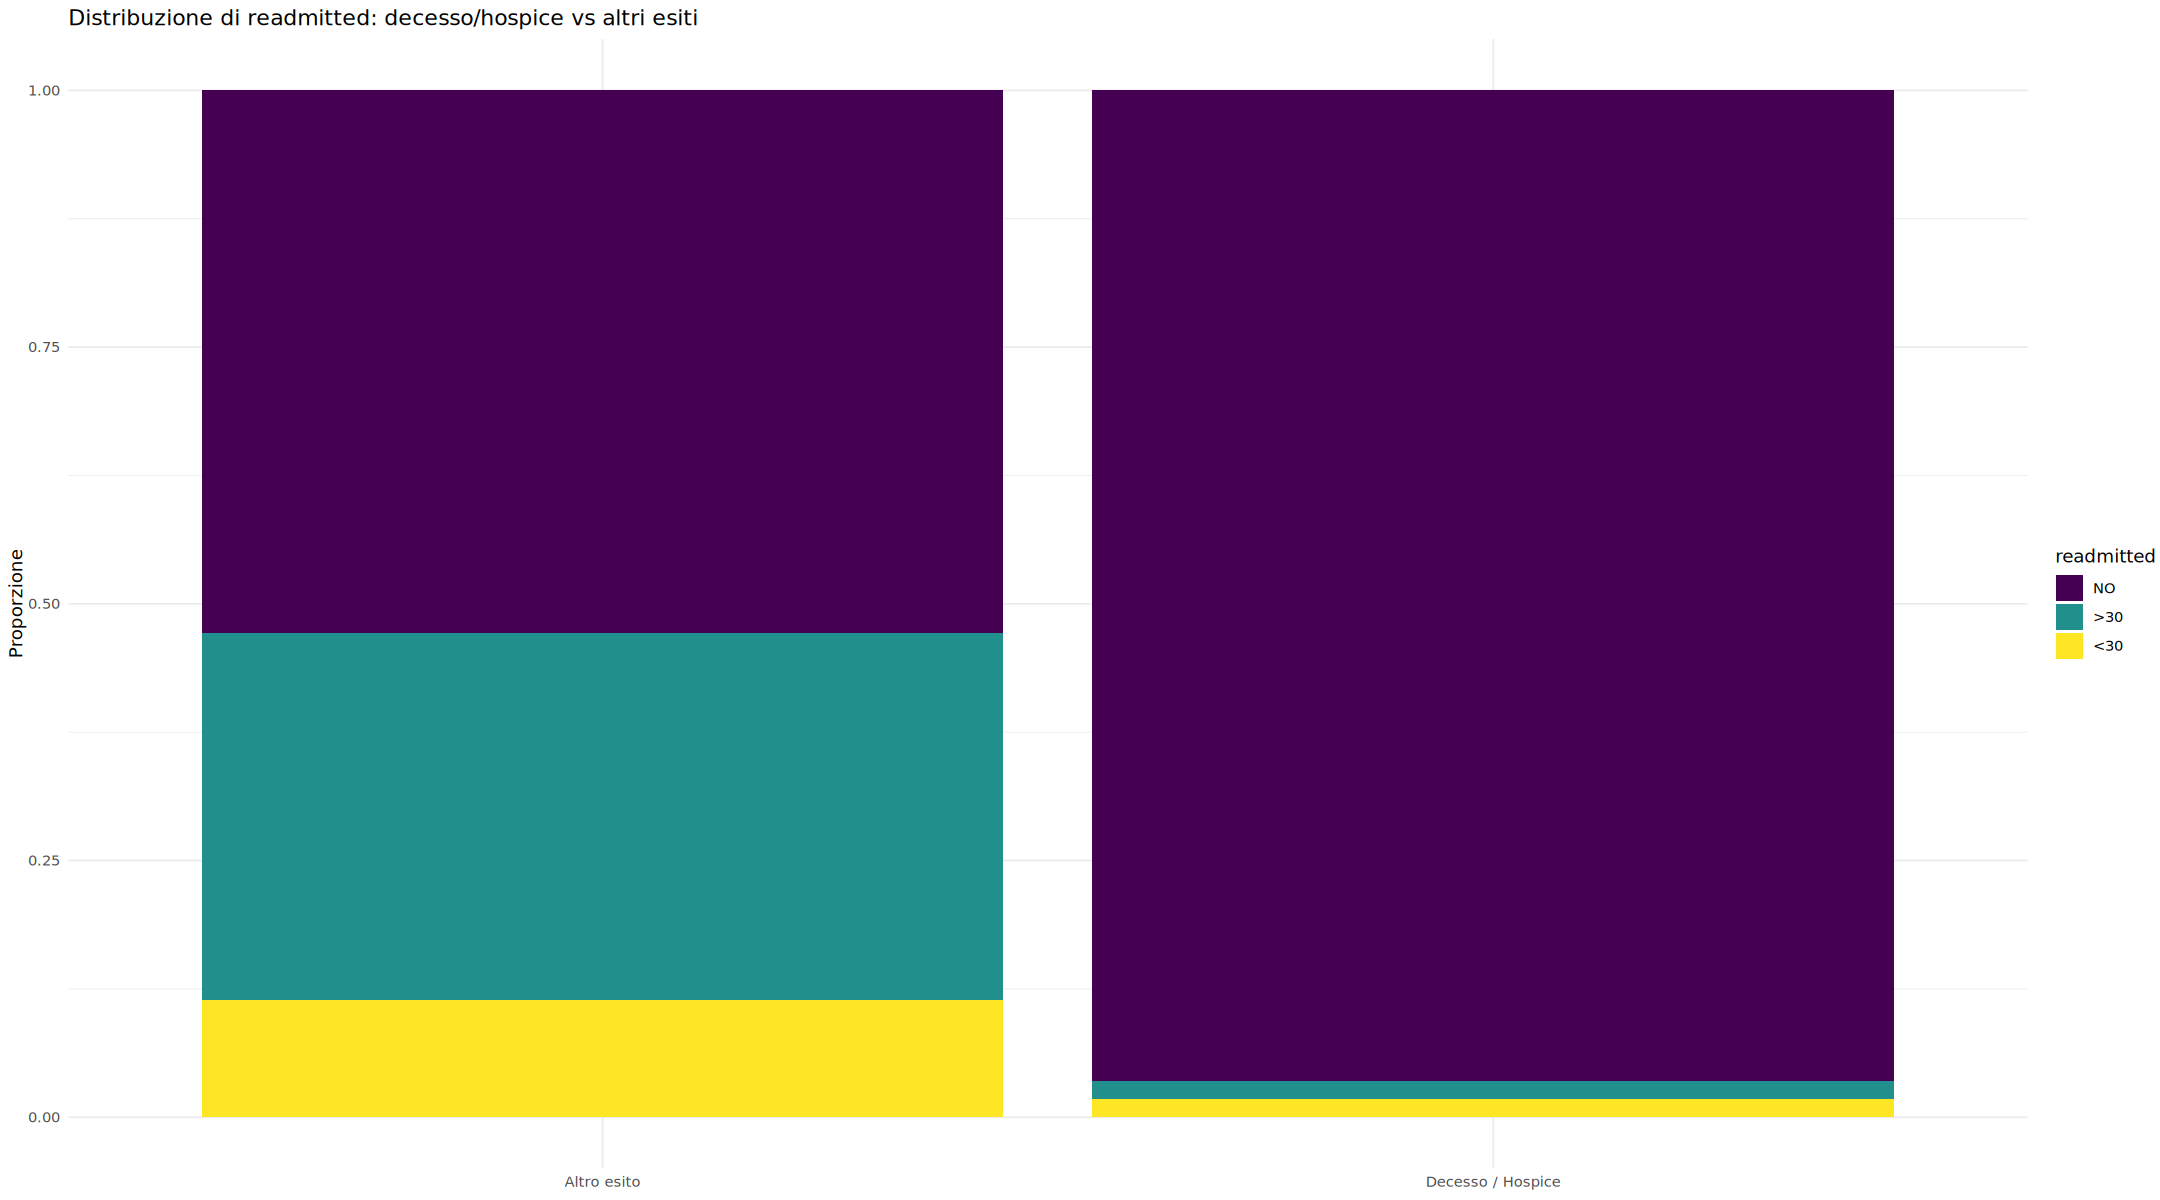

In [43]:
expired_hospice_ids <- c(11, 13, 14, 19, 20, 21)

df <- df %>% 
  mutate(expired_or_hospice = discharge_disposition_id %in% expired_hospice_ids)

n_exp <- sum(df$expired_or_hospice, na.rm = TRUE)
cat(sprintf("Encounter con esito decesso/hospice: %d (%.2f%%)\n", n_exp, (n_exp / nrow(df)) * 100))

ct <- df %>%
  count(expired_or_hospice, readmitted) %>%
  group_by(expired_or_hospice) %>%
  mutate(prop = n / sum(n)) %>%
  ungroup() %>%
  select(-n) %>%
  pivot_wider(names_from = readmitted, values_from = prop, values_fill = 0) %>%
  select(expired_or_hospice, any_of(c("NO", ">30", "<30")))

print(ct %>% mutate(across(where(is.numeric), ~ round(.x, 3))))

p_readm <- df %>%
  count(expired_or_hospice, readmitted) %>%
  group_by(expired_or_hospice) %>%
  mutate(prop = n / sum(n)) %>%
  ungroup() %>%
  mutate(readmitted = factor(readmitted, levels = c("NO", ">30", "<30"))) %>%
  ggplot(aes(x = factor(expired_or_hospice), y = prop, fill = readmitted)) +
  geom_col(position = "stack") +
  scale_x_discrete(labels = c("FALSE" = "Altro esito", "TRUE" = "Decesso / Hospice")) +
  scale_fill_viridis_d() +
  labs(title = "Distribuzione di readmitted: decesso/hospice vs altri esiti",
       x = NULL,
       y = "Proporzione",
       fill = "readmitted") +
  theme_minimal() +
  theme(legend.position = "right")

p_readm

Come atteso, gli encounter con esito decesso/hospice hanno una probabilità di riammissione entro 30 giorni quasi nulla. Questo conferma che, in un'eventuale fase di modellazione predittiva, sarebbe corretto **escludere queste circa 3.000 righe** (un paziente deceduto non può essere riammesso).

## Diagnosi (`diag_1`, `diag_2`, `diag_3`)
Le tre colonne di diagnosi contengono **codici ICD-9**, con centinaia di valori distinti ciascuna: una cardinalità troppo elevata per un'analisi diretta o per un eventuale one-hot encoding.

In [44]:
for (c in c("diag_1", "diag_2", "diag_3")) {
  cat(sprintf("%s: %d codici distinti\n", c, n_distinct(df[[c]])))
}

cat("\nTop 10 codici più frequenti per diag_1:\n")
df %>% count(diag_1, sort = TRUE) %>% slice_head(n = 10)

diag_1: 717 codici distinti
diag_2: 749 codici distinti
diag_3: 790 codici distinti

Top 10 codici più frequenti per diag_1:


diag_1,n
<chr>,<int>
428,6862
414,6581
786,4016
410,3614
486,3508
427,2766
491,2275
715,2151
682,2042


Per rendere l'informazione utilizzabile, i codici ICD-9 verranno raggruppati in **9 categorie cliniche**: Circulatory (390-459, 785), Respiratory (460-519, 786), Digestive (520-579, 787), Diabetes (250.xx), Injury (800-999), Musculoskeletal (710-739), Genitourinary (580-629, 788), Neoplasms (140-239), Other (tutto il resto, inclusi i codici che iniziano con V o E).

Le malattie **circolatorie** sono la causa di ricovero più frequente (30% circa dei casi), seguite da una categoria eterogenea "Other" e da quelle **respiratorie**. Sorprendentemente, il diabete come diagnosi *principale* riguarda solo l'8,6% circa degli encounter: nella maggior parte dei casi il diabete è una diagnosi secondaria/concomitante rispetto al motivo primario del ricovero.

## Esami `A1Cresult` e `max_glu_serum`

A1Cresult:


A1Cresult,n,percentuale
<chr>,<int>,<dbl>
>7,3812,3.75
>8,8216,8.07
None,84748,83.28
Norm,4990,4.90



max_glu_serum:


max_glu_serum,n,percentuale
<chr>,<int>,<dbl>
>200,1485,1.46
>300,1264,1.24
None,96420,94.75
Norm,2597,2.55


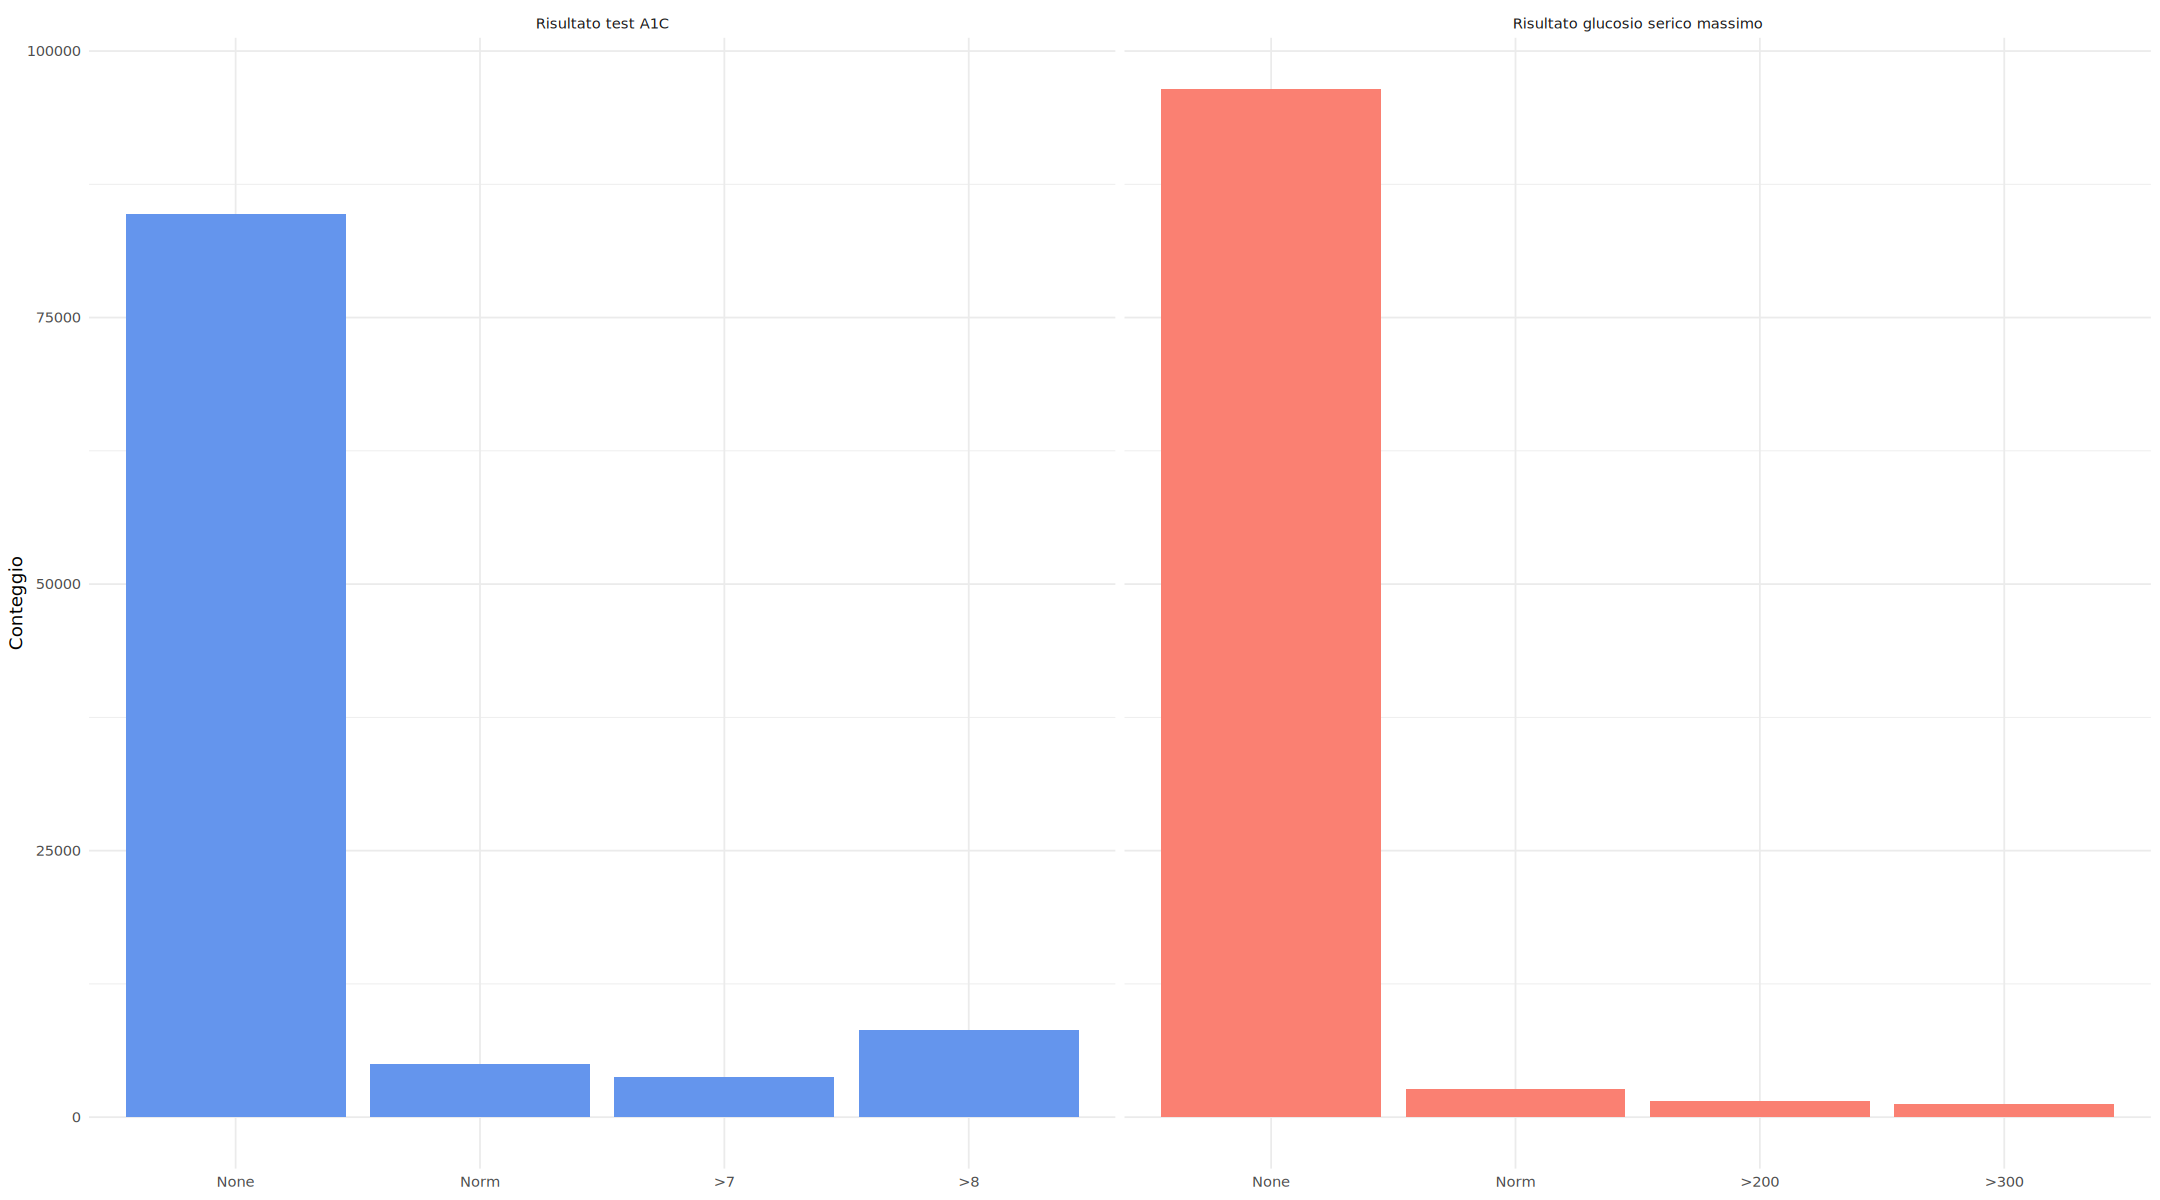

In [46]:
df_long <- df %>%
  select(A1Cresult, max_glu_serum) %>%
  pivot_longer(cols = everything(), names_to = "test", values_to = "risultato") %>%
  mutate(
    risultato = factor(risultato, levels = c("None", "Norm", ">7", ">8", ">200", ">300")),
    test = factor(test, 
                  levels = c("A1Cresult", "max_glu_serum"),
                  labels = c("Risultato test A1C", "Risultato glucosio serico massimo"))
  )

p_combined <- ggplot(df_long, aes(x = risultato, fill = test)) +
  geom_bar() +
  facet_wrap(~ test, scales = "free_x") +
  scale_fill_manual(values = c("Risultato test A1C" = "cornflowerblue", 
                               "Risultato glucosio serico massimo" = "salmon")) +
  labs(x = NULL, y = "Conteggio") +
  theme_minimal() +
  theme(legend.position = "none")

p_combined

cat("A1Cresult:\n")
df %>% count(A1Cresult) %>% mutate(percentuale = round((n / sum(n)) * 100, 2))

cat("\nmax_glu_serum:\n")
df %>% count(max_glu_serum) %>% mutate(percentuale = round((n / sum(n)) * 100, 2))

La grande maggioranza degli encounter non riporta una misurazione di questi due esami (`None`: 83% per A1C, 95% per il glucosio sierico): si tratta quindi di esami **non sistematicamente eseguiti** durante il ricovero

## Farmaci

Il dataset include 23 colonne relative a farmaci antidiabetici, ciascuna con valori `No` (non prescritto), `Steady` (dose stabile), `Up` (dose aumentata) o `Down` (dose diminuita), più le colonne `change` (variazione complessiva della terapia) e `diabetesMed` (presenza di farmaci per il diabete).

farmaco,pct_non_prescritto,pct_prescritto_o_modificato
<chr>,<dbl>,<dbl>
insulin,46.56,53.44
metformin,80.36,19.64
glipizide,87.53,12.47
glyburide,89.53,10.47
pioglitazone,92.80,7.20
rosiglitazone,93.75,6.25
glimepiride,94.90,5.10
repaglinide,98.49,1.51
glyburide-metformin,99.31,0.69


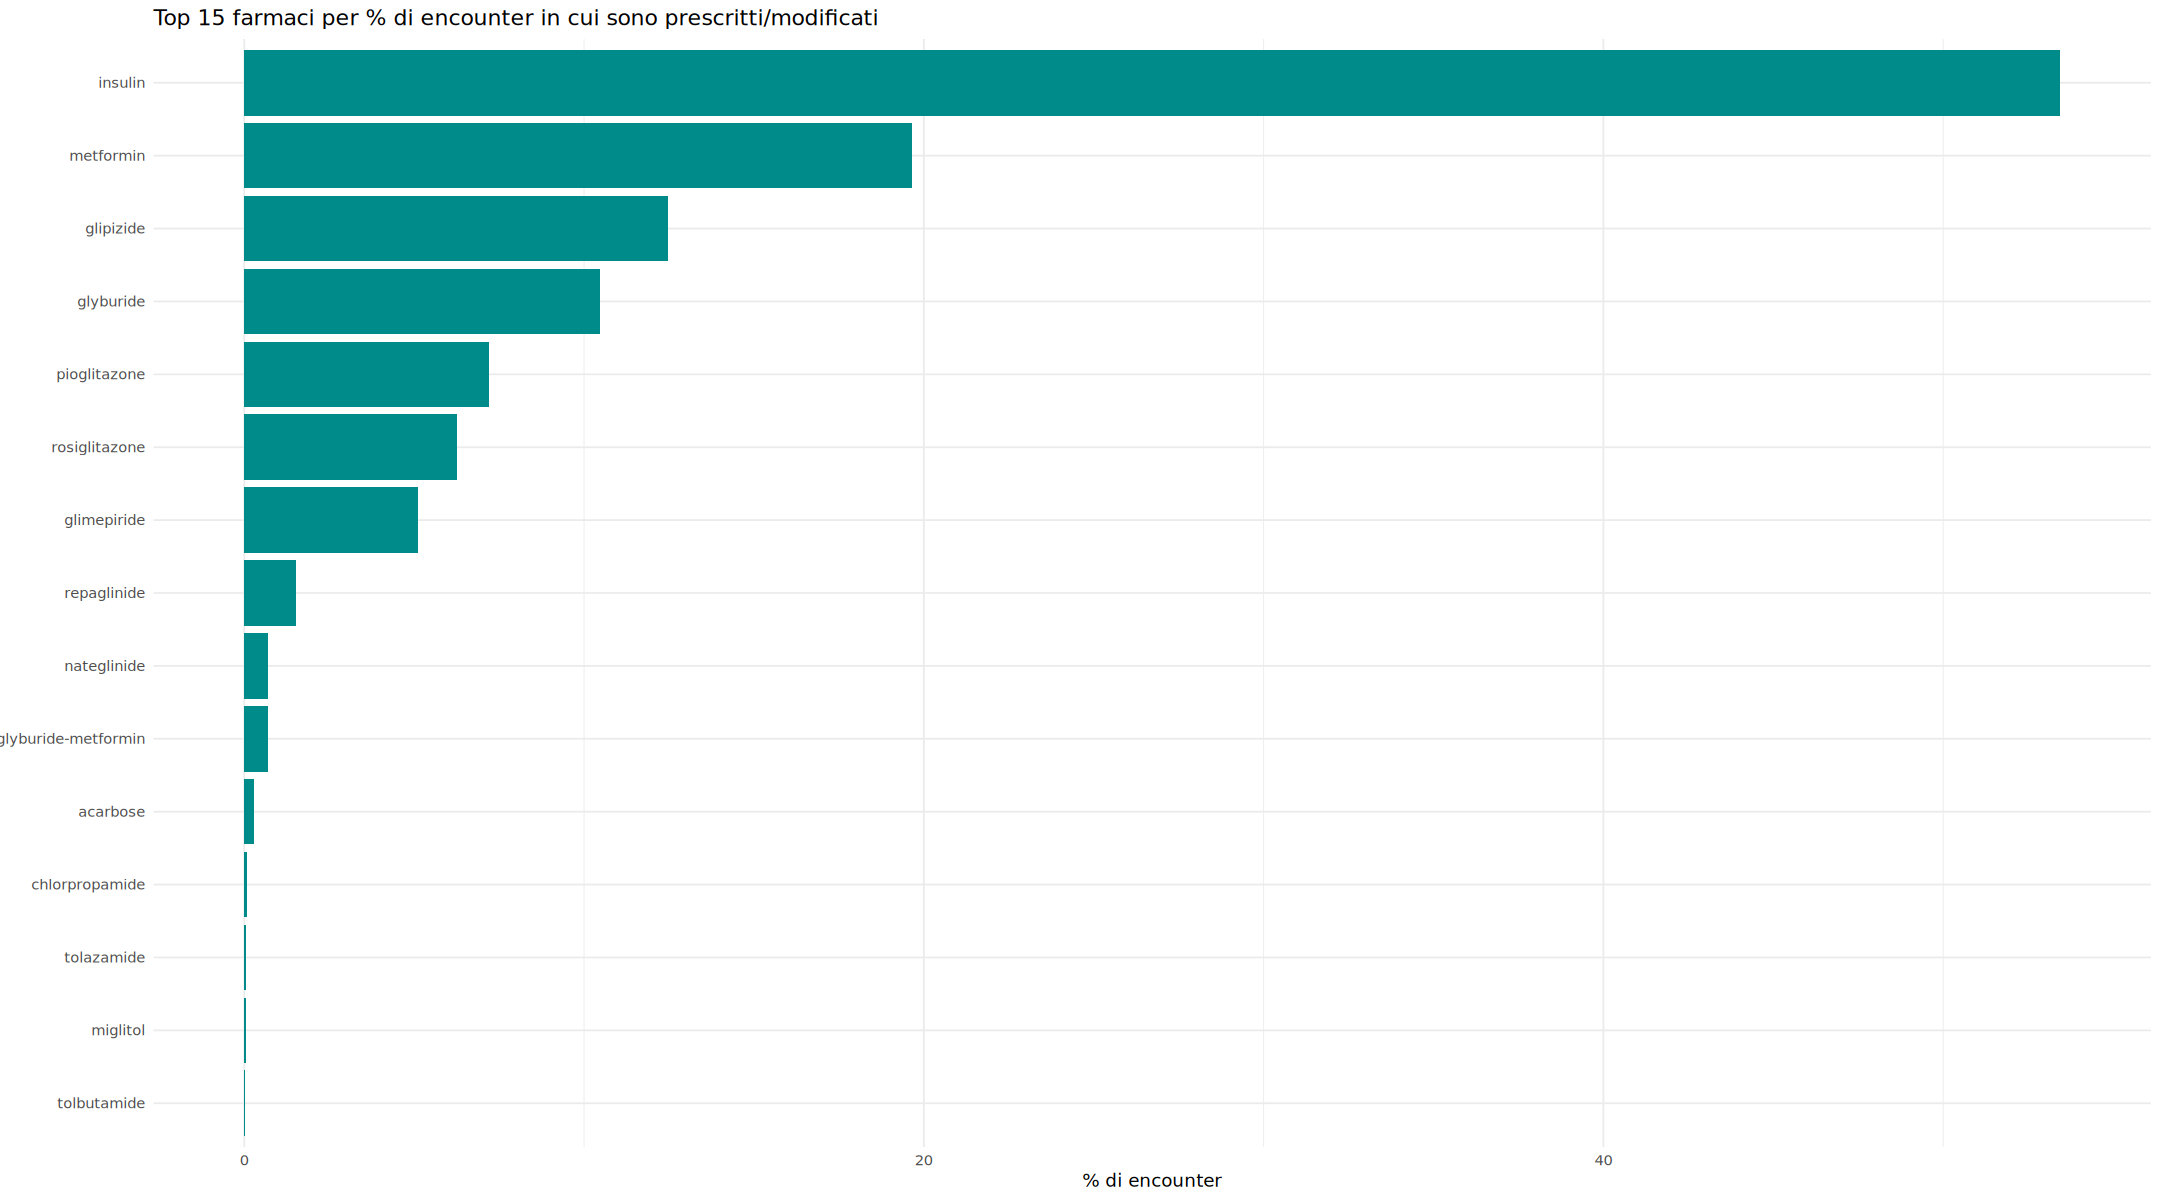

In [47]:
med_cols <- c("metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride",
              "acetohexamide", "glipizide", "glyburide", "tolbutamide", "pioglitazone",
              "rosiglitazone", "acarbose", "miglitol", "troglitazone", "tolazamide",
              "examide", "citoglipton", "insulin", "glyburide-metformin", "glipizide-metformin",
              "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone")

med_summary_df <- df %>%
  select(all_of(med_cols)) %>%
  pivot_longer(cols = everything(), names_to = "farmaco", values_to = "status") %>%
  group_by(farmaco) %>%
  summarise(
    pct_non_prescritto = round(mean(status == "No") * 100, 2),
    pct_prescritto_o_modificato = round(mean(status != "No") * 100, 2),
    .groups = "drop"
  ) %>%
  arrange(desc(pct_prescritto_o_modificato))

p_meds <- med_summary_df %>%
  slice_head(n = 15) %>%
  ggplot(aes(x = pct_prescritto_o_modificato, y = reorder(farmaco, pct_prescritto_o_modificato))) +
  geom_col(fill = "darkcyan") +
  labs(title = "Top 15 farmaci per % di encounter in cui sono prescritti/modificati",
       x = "% di encounter",
       y = NULL) +
  theme_minimal()

p_meds

med_summary_df

**`insulin`** è di gran lunga il farmaco più rilevante: è prescritto o modificato in oltre la metà degli encounter, seguito da `metformin` (circa 20%) e `glipizide`/`glyburide` (10-12%). Numerosi farmaci (gli ultimi nella tabella) sono praticamente assenti dal dataset

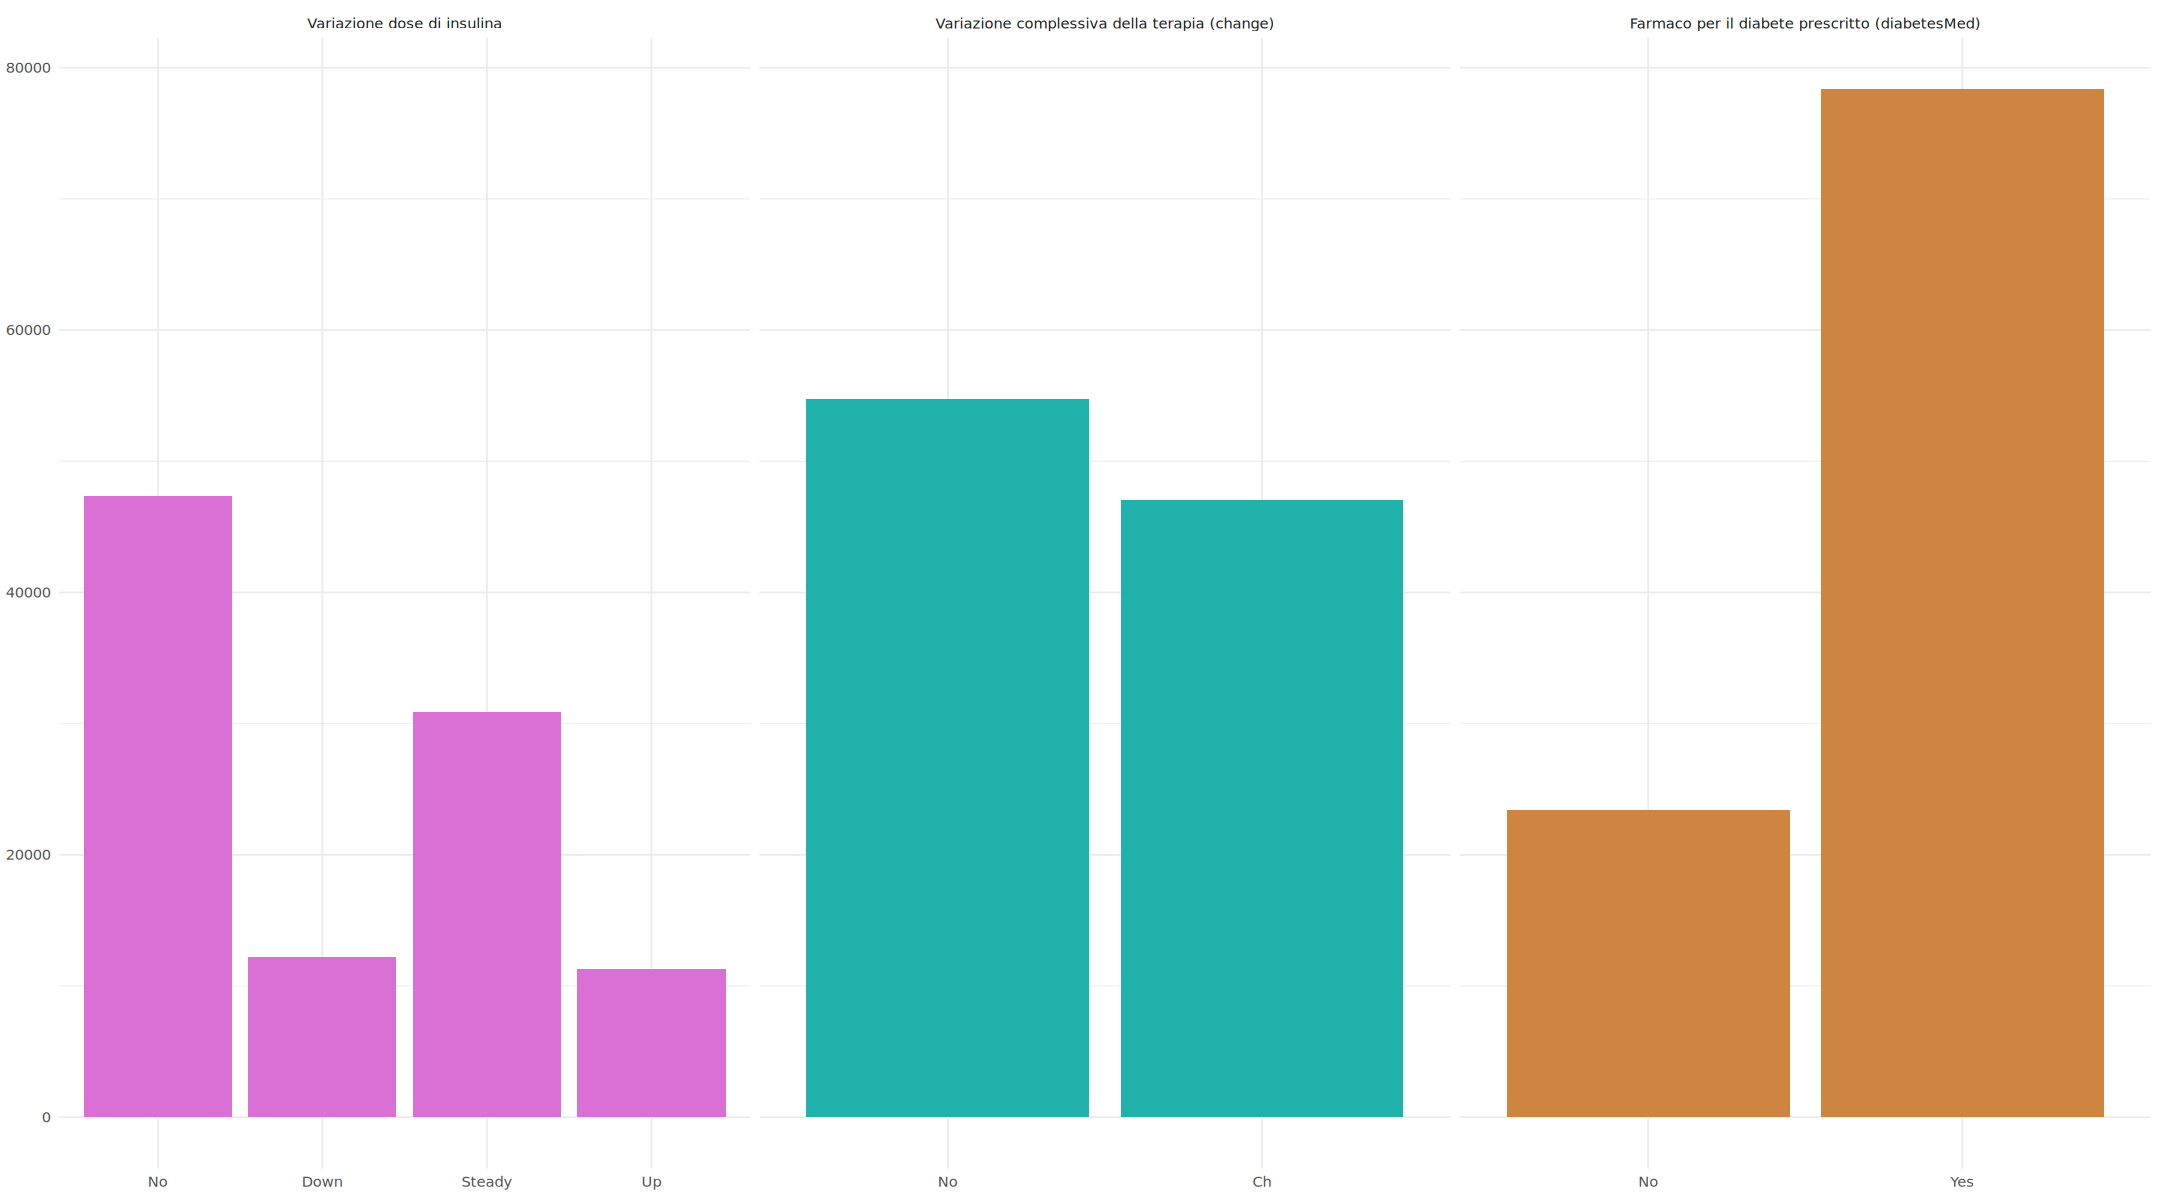

In [48]:
p_combined <- df %>%
  select(insulin, change, diabetesMed) %>%
  pivot_longer(cols = everything(), names_to = "variabile", values_to = "valore") %>%
  mutate(
    valore = factor(valore, levels = c("No", "Down", "Steady", "Up", "Ch", "Yes")),
    variabile = factor(variabile, 
                       levels = c("insulin", "change", "diabetesMed"),
                       labels = c("Variazione dose di insulina", 
                                  "Variazione complessiva della terapia (change)", 
                                  "Farmaco per il diabete prescritto (diabetesMed)"))
  ) %>%
  ggplot(aes(x = valore, fill = variabile)) +
  geom_bar() +
  facet_wrap(~ variabile, scales = "free_x", ncol = 3) +
  scale_fill_manual(values = c("Variazione dose di insulina" = "orchid", 
                               "Variazione complessiva della terapia (change)" = "lightseagreen", 
                               "Farmaco per il diabete prescritto (diabetesMed)" = "peru")) +
  labs(x = NULL, y = NULL) +
  theme_minimal() +
  theme(legend.position = "none")

p_combined

## Analisi bivariata: variabili numeriche vs target

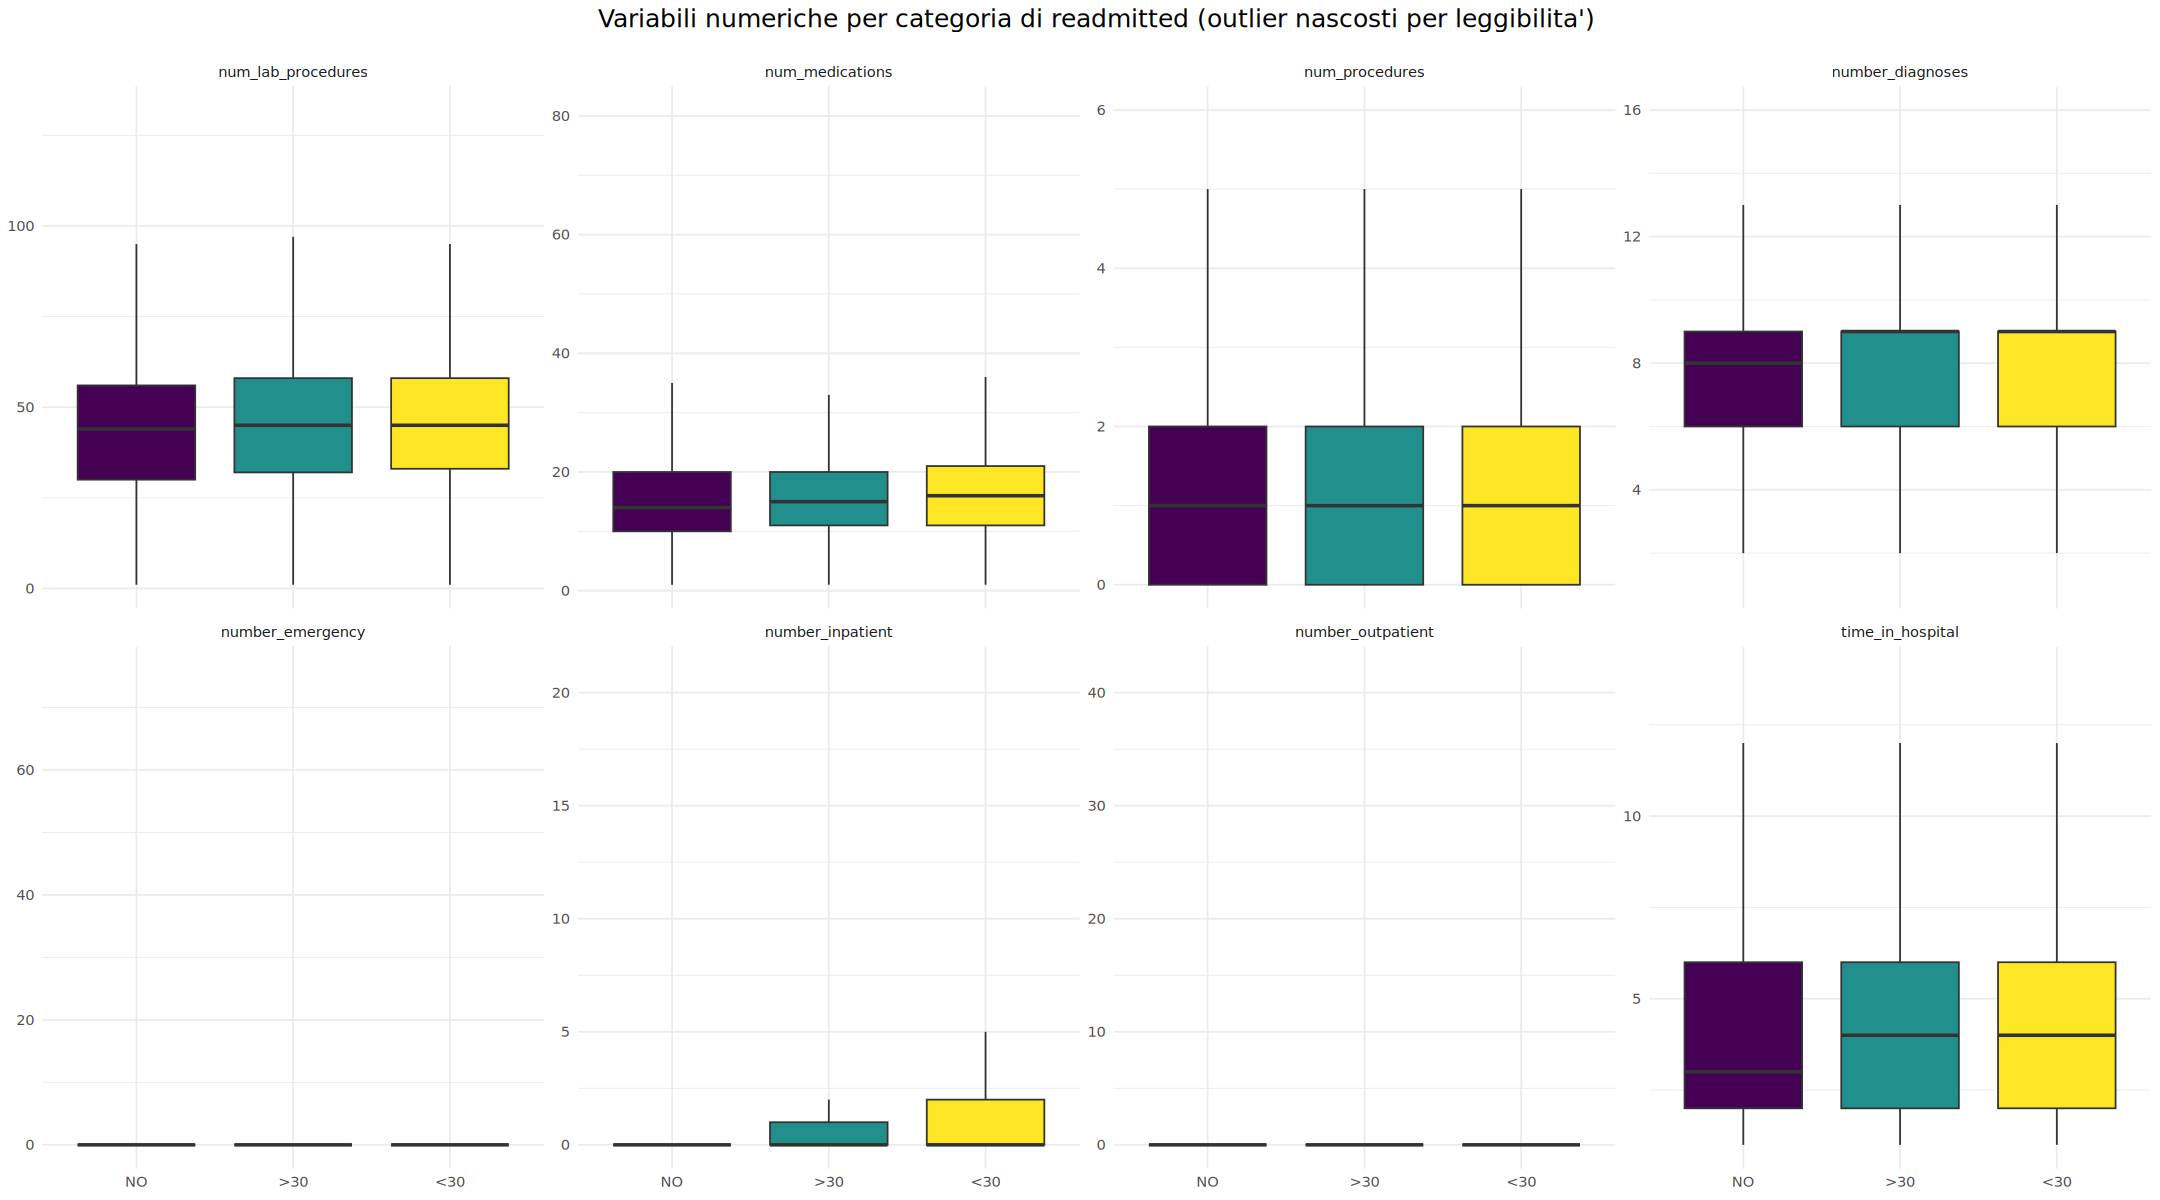

In [49]:
numeric_cols <- c("time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
                  "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses")

p_box_readm <- df %>%
  select(readmitted, all_of(numeric_cols)) %>%
  pivot_longer(cols = -readmitted, names_to = "variabile", values_to = "valore") %>%
  mutate(readmitted = factor(readmitted, levels = c("NO", ">30", "<30"))) %>%
  ggplot(aes(x = readmitted, y = valore, fill = readmitted)) +
  geom_boxplot(outlier.shape = NA) +
  facet_wrap(~ variabile, scales = "free_y", ncol = 4) +
  scale_fill_viridis_d() +
  labs(title = "Variabili numeriche per categoria di readmitted (outlier nascosti per leggibilita')",
       x = NULL,
       y = NULL) +
  theme_minimal() +
  theme(plot.title = element_text(size = 15, hjust = 0.5, margin = margin(b = 15)),
        legend.position = "none")

p_box_readm

In [50]:
df %>%
  mutate(readmitted = factor(readmitted, levels = c("NO", ">30", "<30"))) %>%
  group_by(readmitted) %>%
  summarise(across(all_of(numeric_cols), ~ round(mean(.x, na.rm = TRUE), 2))) %>%
  arrange(readmitted)

readmitted,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
NO,4.25,42.38,1.41,15.67,0.27,0.11,0.38,7.22
>30,4.50,43.84,1.25,16.28,0.50,0.28,0.84,7.65
<30,4.77,44.23,1.28,16.90,0.44,0.36,1.22,7.69


Le differenze più marcate riguardano `number_inpatient`, `number_emergency` e `number_outpatient`: i pazienti riammessi entro 30 giorni avevano, in media, **già un numero di ricoveri/visite pregresse decisamente più alto**. È un segnale molto intuitivo e clinicamente sensato: la storia di utilizzo recente del sistema sanitario è uno dei migliori predittori di riammissione futura.

## Analisi bivariata: variabili categoriche vs target

Per ciascuna variabile categorica di interesse calcoliamo la distribuzione di `readmitted` al suo interno e un test del chi-quadrato di indipendenza.

Test chi-quadro 'age' vs 'readmitted':  chi2 = 313.2,  p-value = 9.35e-56



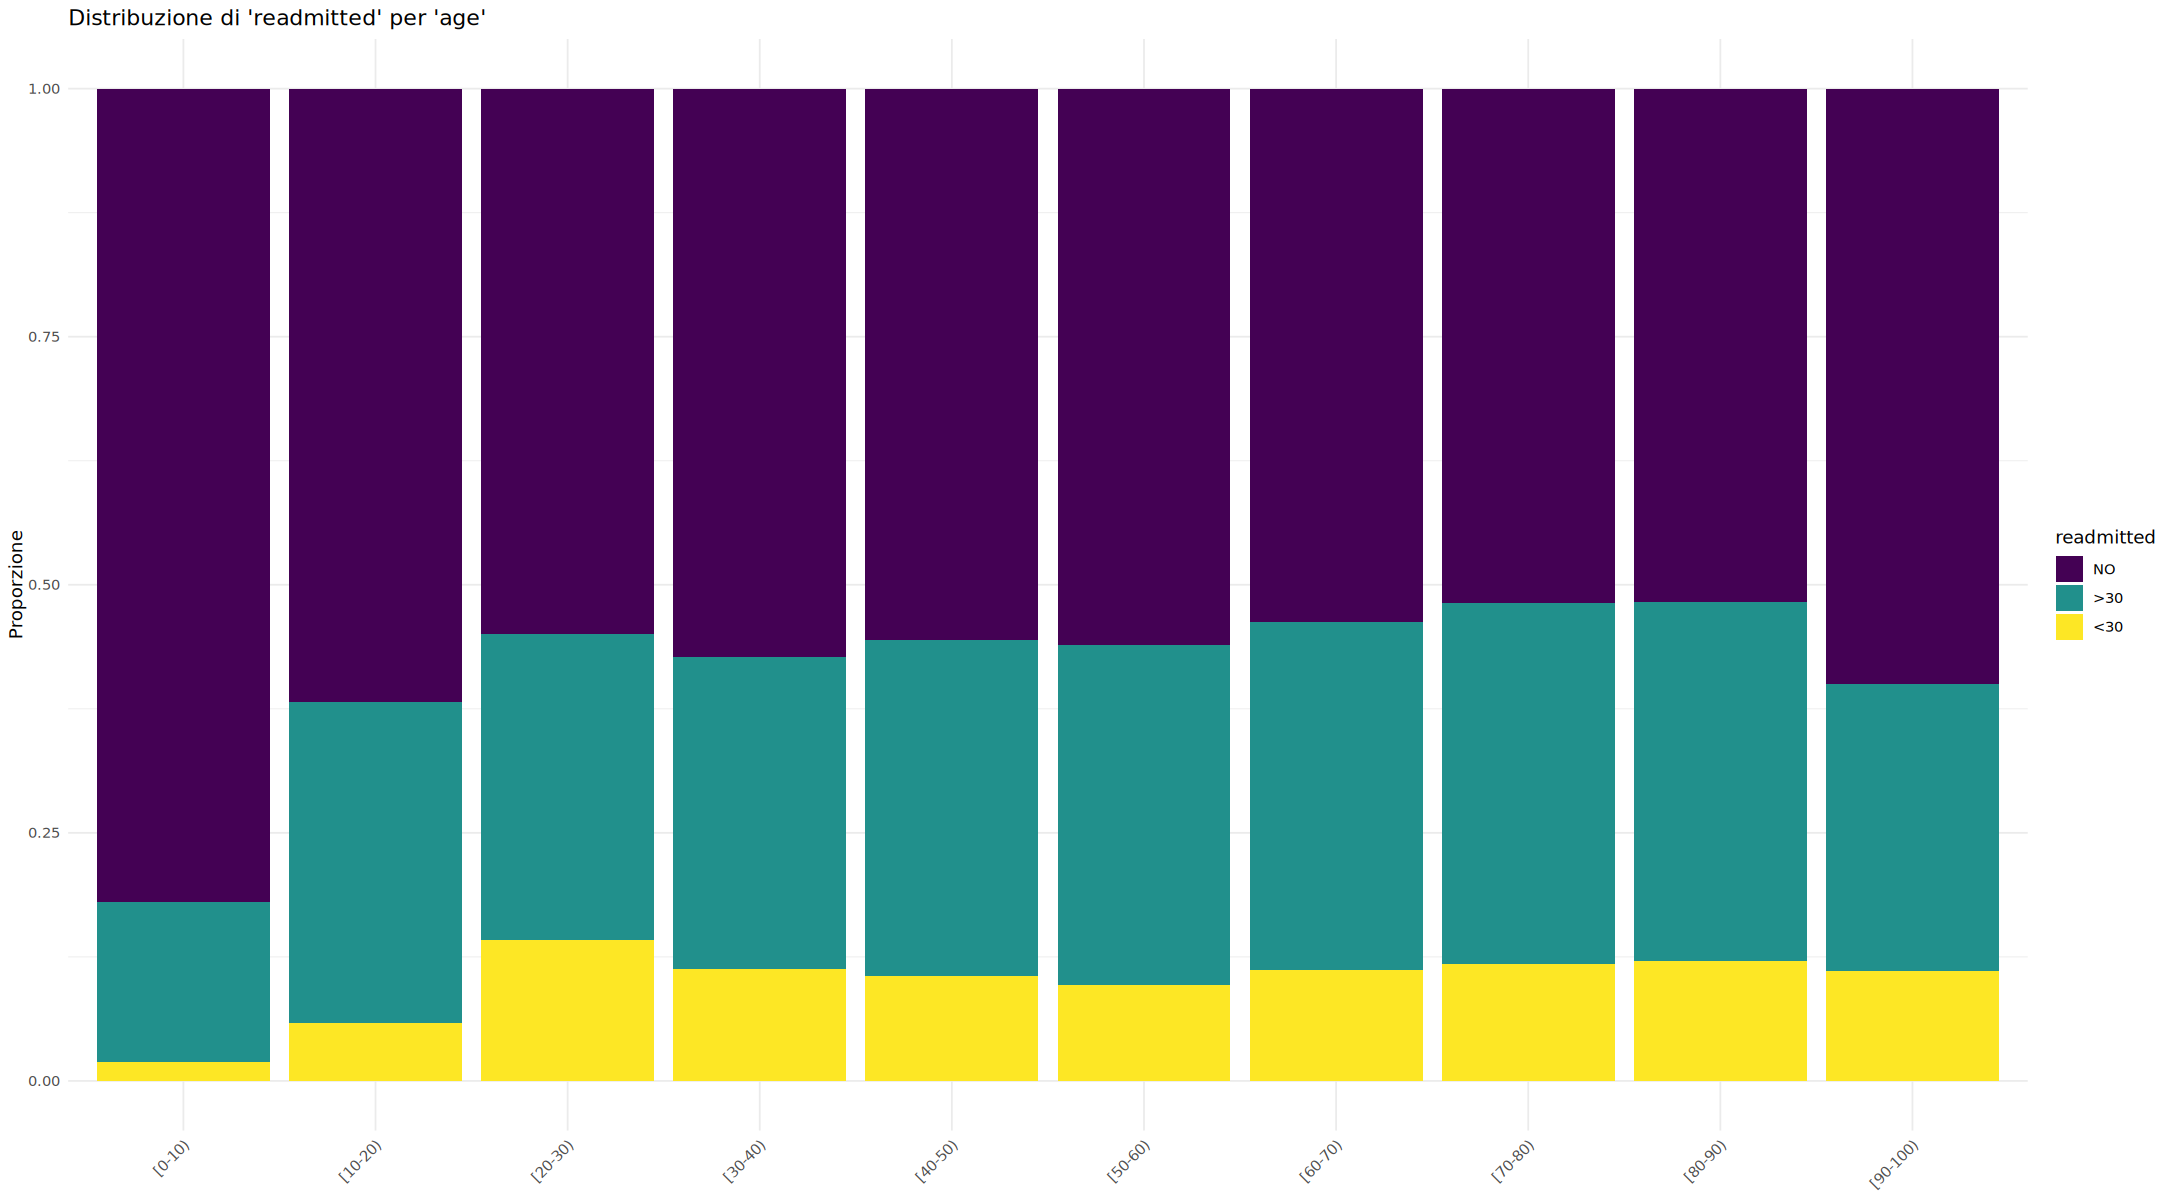

Test chi-quadro 'gender' vs 'readmitted':  chi2 = 37.5,  p-value = 1.45e-07



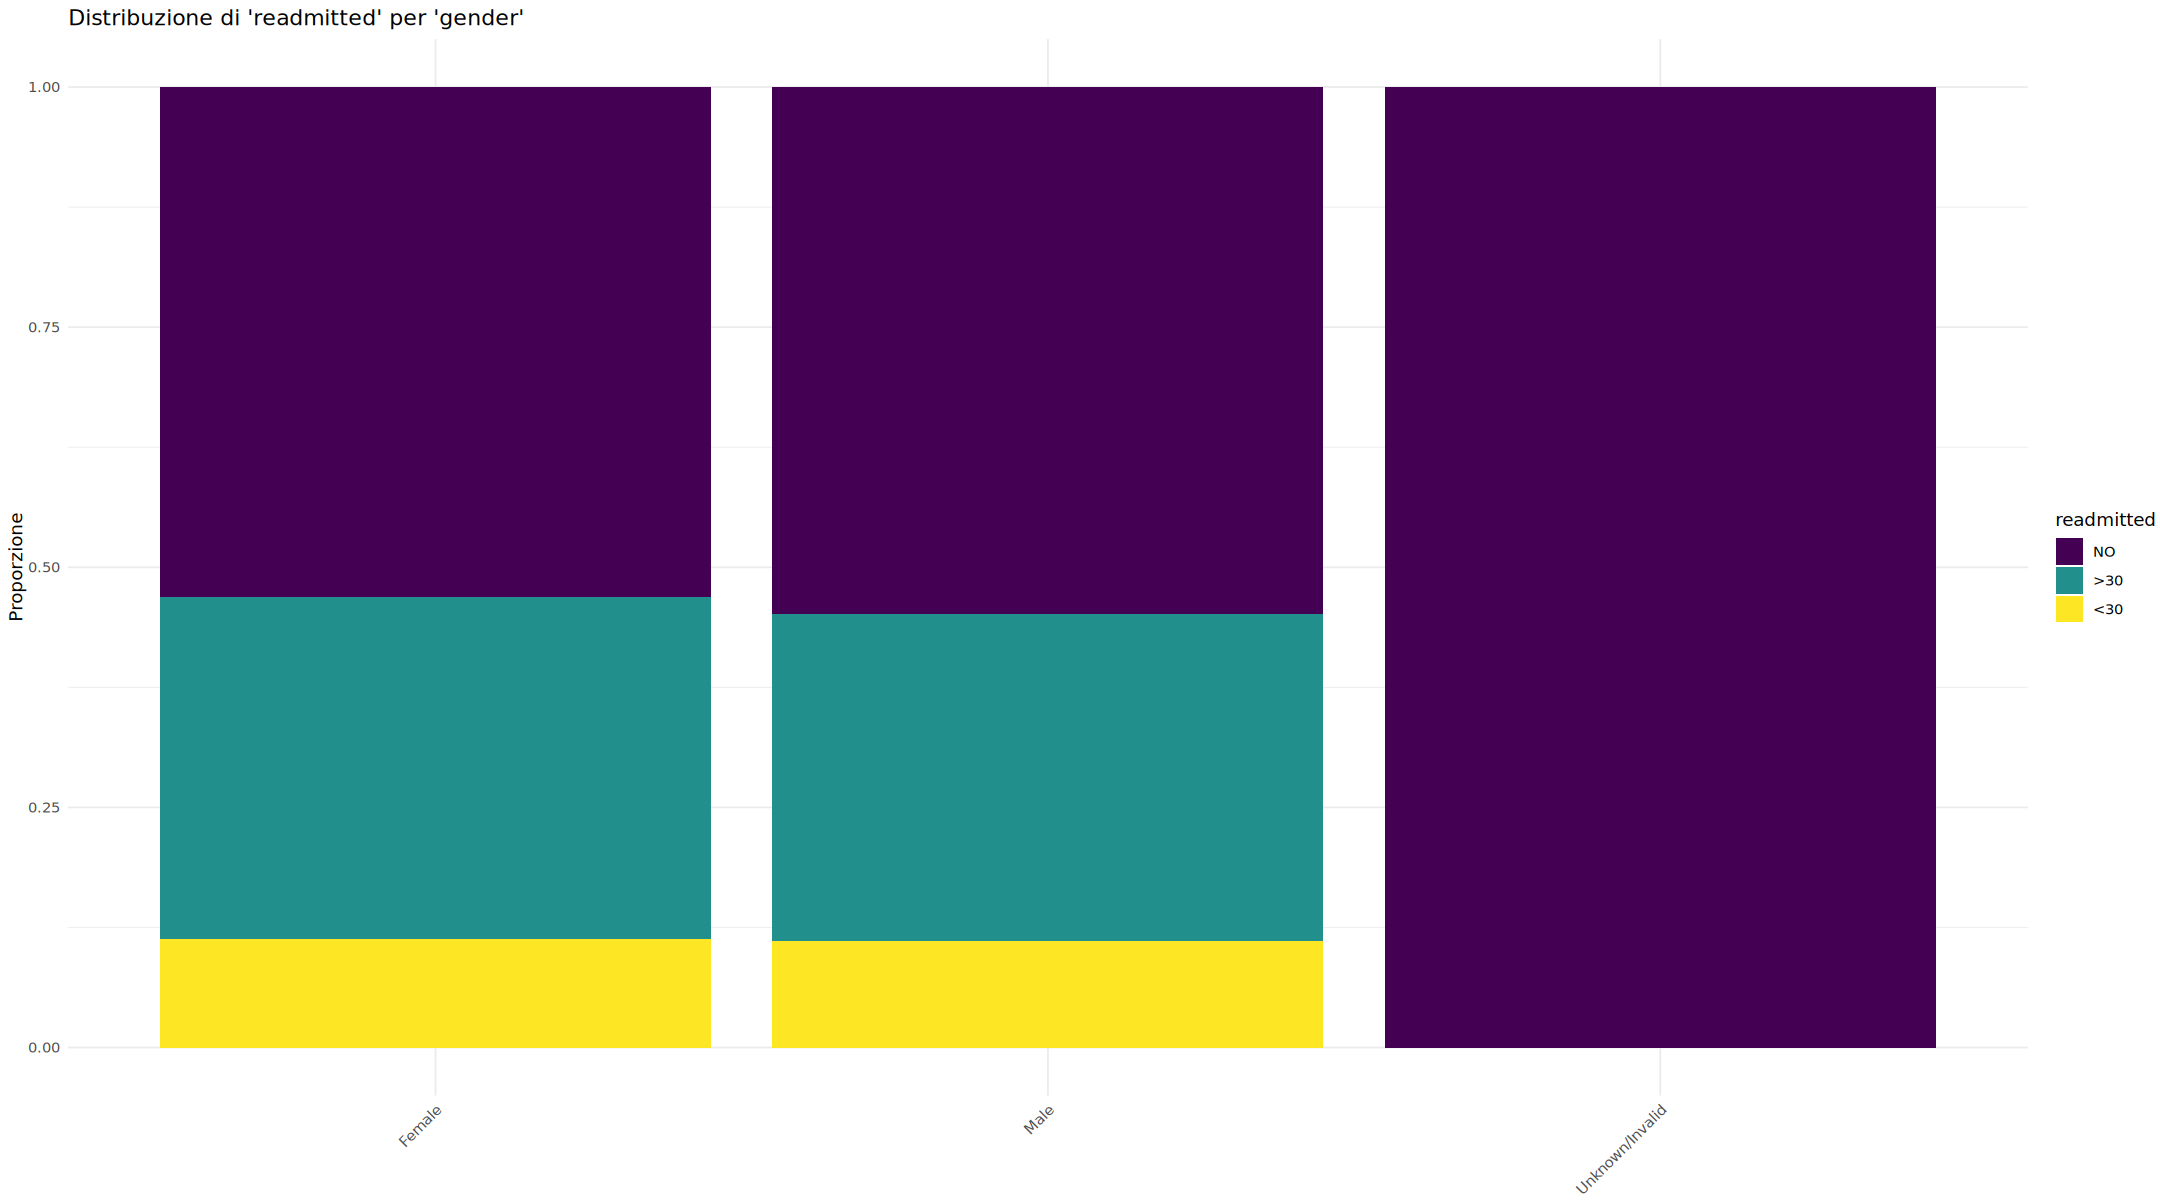

Test chi-quadro 'race' vs 'readmitted':  chi2 = 94.4,  p-value = 5.96e-17



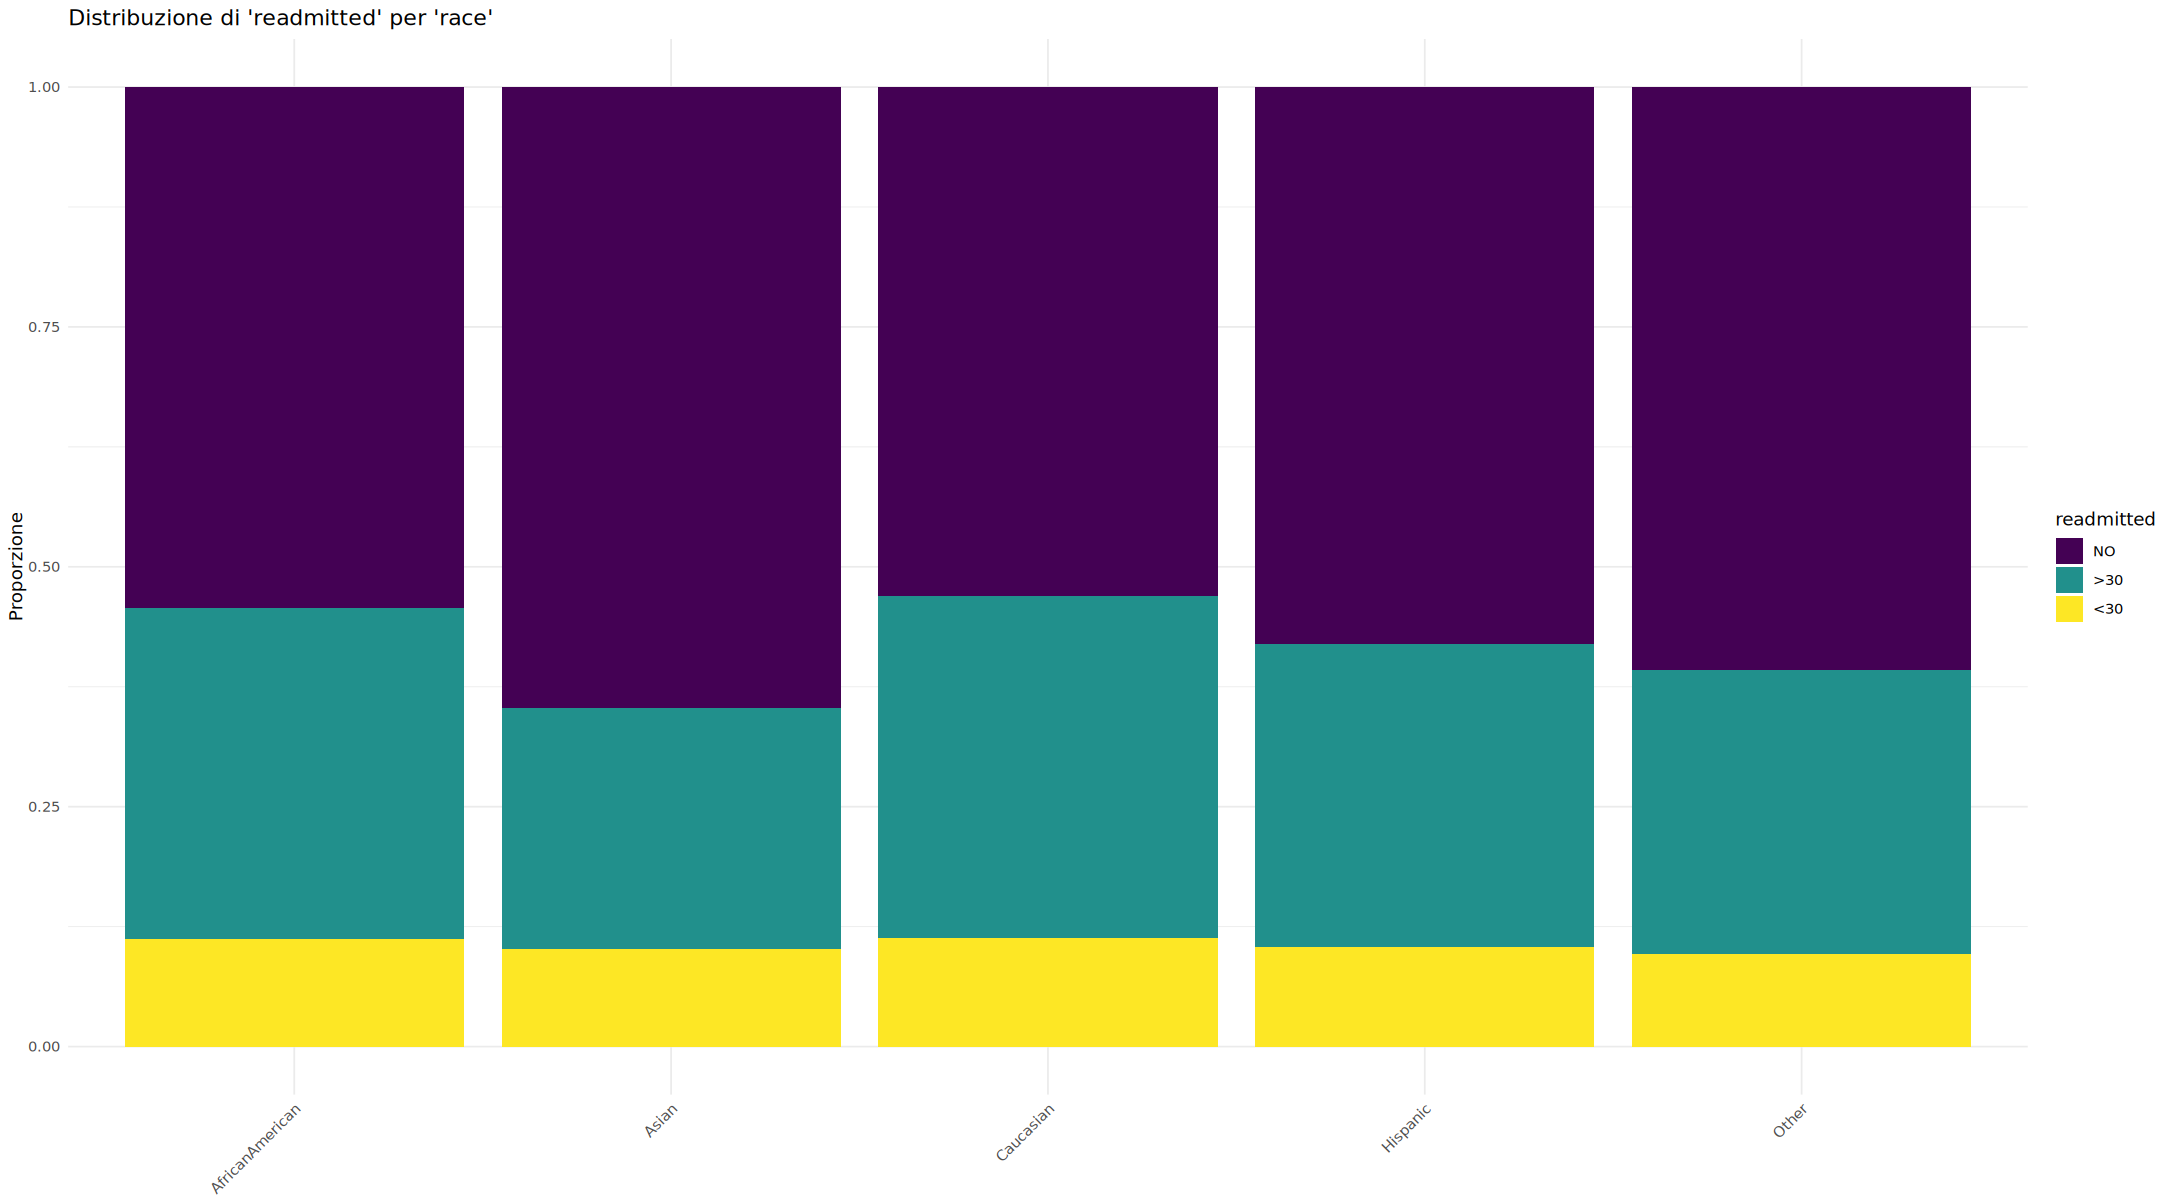

Test chi-quadro 'admission_type_desc' vs 'readmitted':  chi2 = 415.8,  p-value = 6.04e-80



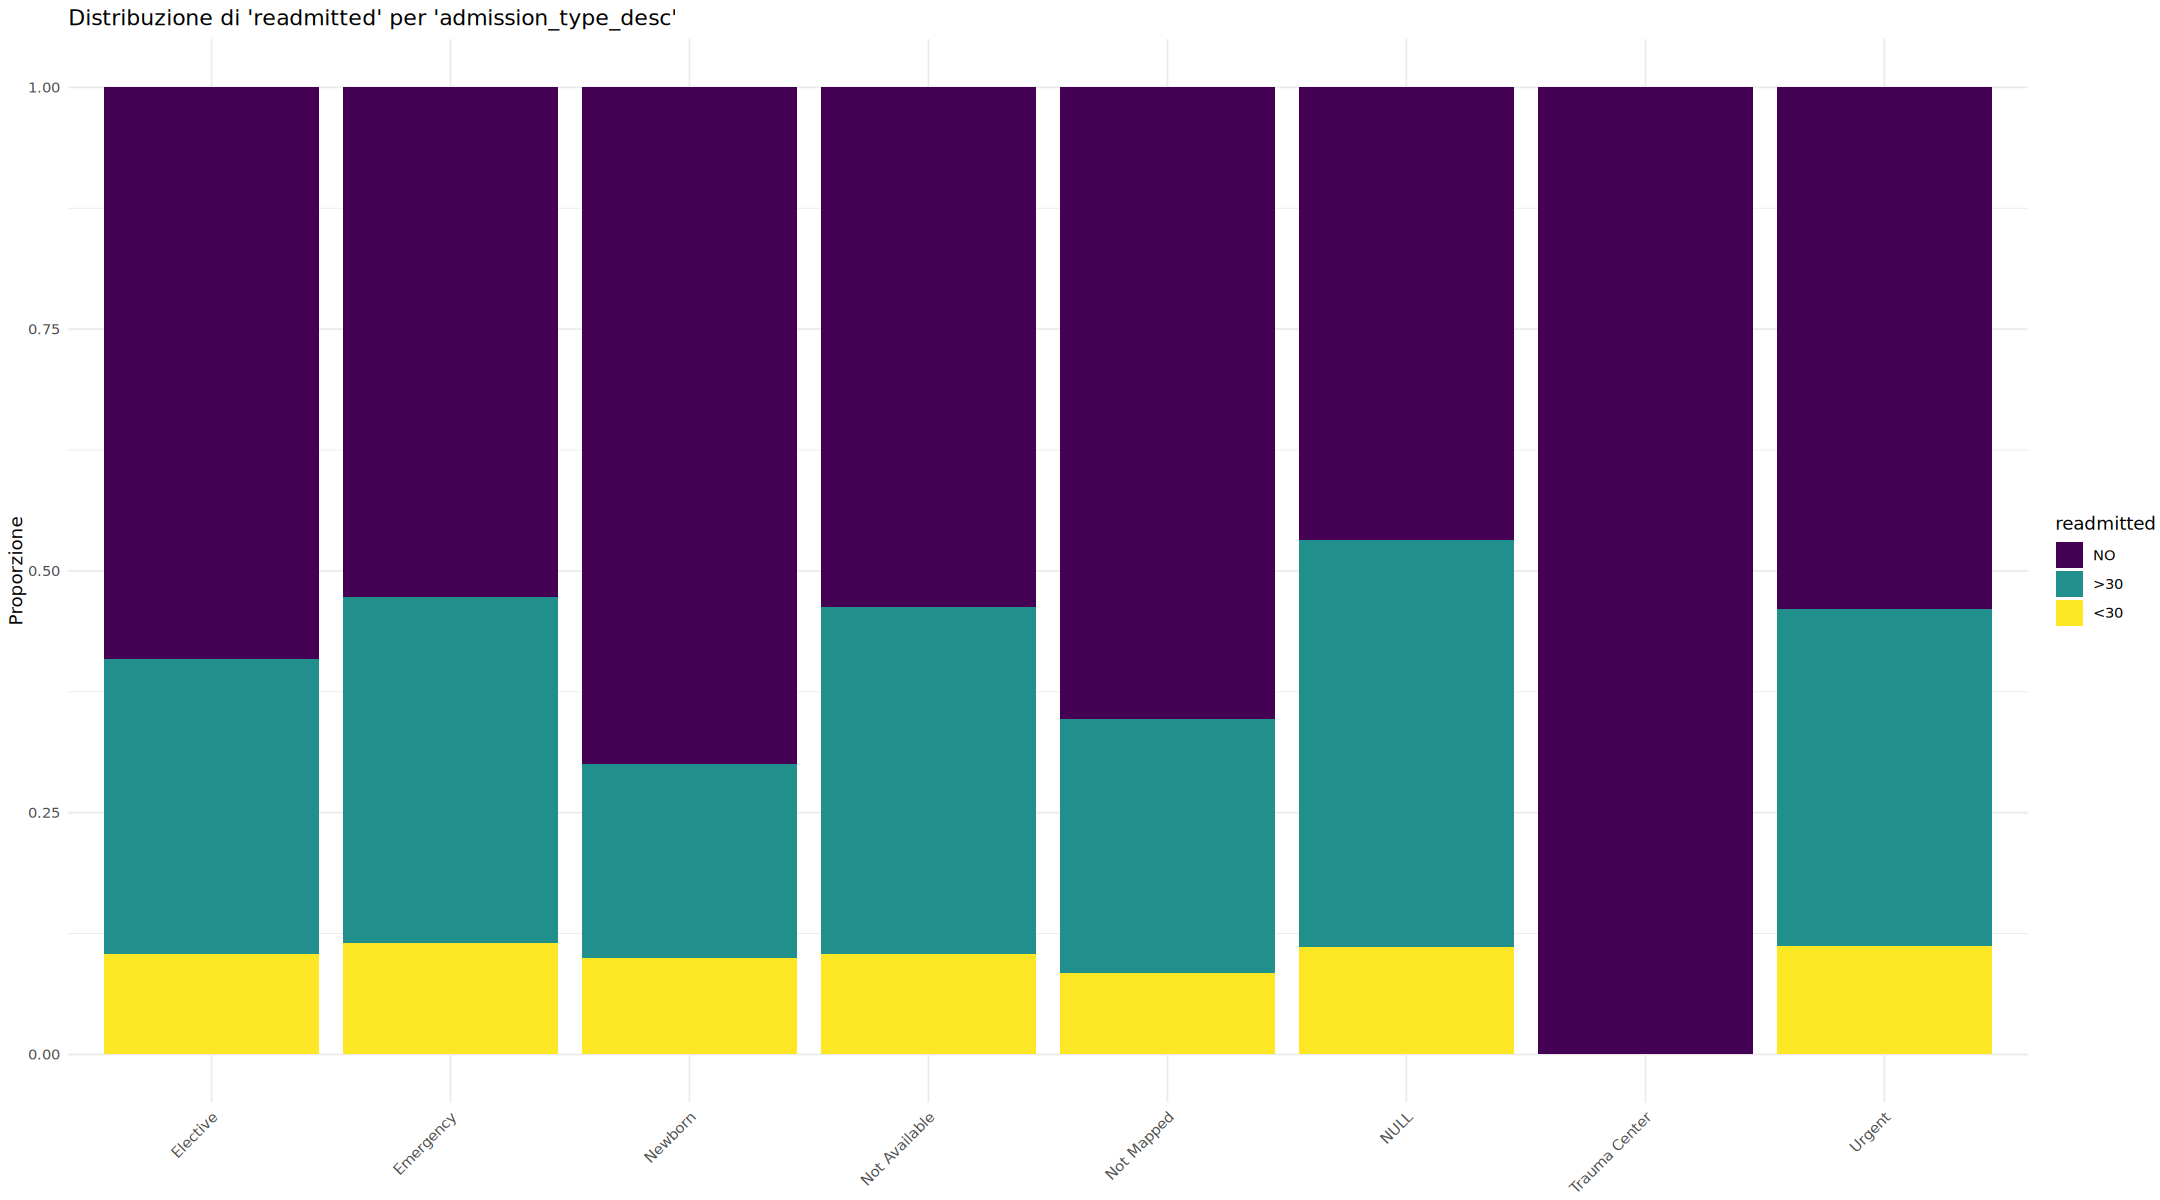

Test chi-quadro 'diag_1_category' vs 'readmitted':  chi2 = 560.9,  p-value = 1.56e-107



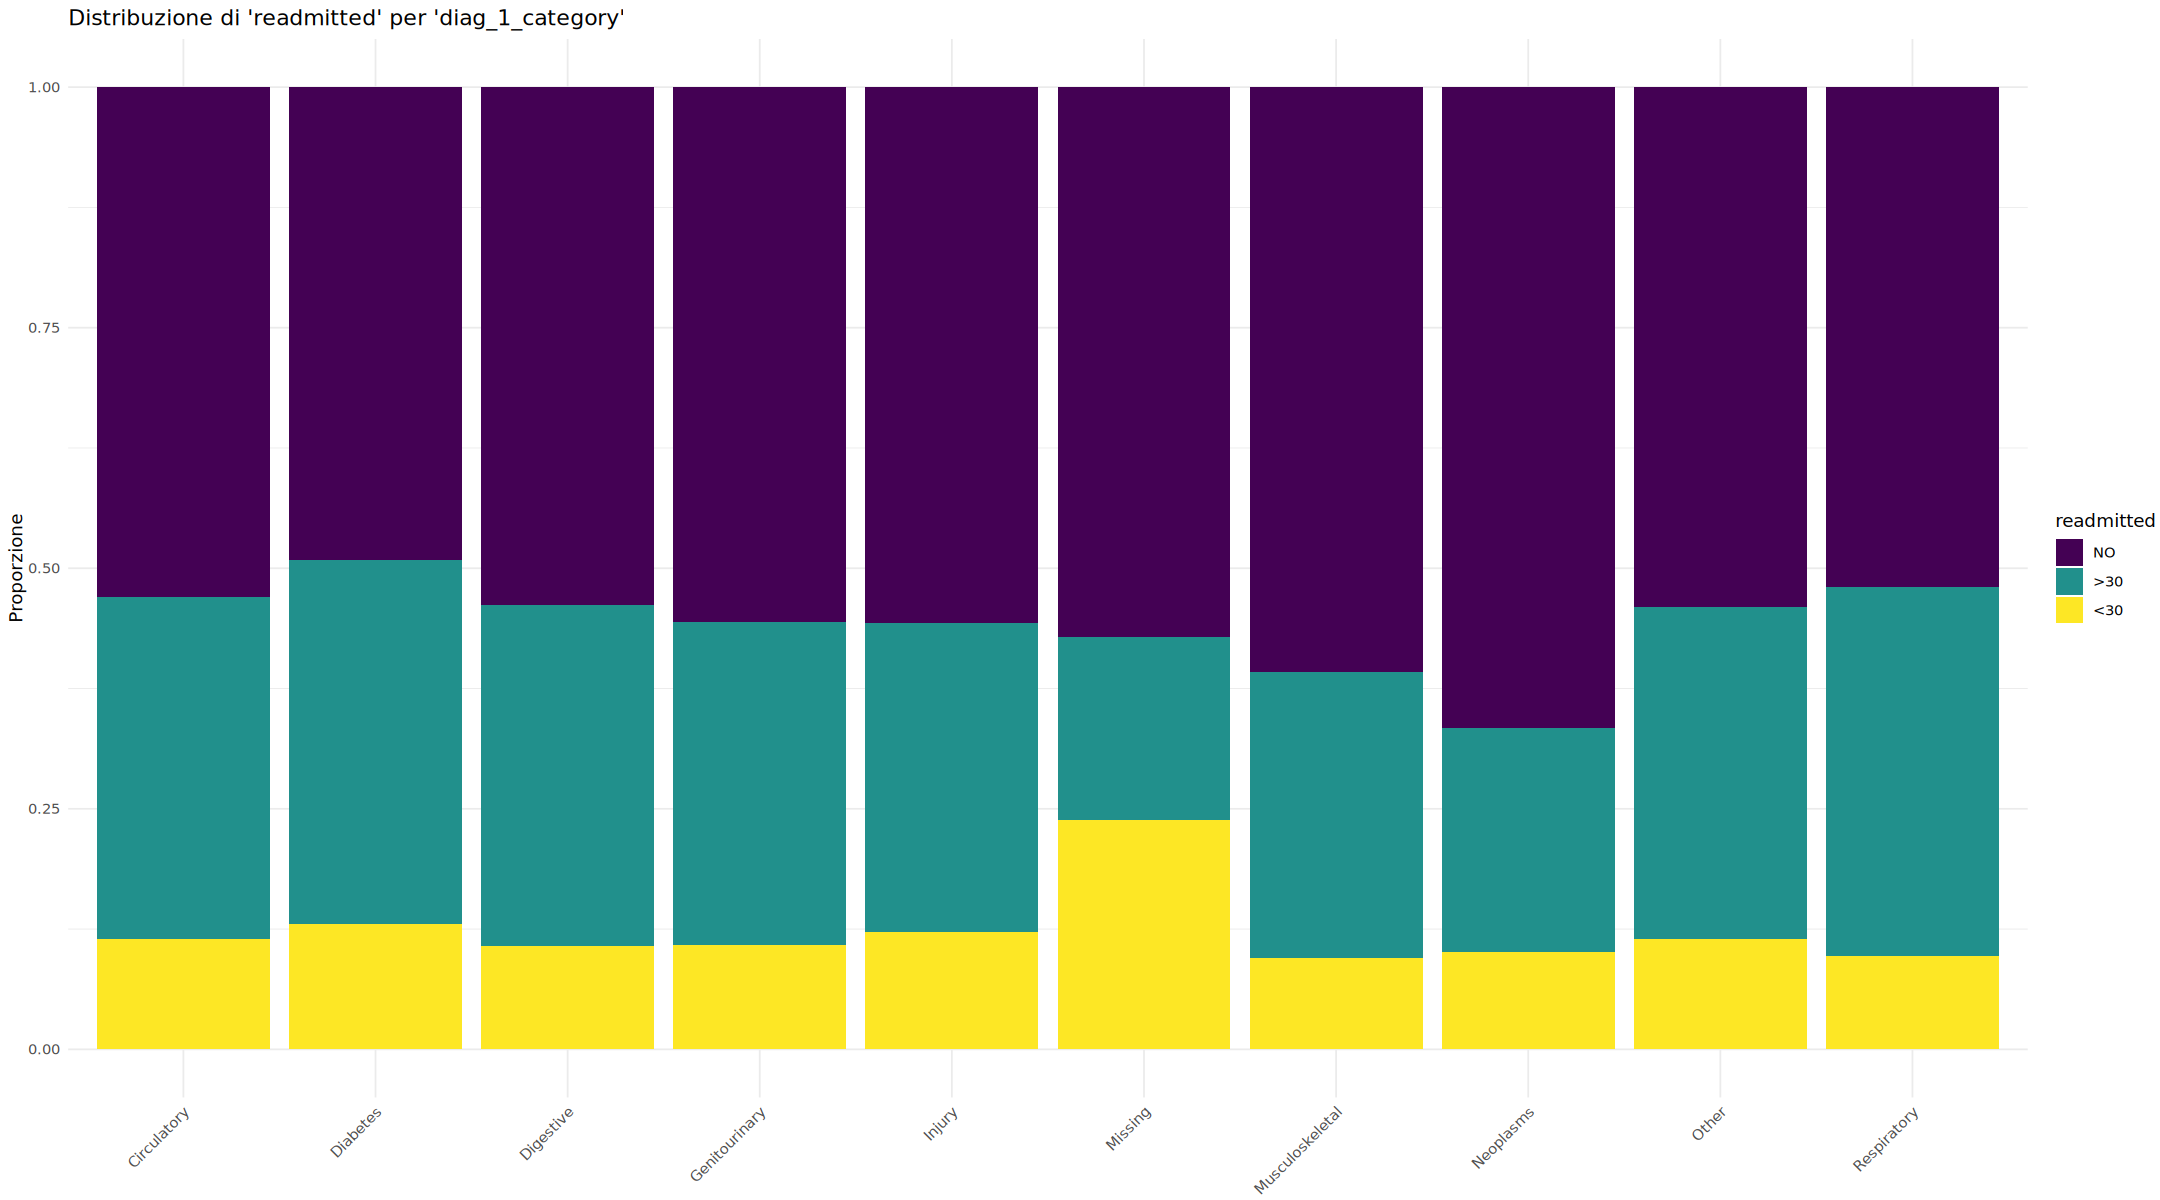

Test chi-quadro 'A1Cresult' vs 'readmitted':  chi2 = 70.1,  p-value = 3.86e-13



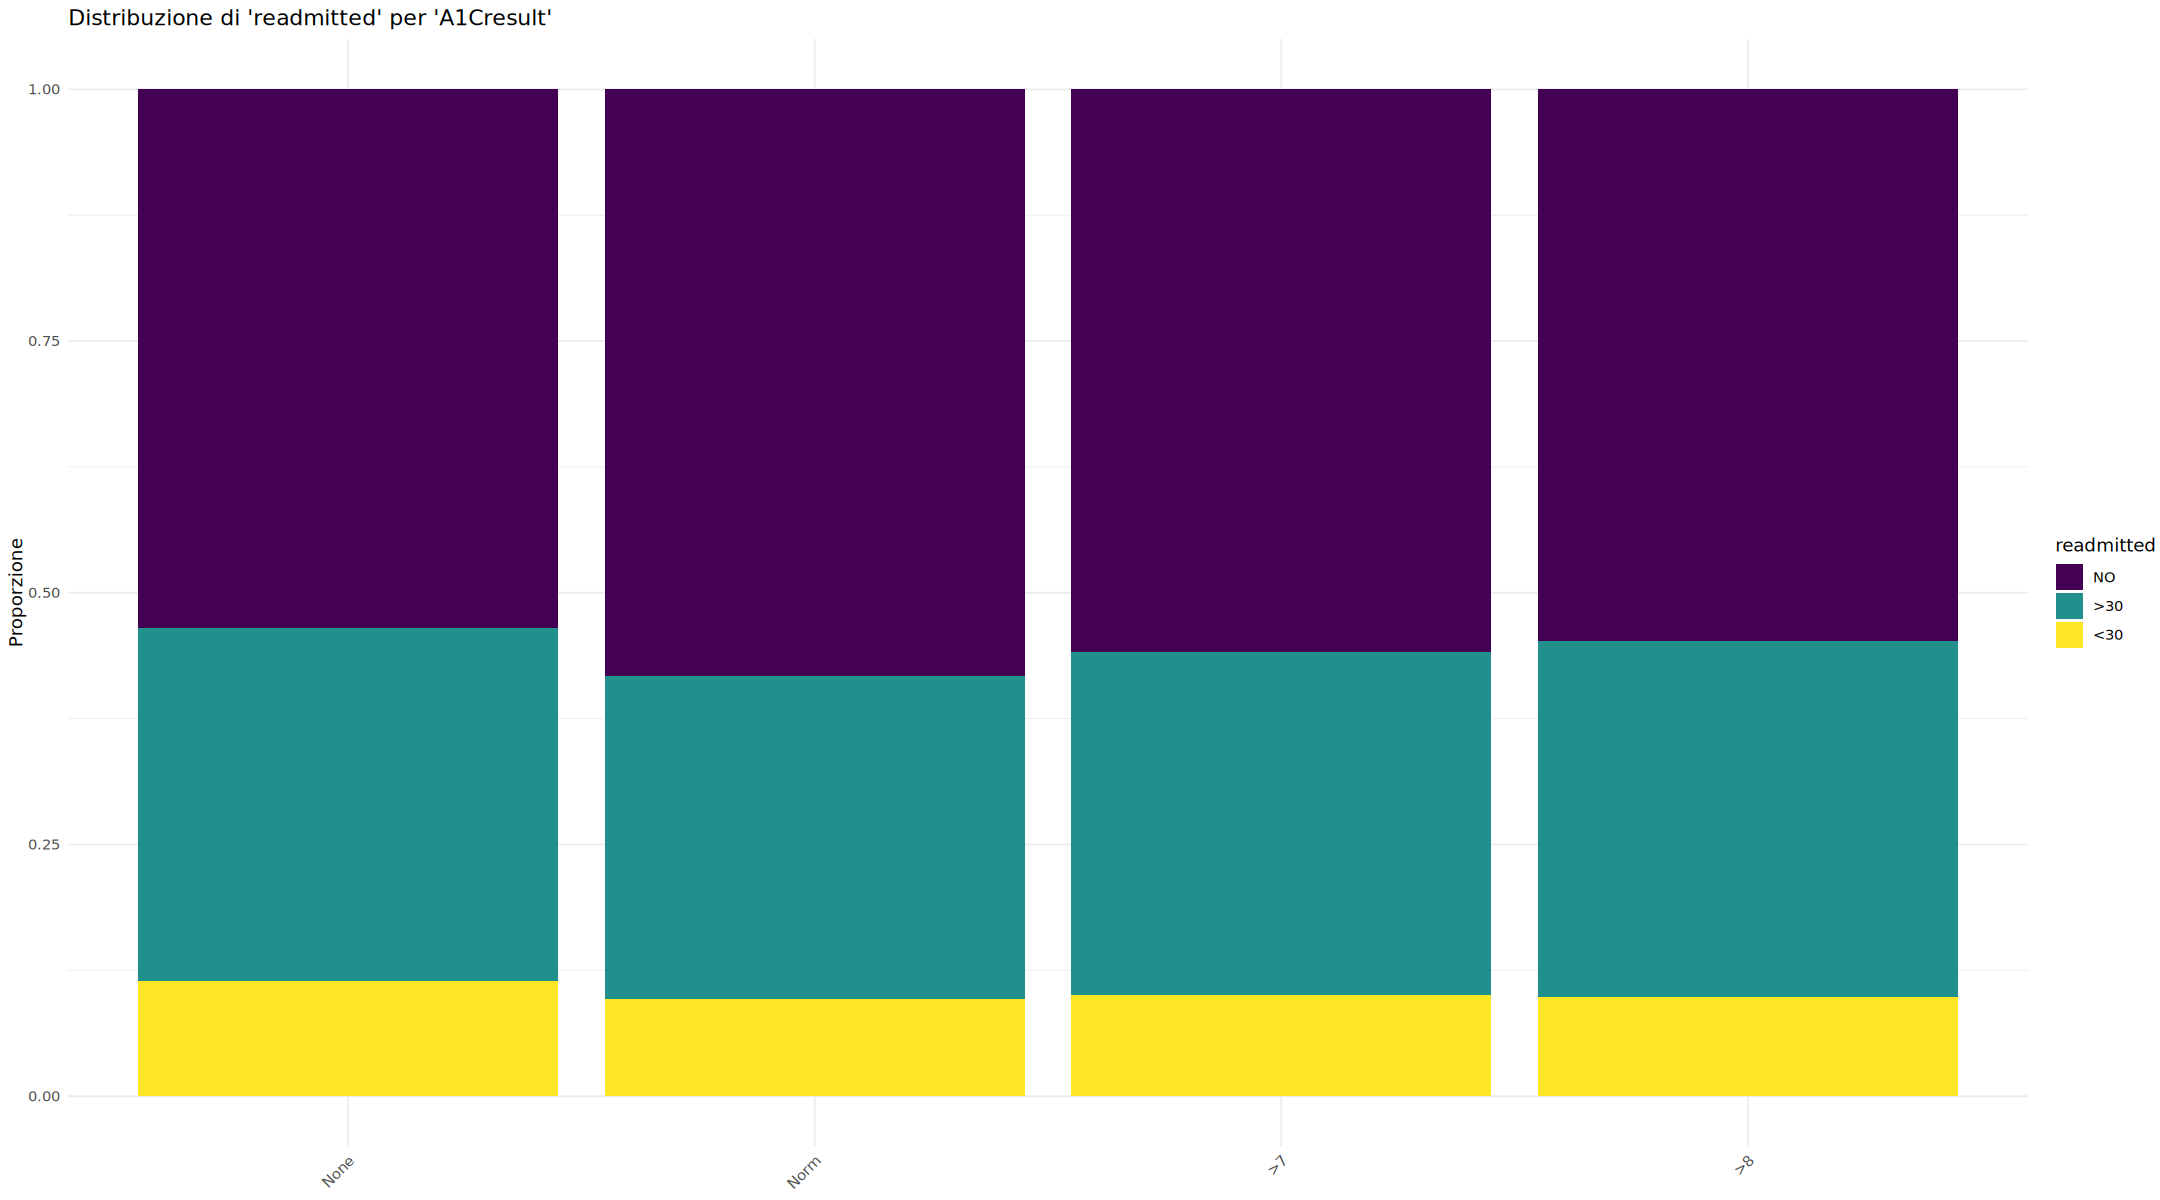

Test chi-quadro 'max_glu_serum' vs 'readmitted':  chi2 = 51.9,  p-value = 1.93e-09



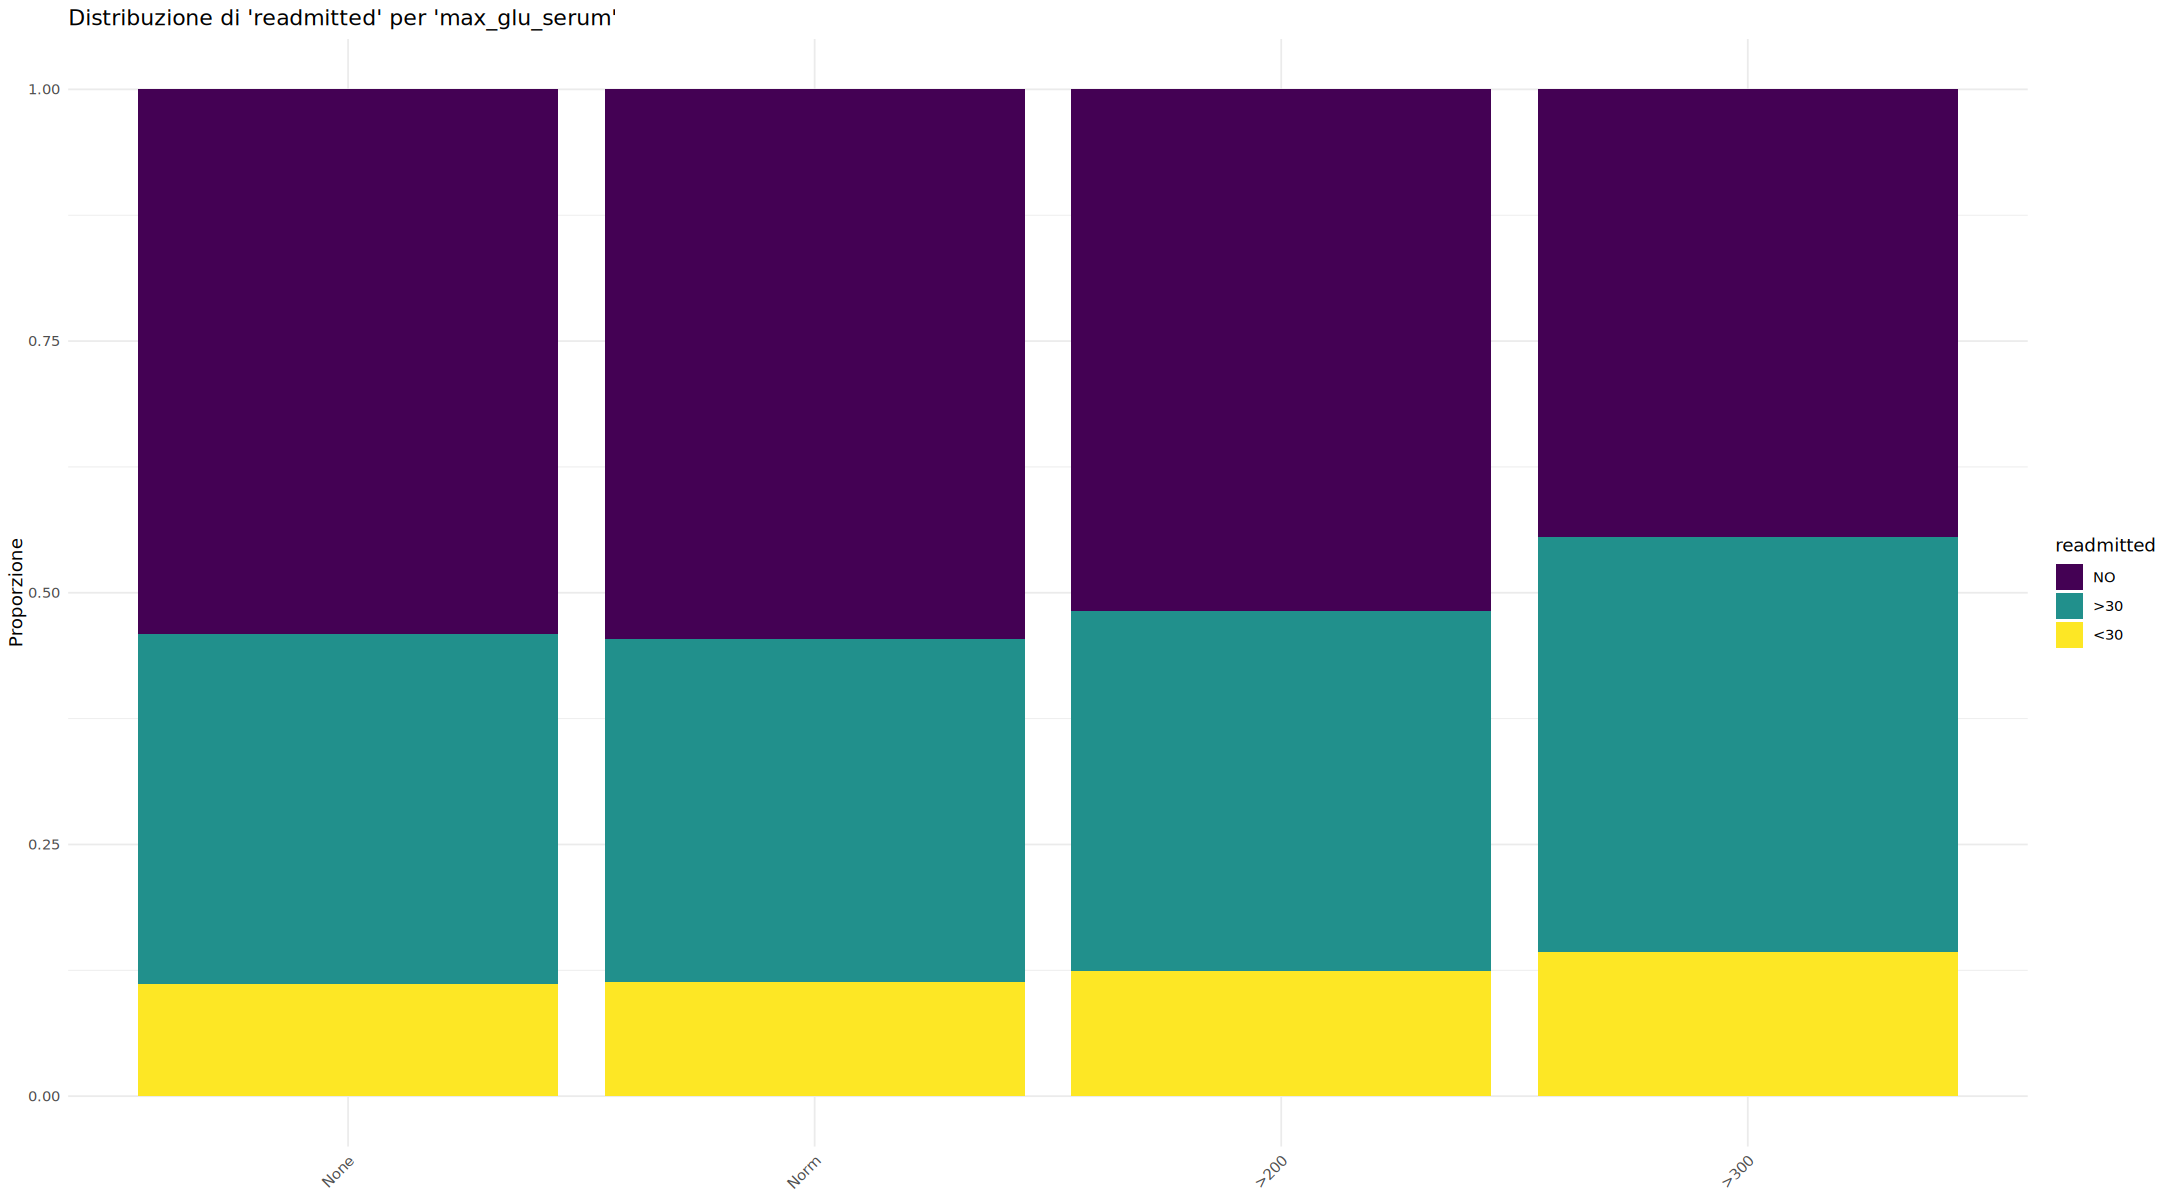

Test chi-quadro 'insulin' vs 'readmitted':  chi2 = 516.7,  p-value = 2.13e-108



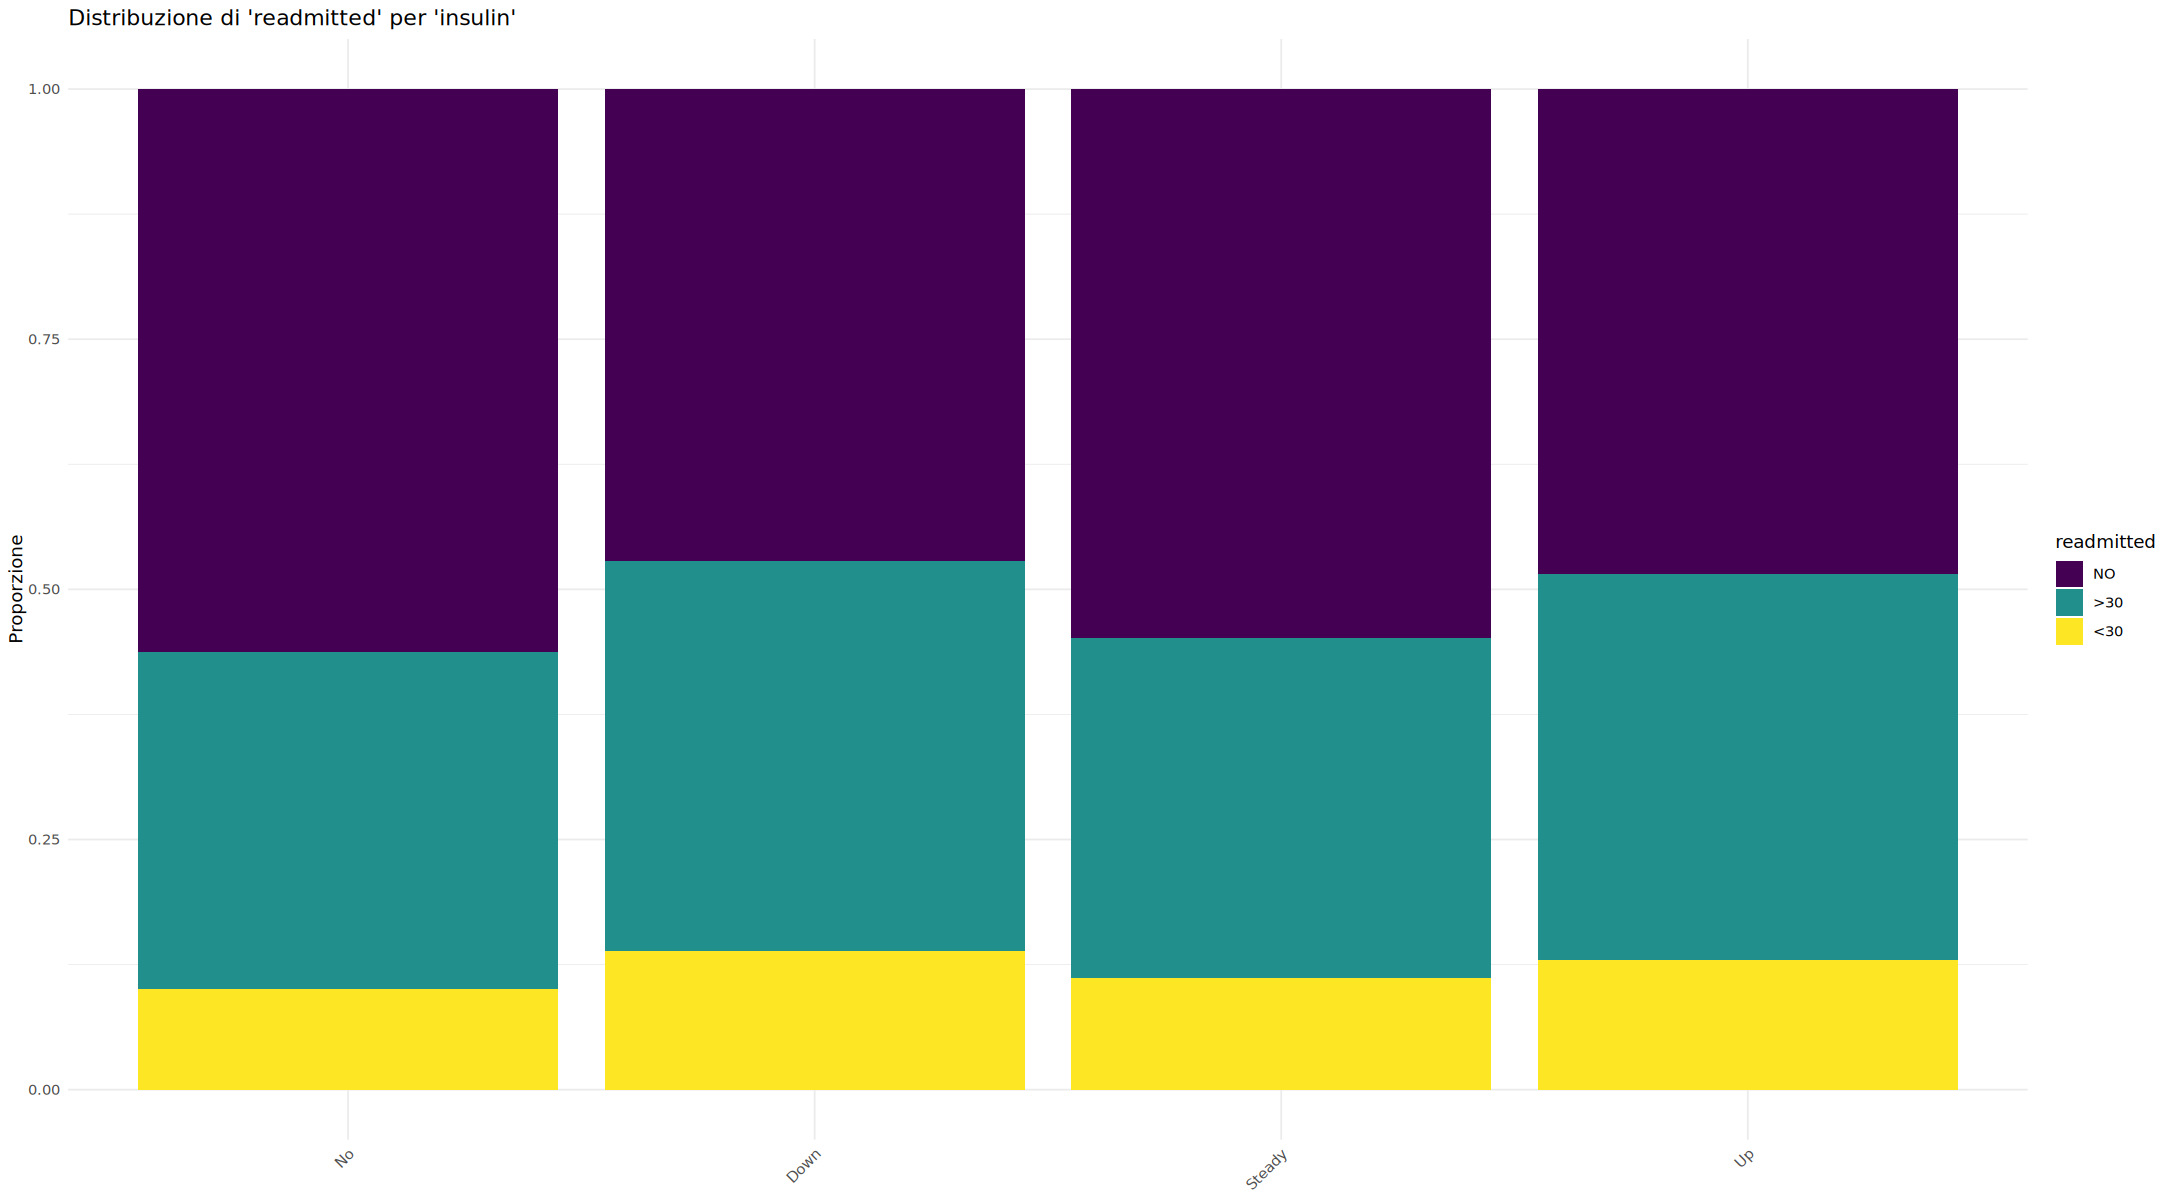

Test chi-quadro 'change' vs 'readmitted':  chi2 = 215.8,  p-value = 1.36e-47



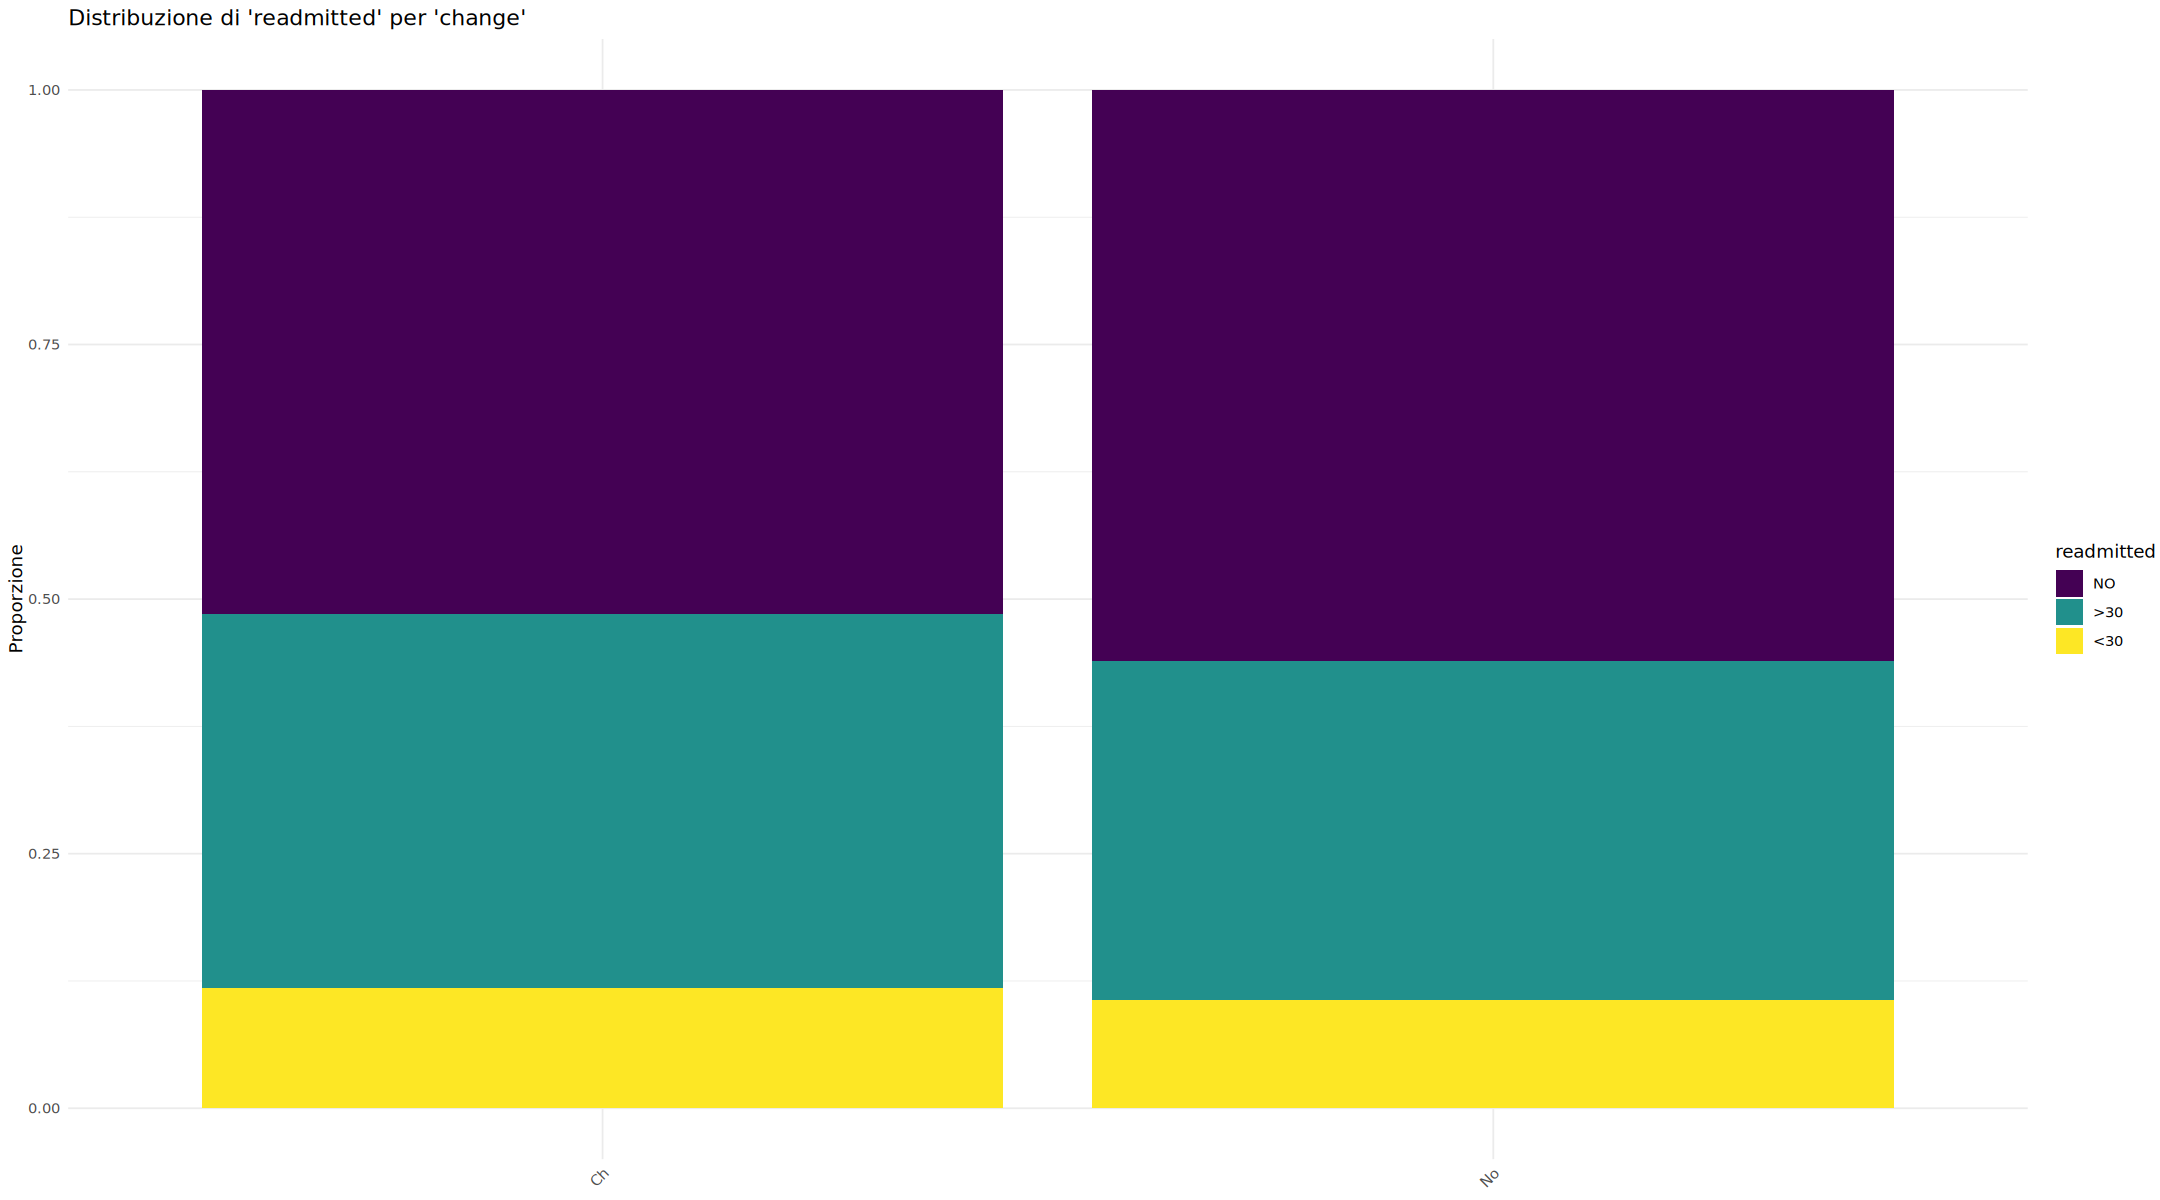

Test chi-quadro 'diabetesMed' vs 'readmitted':  chi2 = 386.5,  p-value = 1.18e-84



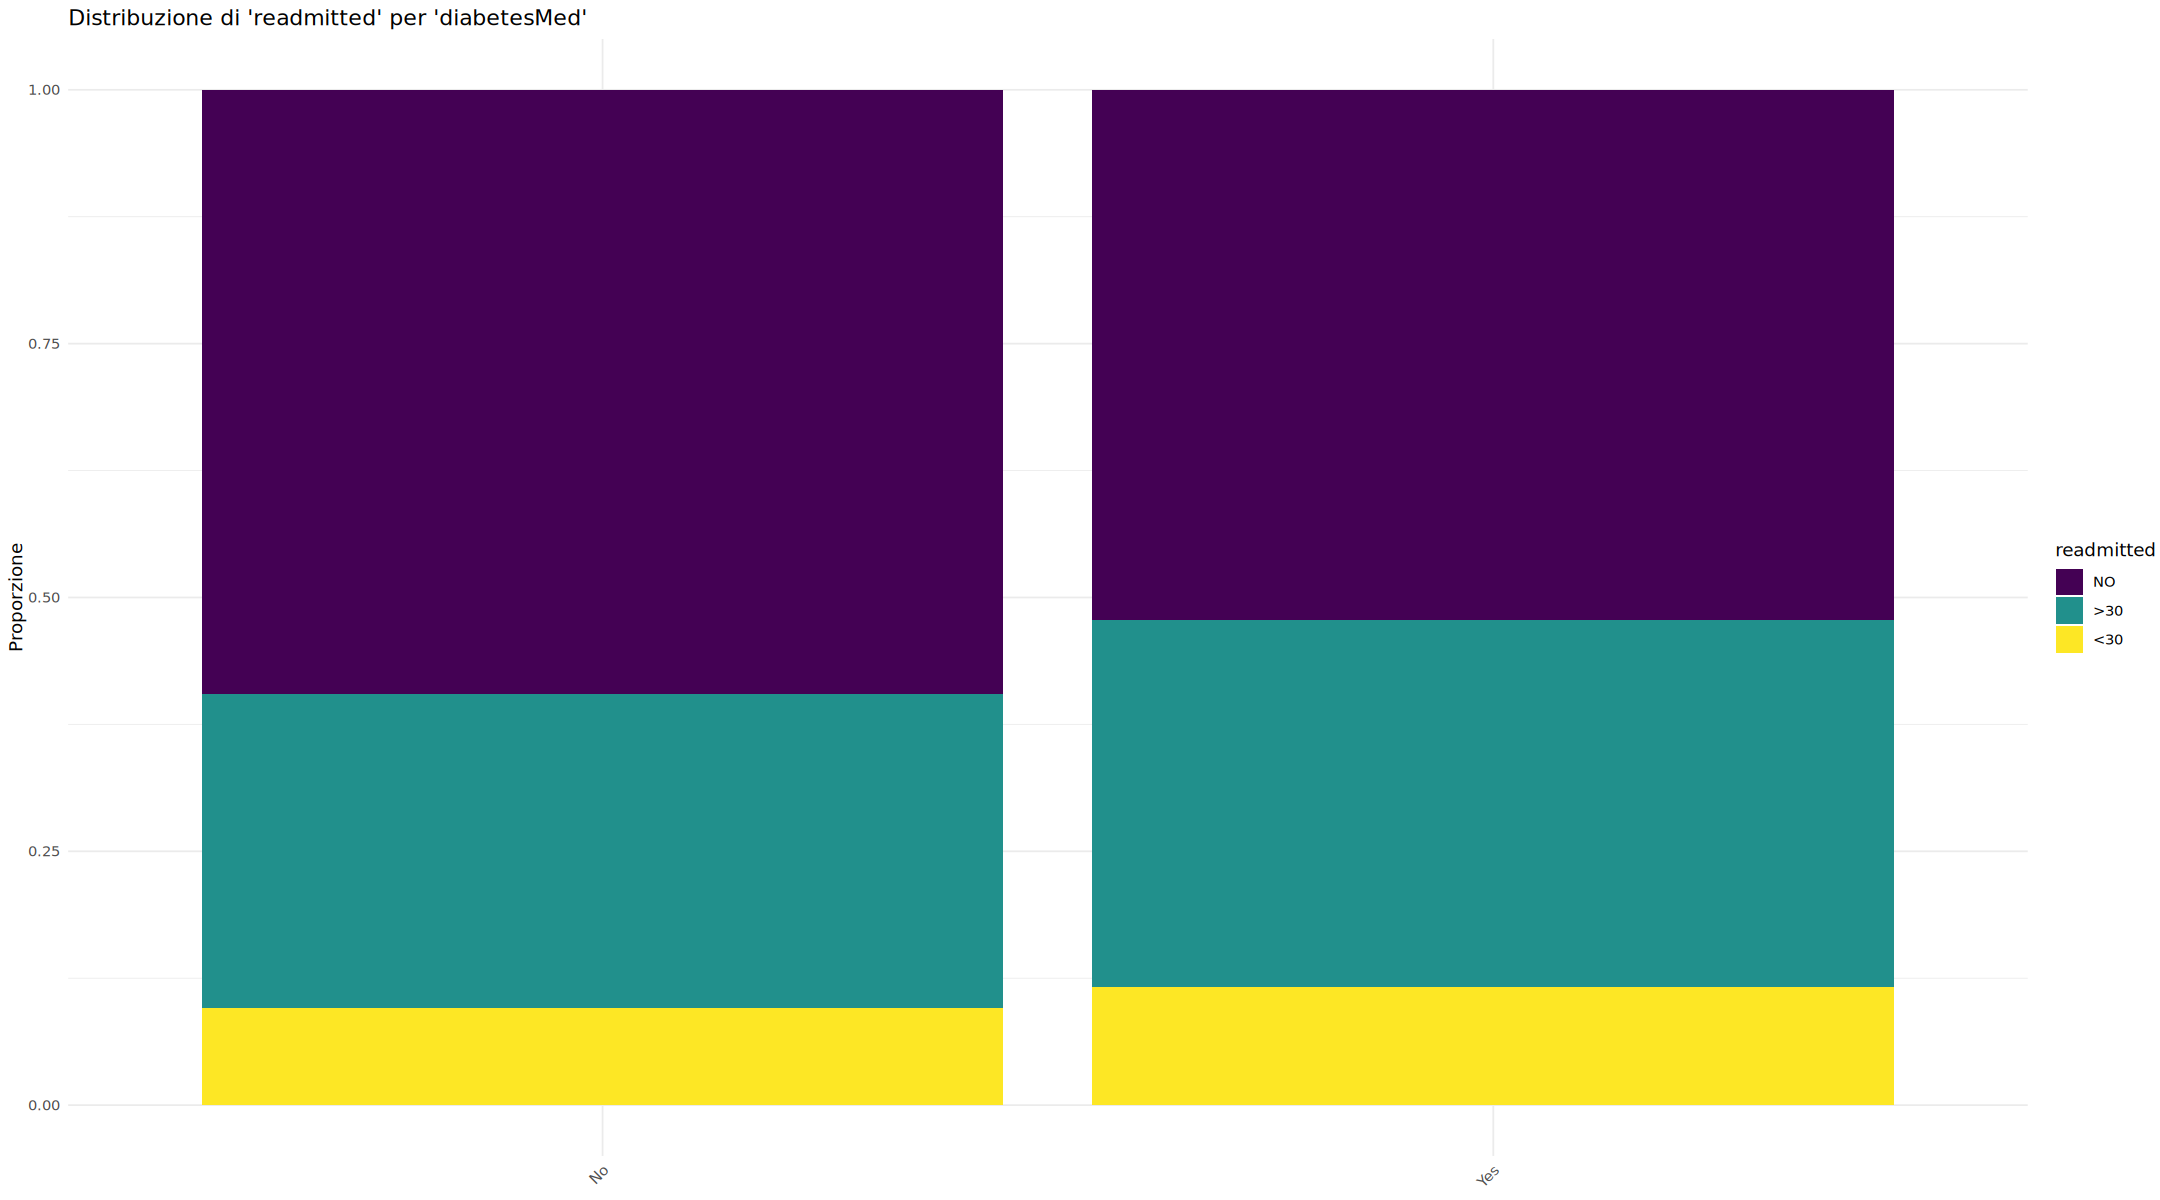

In [51]:
plot_categorical_vs_target <- function(col, dataframe, target = "readmitted", order = NULL, top_n = NULL) {
  data <- dataframe %>%
    select(all_of(c(col, target))) %>%
    drop_na()
  
  if (!is.null(top_n)) {
    top_cats <- data %>% count(!!sym(col), sort = TRUE) %>% slice_head(n = top_n) %>% pull(!!sym(col))
    data <- data %>% filter(!!sym(col) %in% top_cats)
  }
  
  if (!is.null(order)) {
    data <- data %>% mutate(!!sym(col) := factor(!!sym(col), levels = order))
  }
  
  data <- data %>% mutate(!!sym(target) := factor(!!sym(target), levels = c("NO", ">30", "<30")))
  
  p <- data %>%
    count(!!sym(col), !!sym(target)) %>%
    group_by(!!sym(col)) %>%
    mutate(prop = n / sum(n)) %>%
    ggplot(aes(x = !!sym(col), y = prop, fill = !!sym(target))) +
    geom_col(position = "stack") +
    scale_fill_viridis_d() +
    labs(y = "Proporzione",
         x = NULL,
         title = sprintf("Distribuzione di '%s' per '%s'", target, col),
         fill = target) +
    theme_minimal() +
    theme(axis.text.x = element_text(angle = 45, hjust = 1))
  
  print(p)
  
  tbl <- table(data[[col]], data[[target]])
  test <- suppressWarnings(chisq.test(tbl))
  
  cat(sprintf("Test chi-quadro '%s' vs '%s':  chi2 = %s,  p-value = %.2e\n\n",
              col, target, formatC(test$statistic, format = "f", digits = 1, big.mark = ","), test$p.value))
}

age_order <- df %>%
  drop_na(age) %>%
  distinct(age) %>%
  mutate(num = parse_number(as.character(age))) %>%
  arrange(num) %>%
  pull(age)

cat_vars <- list(
  list(col = "age", order = age_order, top_n = NULL),
  list(col = "gender", order = NULL, top_n = NULL),
  list(col = "race", order = NULL, top_n = NULL),
  list(col = "admission_type_desc", order = NULL, top_n = NULL),
  list(col = "diag_1_category", order = NULL, top_n = NULL),
  list(col = "A1Cresult", order = c("None", "Norm", ">7", ">8"), top_n = NULL),
  list(col = "max_glu_serum", order = c("None", "Norm", ">200", ">300"), top_n = NULL),
  list(col = "insulin", order = c("No", "Down", "Steady", "Up"), top_n = NULL),
  list(col = "change", order = NULL, top_n = NULL),
  list(col = "diabetesMed", order = NULL, top_n = NULL)
)

for (v in cat_vars) {
  plot_categorical_vs_target(col = v$col, dataframe = df, order = v$order, top_n = v$top_n)
}

Da questi grafici emergono in particolare: un tasso di riammissione entro 30 giorni che **cresce con l'età** fino a stabilizzarsi negli adulti, un effetto modesto ma presente di `A1Cresult` e `insulin`, e differenze più marcate legate al tipo di ammissione e alla diagnosi principale (es. le diagnosi circolatorie/respiratorie tendono ad avere tassi di riammissione più alti rispetto, ad esempio, alle diagnosi musco-scheletriche).

## Correlazione tra variabili numeriche

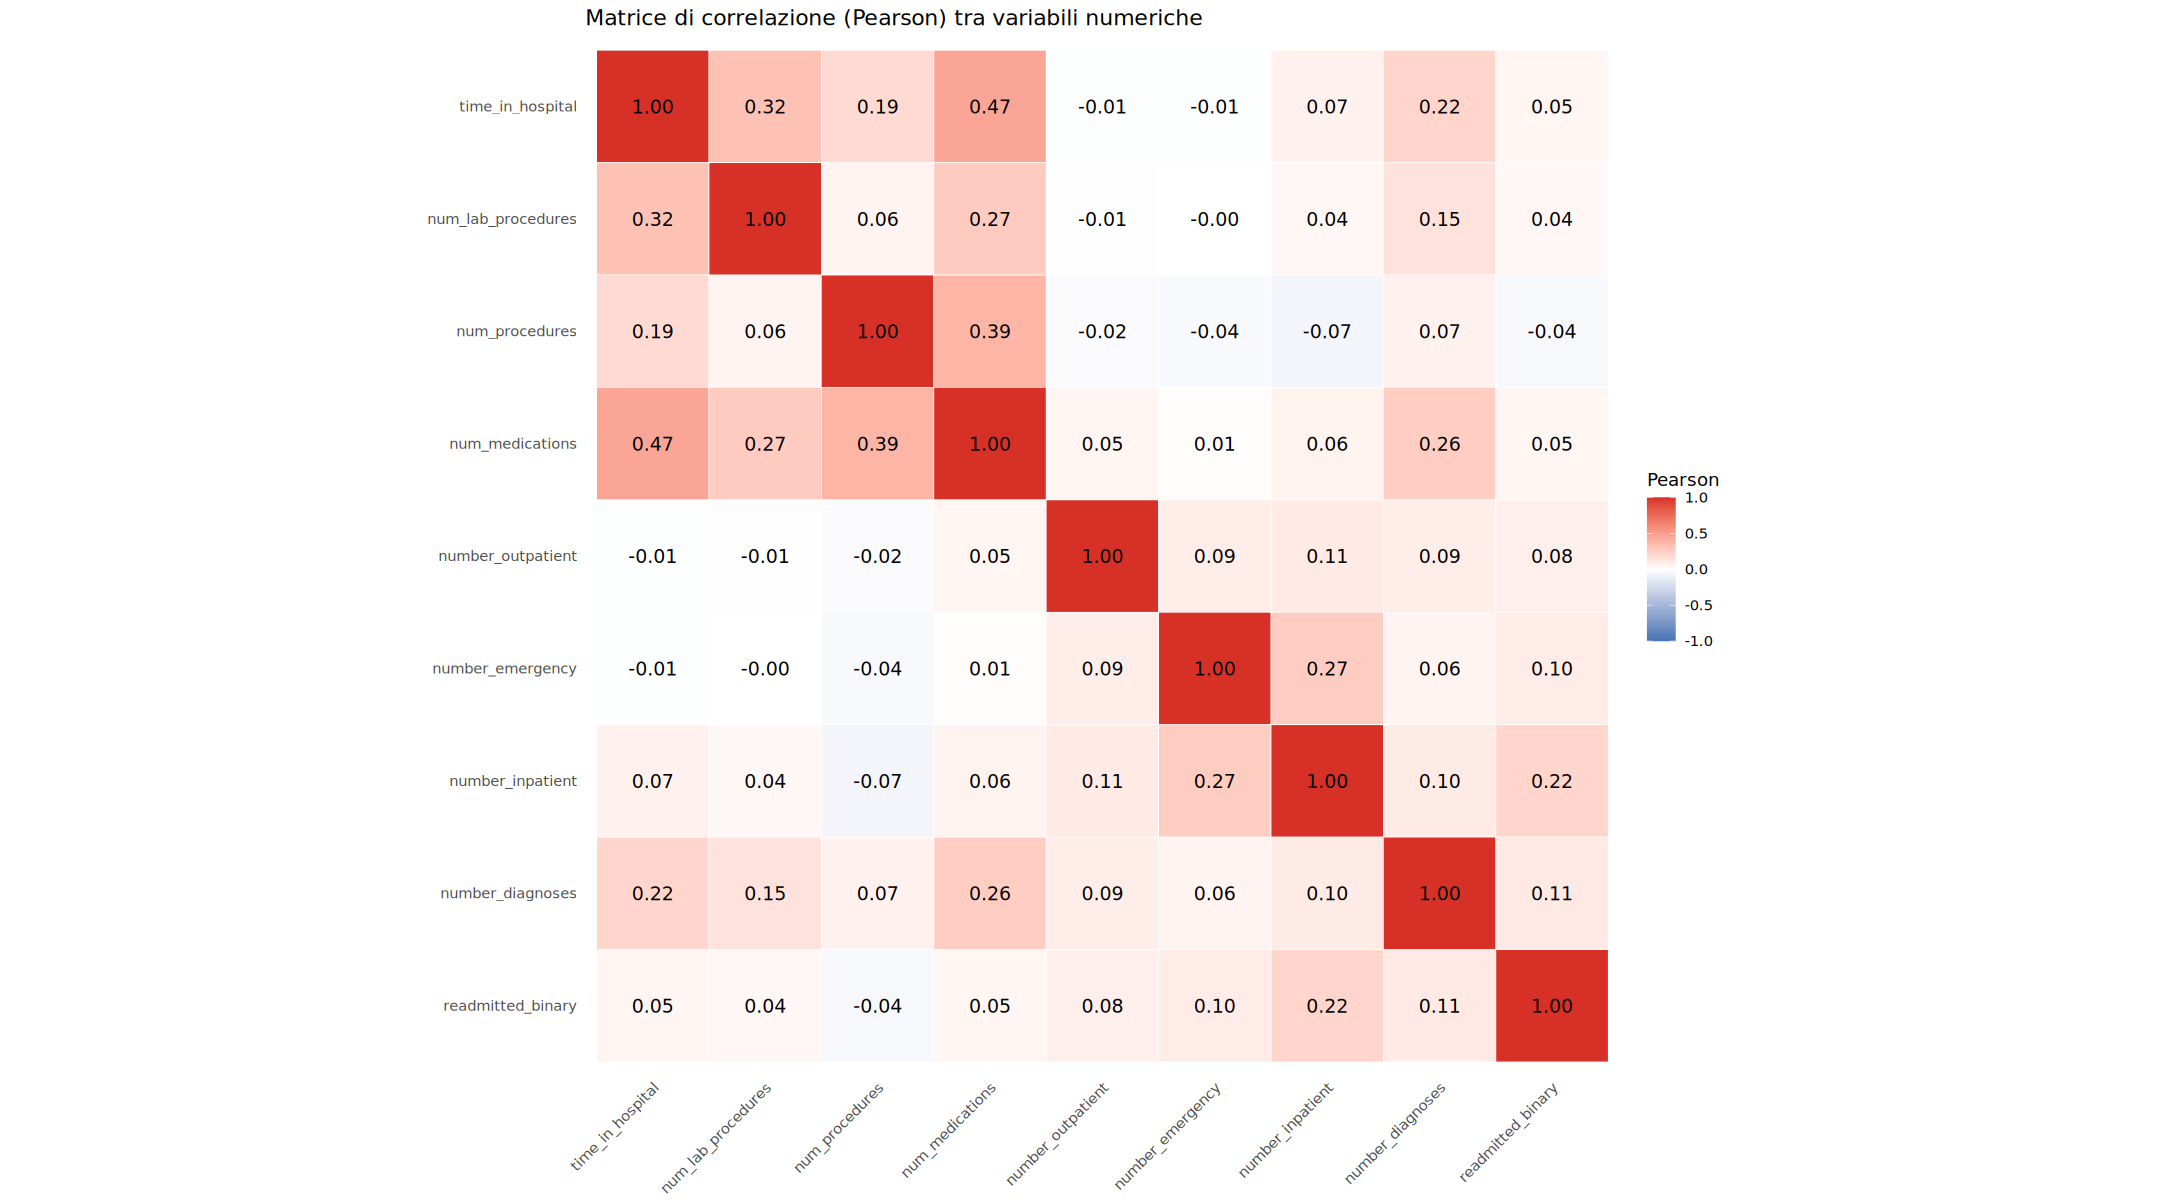

In [54]:
df <- df %>%
  mutate(readmitted_binary = ifelse(readmitted == "NO", 0, 1))

corr_cols <- c(numeric_cols, "readmitted_binary")

cor_matrix <- df %>%
  select(all_of(corr_cols)) %>%
  cor(use = "pairwise.complete.obs")

cor_long <- cor_matrix %>%
  as.data.frame() %>%
  tibble::rownames_to_column("Var1") %>%
  pivot_longer(cols = -Var1, names_to = "Var2", values_to = "correlazione") %>%
  mutate(
    Var1 = factor(Var1, levels = corr_cols),
    Var2 = factor(Var2, levels = rev(corr_cols))
  )

p_corr <- ggplot(cor_long, aes(x = Var1, y = Var2, fill = correlazione)) +
  geom_tile(color = "white") +
  geom_text(aes(label = sprintf("%.2f", correlazione)), size = 4) +
  scale_fill_gradient2(low = "#4575b4", mid = "white", high = "#d73027", 
                       midpoint = 0, limit = c(-1, 1), name = "Pearson") +
  coord_fixed() +
  labs(title = "Matrice di correlazione (Pearson) tra variabili numeriche",
       x = NULL,
       y = NULL) +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 45, hjust = 1),
        panel.grid.major = element_blank())

p_corr

Le correlazioni lineari tra le variabili numeriche sono generalmente **basse** (al massimo intorno a 0,3-0,4 tra variabili concettualmente vicine come `num_medications` e `time_in_hospital`/`num_procedures`): non emergono problemi seri di multicollinearità. La correlazione di ciascuna variabile con `readmitted_binary` è debole se considerata singolarmente — coerente con quanto visto nei boxplot, dove le differenze più marcate riguardavano soprattutto la *forma* della distribuzione più che la sola media.

## Pazienti con encounter multipli e riammissione

I pazienti con più ricoveri nel dataset hanno una probabilità di riammissione diversa rispetto a chi compare una sola volta?

ha_encounter_multipli,NO,>30,<30
<lgl>,<dbl>,<dbl>,<dbl>
FALSE,0.780,0.180,0.040
TRUE,0.259,0.546,0.195


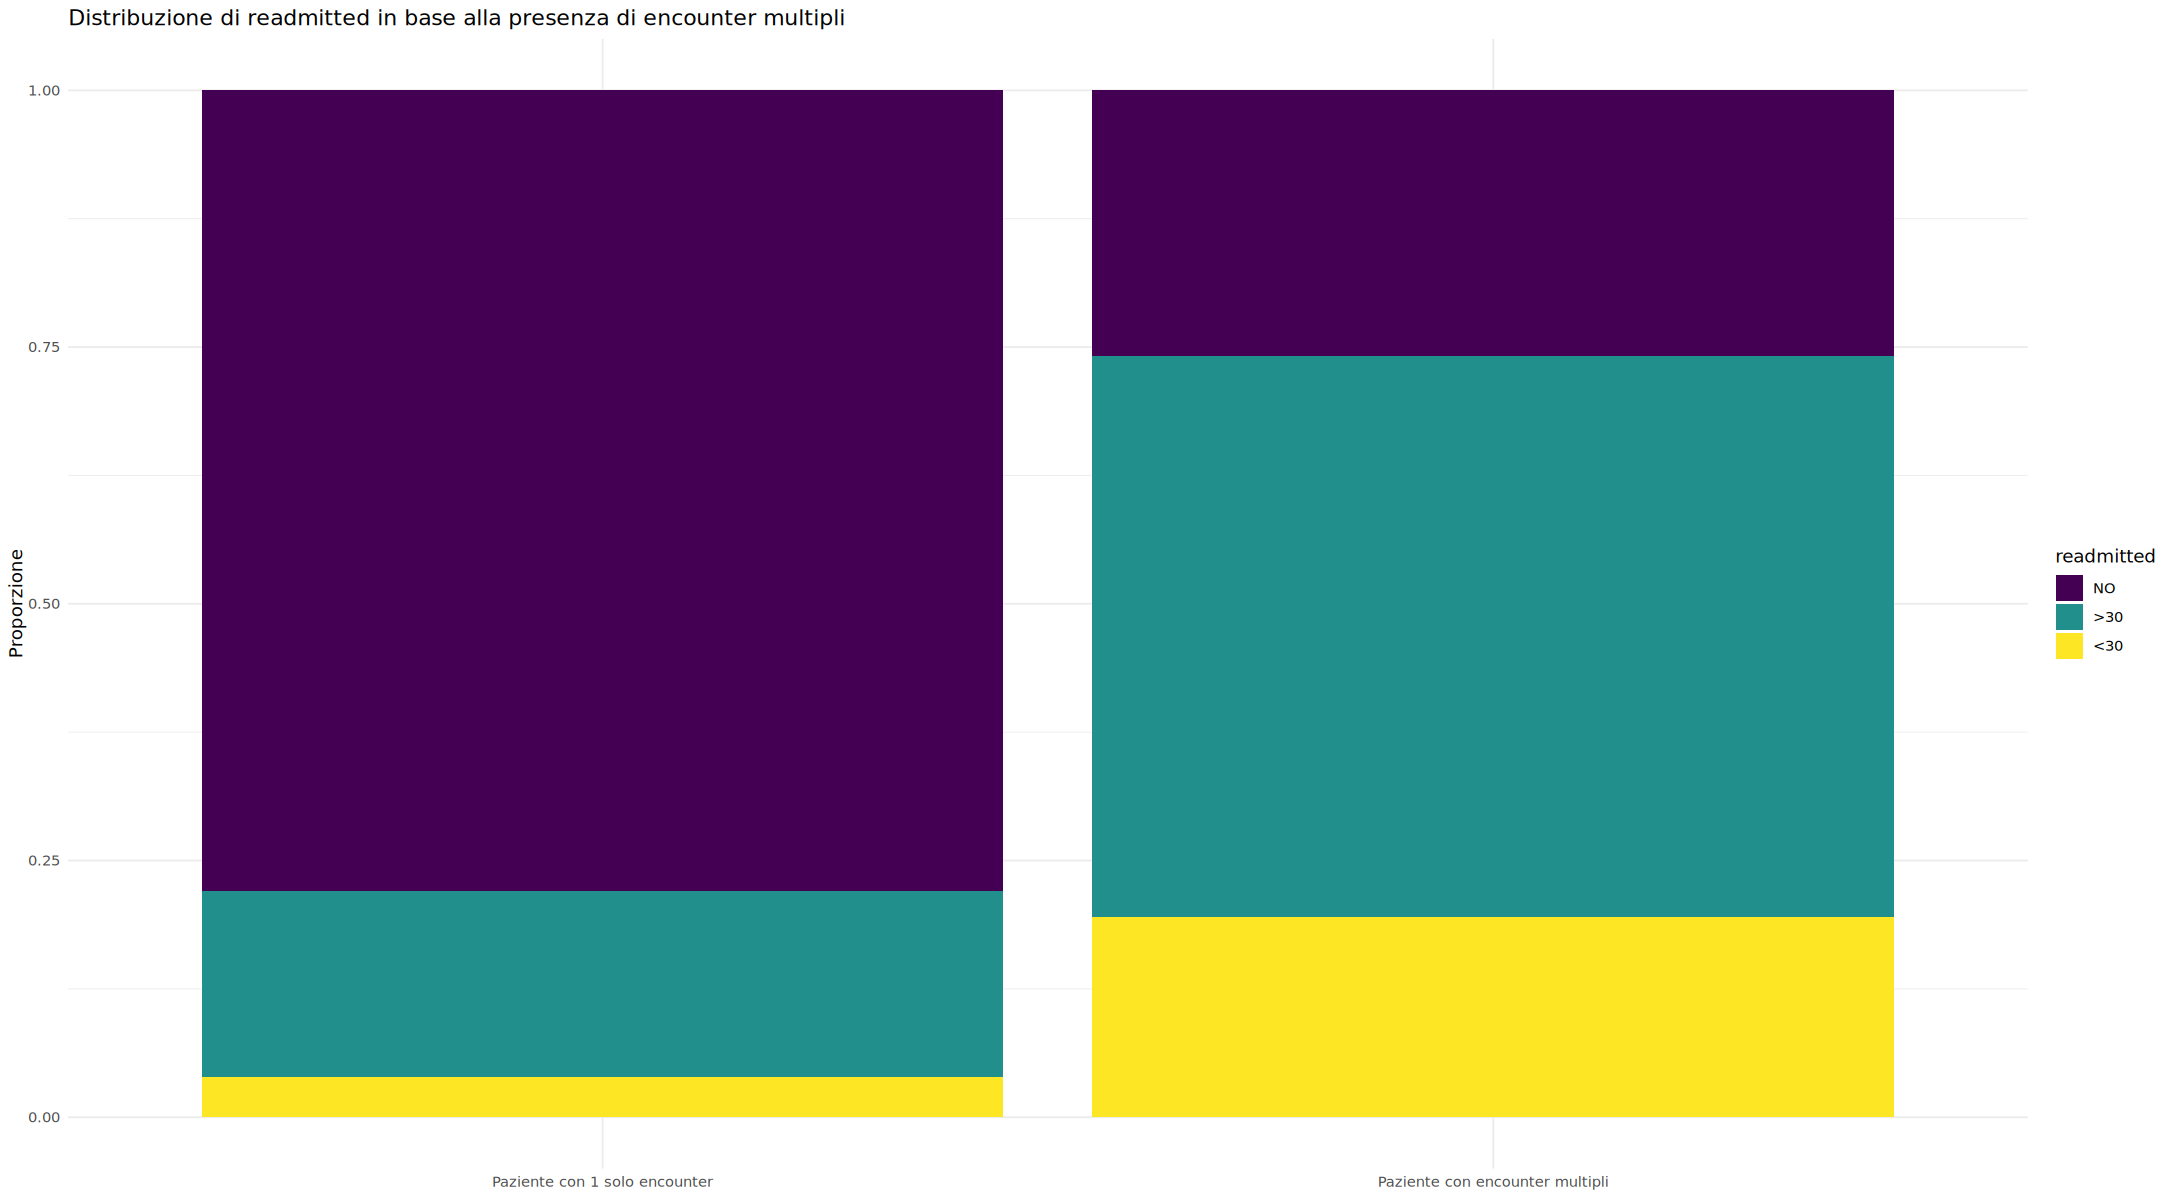

In [58]:
df <- df %>%
  add_count(patient_nbr, name = "n_encounters_patient") %>%
  mutate(ha_encounter_multipli = n_encounters_patient > 1)

ct <- df %>%
  count(ha_encounter_multipli, readmitted) %>%
  group_by(ha_encounter_multipli) %>%
  mutate(prop = n / sum(n)) %>%
  ungroup() %>%
  select(-n) %>%
  pivot_wider(names_from = readmitted, values_from = prop, values_fill = 0) %>%
  select(ha_encounter_multipli, any_of(c("NO", ">30", "<30")))

ct %>% mutate(across(where(is.numeric), ~ round(.x, 3)))

p_multi <- df %>%
  count(ha_encounter_multipli, readmitted) %>%
  group_by(ha_encounter_multipli) %>%
  mutate(prop = n / sum(n)) %>%
  ungroup() %>%
  mutate(readmitted = factor(readmitted, levels = c("NO", ">30", "<30"))) %>%
  ggplot(aes(x = factor(ha_encounter_multipli), y = prop, fill = readmitted)) +
  geom_col(position = "stack") +
  scale_x_discrete(labels = c("FALSE" = "Paziente con 1 solo encounter", 
                              "TRUE" = "Paziente con encounter multipli")) +
  scale_fill_viridis_d() +
  labs(title = "Distribuzione di readmitted in base alla presenza di encounter multipli",
       x = NULL,
       y = "Proporzione",
       fill = "readmitted") +
  theme_minimal() +
  theme(legend.position = "right")

p_multi

La differenza è marcata: i pazienti che nel dataset compaiono con **più di un encounter** hanno una probabilità di riammissione entro 30 giorni quasi 5 volte superiore (circa 19,5%) rispetto a chi compare una sola volta (circa 4%). Questo è in parte un effetto quasi tautologico (chi viene riammesso, per definizione, genera un nuovo encounter e quindi compare più volte), ma confirma comunque quanto sia fondamentale.

## Analisi multivariata: tasso di riammissione per età e tipo di ammissione

Come esempio di analisi multivariata, osserviamo come il tasso di riammissione entro 30 giorni varii contemporaneamente in funzione di **età** e **tipo di ammissione**.

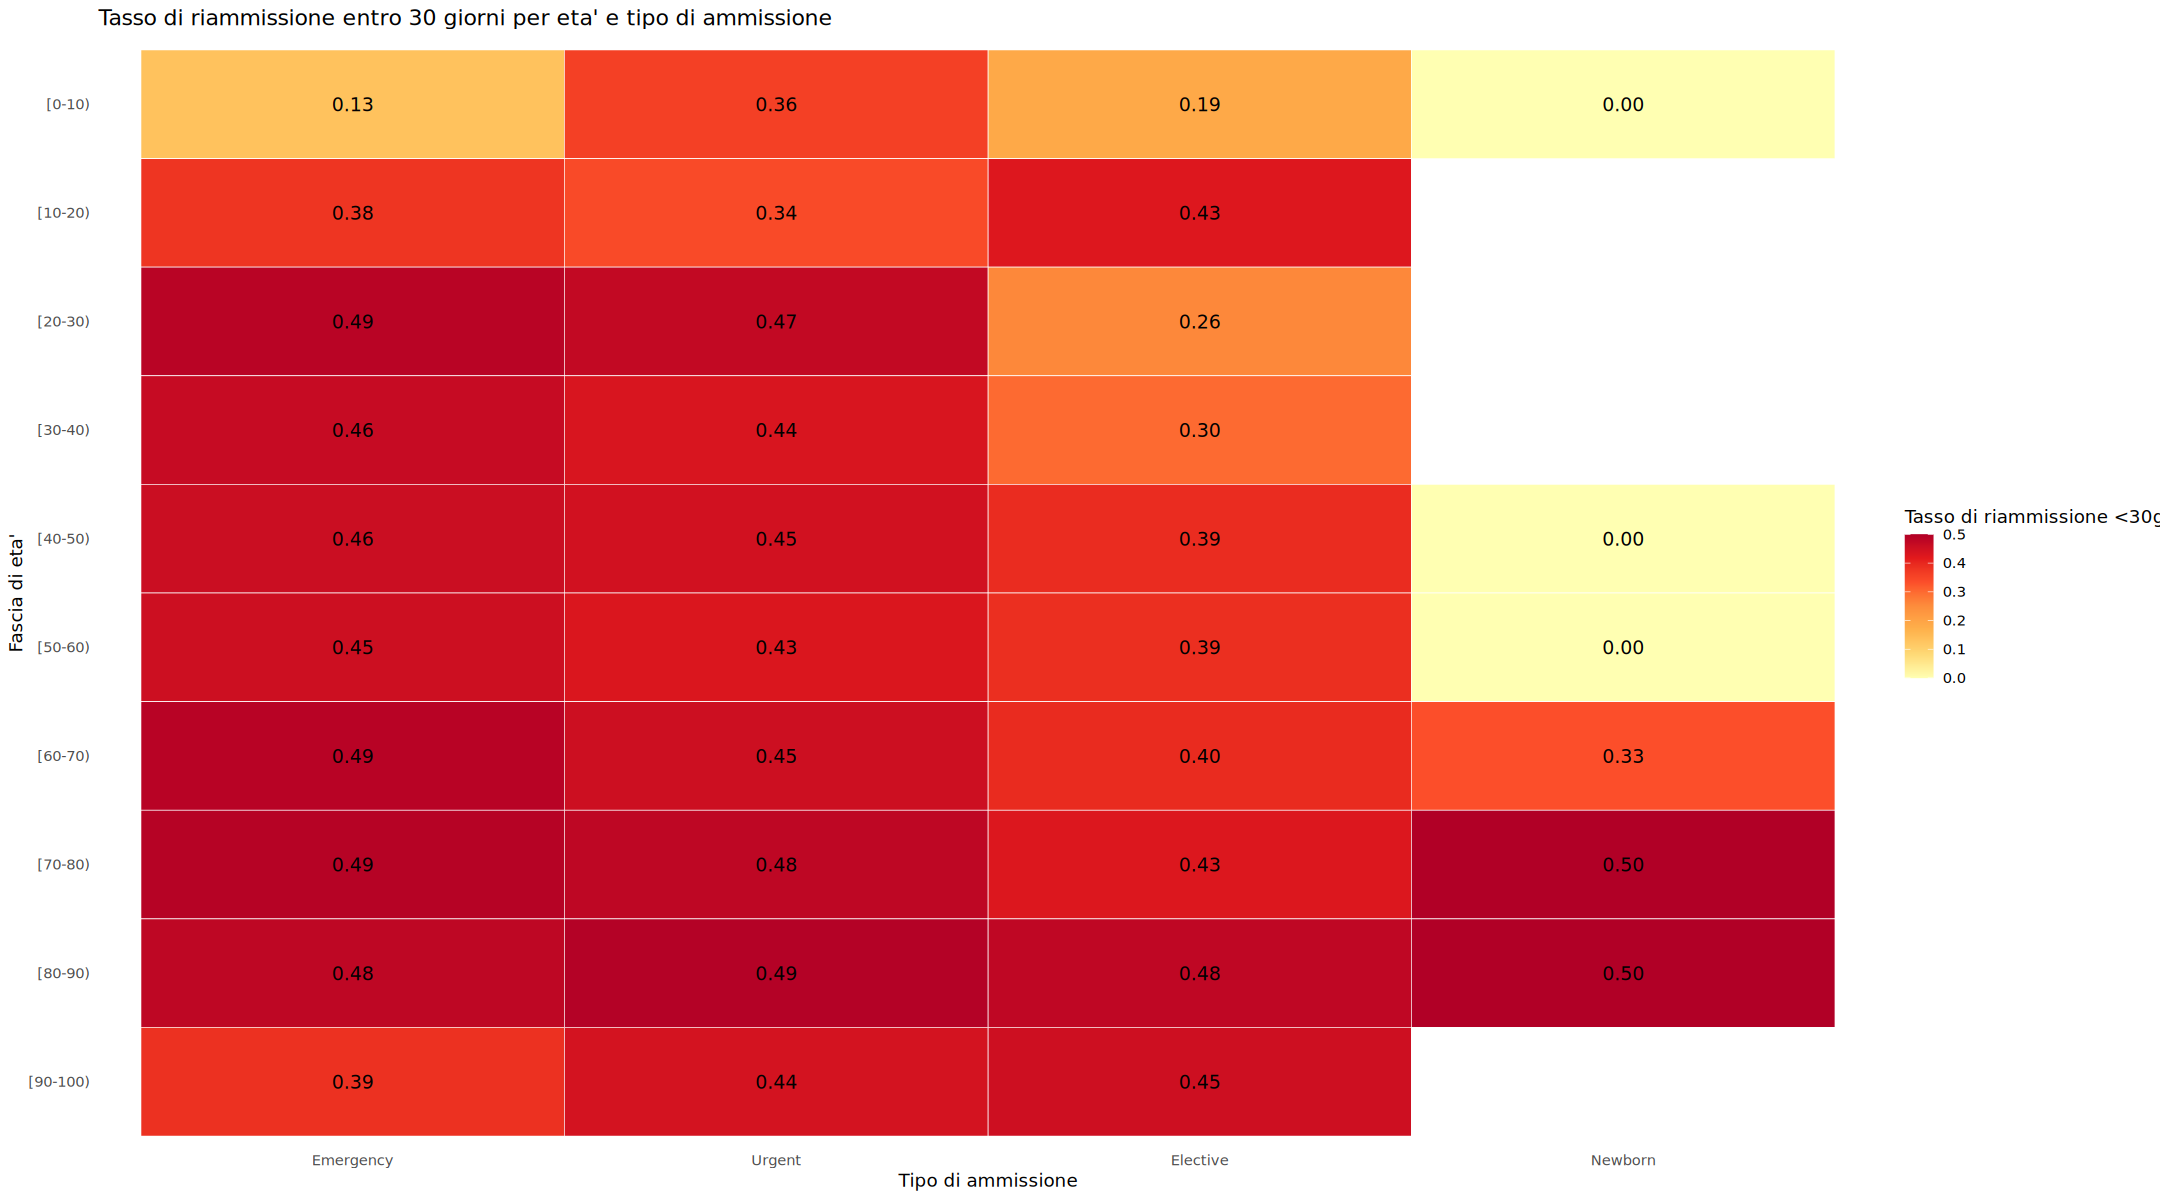

In [59]:
main_types <- c("Emergency", "Urgent", "Elective", "Newborn")

df_heatmap <- df %>%
  filter(admission_type_desc %in% main_types) %>%
  group_by(age, admission_type_desc) %>%
  summarise(tasso_riammissione = mean(readmitted_binary, na.rm = TRUE), .groups = "drop") %>%
  mutate(
    age = factor(age, levels = age_order),
    admission_type_desc = factor(admission_type_desc, levels = main_types)
  )

p_heat <- ggplot(df_heatmap, aes(x = admission_type_desc, y = age, fill = tasso_riammissione)) +
  geom_tile(color = "white") +
  geom_text(aes(label = sprintf("%.2f", tasso_riammissione)), size = 4) +
  scale_fill_distiller(palette = "YlOrRd", direction = 1, na.value = "white",
                       name = "Tasso di riammissione <30gg") +
  scale_y_discrete(limits = rev) + 
  labs(title = "Tasso di riammissione entro 30 giorni per eta' e tipo di ammissione",
       x = "Tipo di ammissione",
       y = "Fascia di eta'") +
  theme_minimal() +
  theme(panel.grid = element_blank())

p_heat

Il tasso di riammissione entro 30 giorni è generalmente più alto per le ammissioni **Urgent** ed **Emergency** rispetto a **Elective**, in tutte le fasce di età, e tende ad aumentare progressivamente con l'età fino a stabilizzarsi negli over-60. Le ammissioni **Newborn** mostrano valori più erratici, in parte per la scarsa numerosità di questa categoria nel dataset

## Sintesi finale e considerazioni per il preprocessing

Questa EDA evidenzia alcuni punti chiave del dataset *Diabetes 130-US Hospitals*. Il dataset è di dimensioni considerevoli (101.766 encounter, 50 colonne) ma rappresenta solo 71.518 pazienti distinti: una parte rilevante (circa il 25%) compare con ricoveri ripetuti. La variabile target `readmitted` è sbilanciata, con la classe di maggiore interesse clinico (riammissione entro 30 giorni) che rappresenta solo l'11% dei casi.

Sul fronte della qualità dei dati, sono stati identificati diversi aspetti da gestire in fase di preprocessing: una colonna (`weight`) quasi totalmente mancante e di fatto inutilizzabile; due colonne di farmaci (`examide`, `citoglipton`) a varianza nulla, da eliminare; un'insidia di parsing (più di tipo tecnico) per cui alcune delle classiche librerie convertono automaticamente in `NaN` la stringa `"None"` usata da `max_glu_serum` e `A1Cresult` per indicare "esame non eseguito" (una categoria informativa, non un dato mancante); un sottogruppo di circa 3.000 encounter (2,4%) con esito decesso o trasferimento in hospice, per i quali il concetto di riammissione non è clinicamente sensato.

Dal punto di vista del contenuto informativo, le variabili più legate alla riammissione sembrano essere quelle che riflettono l'utilizzo recente del sistema sanitario (`number_inpatient`, `number_emergency`, `number_outpatient`), il tipo e la fonte di ammissione, la categoria diagnostica principale (in particolare le diagnosi circolatorie e respiratorie) e, in misura minore, l'età del paziente e gli esiti dei test di laboratorio (A1C, glicemia). Le 23 variabili sui farmaci hanno un contenuto informativo molto concentrato su pochissime sostanze (soprattutto insulina e metformina), con la maggior parte delle altre quasi costanti.

In una eventuale fase successiva si potrebbe considerare: l'eliminazione o trasformazione delle colonne a missingness molto elevata o a varianza nulla; il raggruppamento dei codici diagnostici ICD-9 in categorie cliniche (come fatto in questa EDA); la mappatura dei codici amministrativi nelle loro descrizioni testuali; l'esclusione degli encounter con esito decesso/hospice; e una strategia esplicita per gestire lo sbilanciamento della classe target.